# QUANT Interval-Selection Experiment Analysis

**How the numbers are built**

1. Only runs with `status == "ok"` are used, and only resamples that succeeded for **every** configuration (so every comparison is paired on identical train/test splits).
2. For each dataset × configuration × classifier, accuracy, feature count and timings are **averaged over the resamples** (timings can switch to the median with `TIME_AGG`).
3. Every configuration is compared to the baseline *within the same dataset*, giving per-dataset accuracy differences, relative error reduction, and feature/time reductions (positive = better than baseline).
4. Datasets are split into size groups (equal-count percentile bins) and into dataset types (Image, Sensor, Motion, ...), and the group analyses are repeated for both, to see where a configuration helps or hurts.

> Use a separate results CSV per configuration. The `run.py` resume key is dataset + resample + classifier, so sharing one output file across configurations can cause runs to be skipped.

# Experiment description

## What experiments are based on
Features in quant are taken as quantile values taken from intervals of the original datasets. Intervals of different sizes are taken for each dataset by taking intervals at different depths. At depth $d$ for any dataset sample, the number of intervals $I_n$ taken from the dataset is calculated as:
$$
I_{n} = 2^{d-1}
$$
Where the length of each interval $m$ for a sample of length $n$ is:

$$
m = \frac{n}{2^{d-1}}
$$

In the original paper, shift intervals were also taken at each depth. These intervals had the same interval length as the original intervals at this depth, but one less it taken than in the normal intervals, and the interval start position are shifted by half an interval width, as shown below.

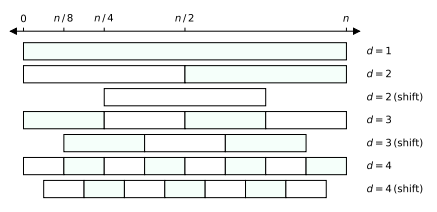

In the original paper, intervals were taken at every depth up to a maximum depth $D$ for a sample length $n$ calculated as follows:

$$
D = min(6, log_2 n + 1)
$$

## Experiments Conducted
These experiments involved reducing the number of intervals taken in the original paper by not calculating intervals or their quantile values as certain depths. These experiments conducted are described in the table below. This table also includes the extent of experiments conducted, and initial results.

| Experiment Name | Description | Experiments Conducted | Results |
| --------------- | ----------- | --------------------- | ------- |
| depths_1_6 | Baseline with the same intervals as the original | Ran for all datasets (142) and resamples (30) | N/a |
| no_depth_6 | This test took intervals at the same depths as the baseline without depth 6 intervals. | Ran for all datasets (142) and resamples (30) | Minimal accuracy difference across dataset compared to baseline, deemed insignificant according to Friedman and Wilcoxon signed-rank testing and reduced feature count and training time |
| no_depth_5_6 | This test took intervals at the same depths as the baseline without depths 5 and 6 intervals | Ran for all datasets (142) and resamples (30) | Small accuracy difference across dataset compared to baseline, deemed significant according to Friedman and Wilcoxon signed-rank testing but further reduced feature count and training time compared the original |
| no_depth_4_5_6 | This test took intervals at the same depths as the baseline without depths 4, 5 and 6 intervals | Ran for all datasets (142) and resamples (30) | More substantial accuracy difference across dataset compared to baseline, deemed significant according to Friedman and Wilcoxon signed-rank testing and didn't reduce the feature count and training time compared much compared to other methods|
| odd_depths | This test took intervals for every second depth value (1, 3, 5) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Small accuracy difference across dataset compared to baseline, deemed significant according to Friedman and Wilcoxon signed-rank testing but had the largest feature count and training time reduction compared to the original |
| alternating_depths | This test took normal intervals for every second depth value (1, 3, 5) and shift intervals for every other depth value (2, 4, 6) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Accuracy reduction across dataset compared to baseline, deemed significant according to Friedman and Wilcoxon signed-rank testing. Although reasonable feature count and training time reduction, better results came from no_depths_5_6 (better accuracy) and even depths (larger feature reduction), so doesn’t warrant further consideration |
| even_depths | This test took intervals for every second depth value (2, 4, 6) to the same maximum as in the baseline | Ran for all datasets (142) and resamples (30) | Accuracy reduction across dataset compared to baseline, deemed significant according to Friedman and Wilcoxon signed-rank testing. Although reasonable feature count and training time reduction, better accuracy and feature count reduction came from other experiments so doesn’t warrant further consideration |
| no_depth_1 | This test took intervals at the same depths as the baseline without depth 1 intervals | Ran for all datasets (142) and resamples (30) | Larger reduction in accuracy compared to baseline, deemed significant according to Friedman and Wilcoxon signed-rank testing and didn't reduce feature count or training time substantially enough to warrant further consideration |
| no_depth_1_2 | This test took intervals at the same depths as the baseline without depths 1 or 2 intervals | Ran for all datasets (142) and resamples (30) | Largest reduction in accuracy compared to baseline, deemed significant according to Friedman and Wilcoxon signed-rank testing and didn't reduce feature count or training time substantially enough to warrant further consideration |

This also included an analysis removing each depths individually (no_depth_i for i in 1:6). This was done to try to assess the importance of each depth for classification, not in an attempt to improve overall performance.

Further analysis of results can be found at the end of this notebook.

## 1. Configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from scipy import stats

# --- Inputs -----------------------------------------------------------------
RESULTS_DIR = Path("../results")

# CSV filename stem -> display label. Each stem must have <RESULTS_DIR>/<stem>.csv
CONFIG_LABELS = {
    "depths_1_6_baseline": "Baseline (QUANT)",
    "no_depth_6": "Depth 6 excluded",
    "no_depth_5_6": "Depth 5 and 6 excluded",
    "no_depth_4_5_6": "Depth 4, 5 and 6 excluded",
    "alternating_depths": "Alternating normal/shift",
    "odd_depths": "Odd depths (1, 3, 5)",
    "even_depths": "Even depths (2, 4, 6)",
    "no_depth_1": "Depth 1 excluded",
    "no_depth_1_2": "Depth 1 and 2 excluded"
}
BASELINE = "Baseline (QUANT)"   # must be one of the labels above

CLASSIFIERS = None                    # e.g. ["extratrees"]; None = all found in the CSVs

# --- Aggregation / statistics -----------------------------------------------
TIME_AGG = "mean"                     # how timings are combined over resamples: "mean" or "median"
TIE_TOL = 1e-12                       # |accuracy difference| below this counts as a tie
N_BOOTSTRAP = 5000                    # bootstrap resamples for the mean-difference confidence interval
ERROR_EPS = 0.001                     # pseudo-error added to BOTH errors in the smoothed error ratio (0.001 = 0.1 pp)
                                      # ideally ~0.5 / n_test; try 0.0005 and 0.002 to check the conclusions do not change
SEED = 0

# --- Dataset-size groups ----------------------------------------------------
N_SIZE_GROUPS = 5                     # equal-count percentile bins (5 = quintiles)
# Optional CSV with one row per dataset: dataset, n_train, series_length[, n_channels]
# (or a single precomputed `size` column). If None, the notebook looks for such
# columns in the results CSVs, and otherwise falls back to a runtime-based proxy.
SIZE_METADATA_CSV = None              # e.g. Path("../dataset_metadata.csv")

# --- Dataset types ----------------------------------------------------------
TYPES_CSV = Path("../improvedQuant/dataSetLists/dataset_types.csv")   # one row per dataset: dataset, type, type_group, ...
TYPE_COLUMN = "type_group"            # "type_group" (rare types merged into Other) or "type" (original archive types)
MIN_DATASETS_PER_GROUP = 8            # groups with fewer datasets get no CD diagram

print("Results directory:", RESULTS_DIR.resolve())

Results directory: C:\Users\davyt\quant-reproduction\results


## 2. Load and validate

Missing or malformed files are reported rather than silently skipped, and the notebook stops if the baseline is not available.

In [2]:
REQUIRED = {
    "dataset", "resample", "classifier", "accuracy", "status", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
}
NUMERIC = [
    "accuracy", "balanced_accuracy", "n_features",
    "time_transform_train", "time_fit", "time_transform_test", "time_predict",
]

frames, load_issues = [], []
for stem, label in CONFIG_LABELS.items():
    path = RESULTS_DIR / f"{stem}.csv"
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        load_issues.append({"file": str(path), "issue": f"Could not read: {exc}"})
        continue
    missing = sorted(REQUIRED - set(frame.columns))
    if missing:
        load_issues.append({"file": str(path), "issue": "Missing columns: " + ", ".join(missing)})
        continue
    frame["configuration"] = label
    for col in NUMERIC:
        frame[col] = pd.to_numeric(frame[col], errors="coerce") if col in frame else np.nan
    frame["resample"] = pd.to_numeric(frame["resample"], errors="coerce")
    frame["status"] = frame["status"].fillna("").astype(str)
    frames.append(frame)

if load_issues:
    display(pd.DataFrame(load_issues))
if not frames:
    raise FileNotFoundError("No usable result CSVs found. Check RESULTS_DIR and CONFIG_LABELS.")

results = pd.concat(frames, ignore_index=True, sort=False)
if BASELINE not in set(results["configuration"]):
    raise ValueError(f"Baseline '{BASELINE}' was not loaded. Loaded: {sorted(results['configuration'].unique())}")
if CLASSIFIERS is not None:
    results = results[results["classifier"].isin(CLASSIFIERS)].copy()

# Duplicated runs would double-count a resample, so keep the first and say so.
run_key = ["configuration", "dataset", "classifier", "resample"]
n_dup = int(results.duplicated(run_key).sum())
if n_dup:
    print(f"WARNING: dropped {n_dup} duplicated runs (same configuration/dataset/classifier/resample).")
    results = results.drop_duplicates(run_key, keep="first")

results["is_success"] = results["status"].str.lower().eq("ok") & results["accuracy"].notna()

print(f"Loaded {len(results):,} runs from {len(frames)} file(s); "
      f"{int(results['is_success'].sum()):,} successful.")
display(
    results.groupby(["configuration", "classifier", "status"]).size()
    .rename("runs").reset_index()
)

Loaded 38,340 runs from 9 file(s); 38,340 successful.


,configuration,classifier,status,runs
0,Alternating normal/shift,extratrees,ok,4260
1,Baseline (QUANT),extratrees,ok,4260
2,Depth 1 and 2 excluded,extratrees,ok,4260
3,Depth 1 excluded,extratrees,ok,4260
4,"Depth 4, 5 and 6 excluded",extratrees,ok,4260
5,Depth 5 and 6 excluded,extratrees,ok,4260
6,Depth 6 excluded,extratrees,ok,4260
7,"Even depths (2, 4, 6)",extratrees,ok,4260
8,"Odd depths (1, 3, 5)",extratrees,ok,4260


## 3. Paired runs and per-dataset averages

A resample is kept only if the same dataset/classifier/resample succeeded in **all** configurations, so every configuration is averaged over the same splits. The table `table` has one row per dataset × configuration × classifier and is used by everything below.

In [3]:
ok = results.loc[results["is_success"]].copy()
ok["time_train_total"] = ok["time_transform_train"] + ok["time_fit"]
ok["time_test_total"] = ok["time_transform_test"] + ok["time_predict"]

# Keep only resamples that succeeded in every configuration.
all_configs = sorted(ok["configuration"].unique())
pair_key = ["dataset", "classifier", "resample"]
n_cfg = ok.groupby(pair_key)["configuration"].transform("nunique")
paired = ok.loc[n_cfg == len(all_configs)].copy()
print(f"Configurations: {all_configs}")
print(f"Successful runs: {len(ok):,} -> kept {len(paired):,} runs in complete resample sets "
      f"({len(ok) - len(paired):,} dropped).")

TIME_COLS = ["time_transform_train", "time_fit", "time_transform_test", "time_predict",
             "time_train_total", "time_test_total"]
agg_spec = {
    "accuracy": ("accuracy", "mean"),
    "balanced_accuracy": ("balanced_accuracy", "mean"),
    "n_features": ("n_features", "mean"),
    "n_resamples": ("resample", "nunique"),
}
agg_spec.update({c: (c, TIME_AGG) for c in TIME_COLS})

table = (
    paired.groupby(["dataset", "classifier", "configuration"], as_index=False)
    .agg(**agg_spec)
)
table["error"] = 1 - table["accuracy"]

# Coverage check: every dataset should appear in every configuration with the same resample count.
cov = table.groupby(["classifier", "configuration"]).agg(
    datasets=("dataset", "nunique"),
    resamples_min=("n_resamples", "min"),
    resamples_median=("n_resamples", "median"),
    resamples_max=("n_resamples", "max"),
)
display(cov)
print(f"{table['dataset'].nunique()} datasets in the analysis table.")

Configurations: ['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Successful runs: 38,340 -> kept 38,340 runs in complete resample sets (0 dropped).


datasets  resamples_min  \
classifier configuration                                        
extratrees Alternating normal/shift        142             30   
           Baseline (QUANT)                142             30   
           Depth 1 and 2 excluded          142             30   
           Depth 1 excluded                142             30   
           Depth 4, 5 and 6 excluded       142             30   
           Depth 5 and 6 excluded          142             30   
           Depth 6 excluded                142             30   
           Even depths (2, 4, 6)           142             30   
           Odd depths (1, 3, 5)            142             30   

                                      resamples_median  resamples_max  
classifier configuration                                               
extratrees Alternating normal/shift               30.0             30  
           Baseline (QUANT)                       30.0             30  
           Depth 1 and 2 excluded                 30.0             30  
           Depth 1 excluded                       30.0             30  
           Depth 4, 5 and 6 excluded              30.0             30  
           Depth 5 and 6 excluded                 30.0             30  
           Depth 6 excluded                       30.0             30  
           Even depths (2, 4, 6)                  30.0             30  
           Odd depths (1, 3, 5)                   30.0             30

142 datasets in the analysis table.


## 4. Dataset-size groups

QUANT's cost scales with the number of training cases × series length × channels, so that is the preferred size measure. The notebook uses, in order:

1. `SIZE_METADATA_CSV` (or columns in the results CSVs) with `n_train` and `series_length` (and optionally `n_channels`);
2. a single `size` column, if present;
3. otherwise a **runtime proxy**: the geometric mean of `time_transform_train` across configurations. This is a reasonable stand-in for data volume, but it is measured, so noisy timings can nudge a dataset into a neighbouring group. Use real metadata for anything you plan to publish.

Groups are equal-count percentile bins (`N_SIZE_GROUPS`), so each group has roughly the same number of datasets.

In [4]:
SIZE_ALIASES = {
    "n_train": ["n_train", "n_train_cases", "n_cases_train", "train_size"],
    "length": ["series_length", "n_timepoints", "n_timesteps", "length"],
    "channels": ["n_channels", "n_dimensions", "n_dims"],
    "size": ["size", "dataset_size"],
}

def find_col(df, key):
    return next((c for c in SIZE_ALIASES[key] if c in df.columns), None)

def size_from_frame(df):
    # Return (Series indexed by dataset, description) or None if no usable columns.
    per_dataset = df.groupby("dataset").first()
    n_train, length, chans = (find_col(per_dataset, k) for k in ("n_train", "length", "channels"))
    if n_train and length:
        size = per_dataset[n_train] * per_dataset[length]
        if chans:
            size = size * per_dataset[chans].fillna(1)
        return size, "n_train × series_length" + (" × n_channels" if chans else "")
    size_col = find_col(per_dataset, "size")
    if size_col:
        return per_dataset[size_col], size_col
    return None

size_info = None
if SIZE_METADATA_CSV is not None:
    size_info = size_from_frame(pd.read_csv(SIZE_METADATA_CSV))
    if size_info is None:
        raise ValueError("SIZE_METADATA_CSV needs n_train + series_length columns, or a `size` column.")
if size_info is None:
    size_info = size_from_frame(results)

if size_info is not None:
    dataset_size, SIZE_DESC = size_info
    dataset_size = dataset_size.reindex(table["dataset"].unique())
    if dataset_size.isna().any():
        raise ValueError(f"No size for datasets: {list(dataset_size.index[dataset_size.isna()])[:10]}")
else:
    SIZE_DESC = "runtime proxy (geometric mean of training-transform time, s)"
    dataset_size = (
        table.groupby("dataset")["time_transform_train"]
        .apply(lambda s: float(np.exp(np.log(s.clip(lower=1e-9)).mean())))
    )
    print("NOTE: no dataset-size metadata found, using a runtime proxy for size groups.")

dataset_size = dataset_size.astype(float).sort_values()
# Rank first so ties can't collapse bins; groups end up equal-sized (±1 dataset).
bin_id = pd.qcut(dataset_size.rank(method="first"), N_SIZE_GROUPS, labels=False)

group_label = {}
for g in range(N_SIZE_GROUPS):
    members = dataset_size[bin_id == g]
    lo_pct, hi_pct = round(100 * g / N_SIZE_GROUPS), round(100 * (g + 1) / N_SIZE_GROUPS)
    group_label[g] = f"G{g + 1}: {lo_pct}–{hi_pct}th pct  (size {members.min():.3g}–{members.max():.3g}, n={len(members)})"

GROUP_ORDER = [group_label[g] for g in range(N_SIZE_GROUPS)]
dataset_group = bin_id.map(group_label)
table["size_group"] = pd.Categorical(table["dataset"].map(dataset_group), categories=GROUP_ORDER, ordered=True)

print("Size measure:", SIZE_DESC)
display(dataset_group.value_counts().reindex(GROUP_ORDER).rename("datasets").rename_axis("size group").to_frame())

NOTE: no dataset-size metadata found, using a runtime proxy for size groups.
Size measure: runtime proxy (geometric mean of training-transform time, s)


,datasets
size group,
"G1: 0–20th pct (size 0.00949–0.0504, n=29)",29
"G2: 20–40th pct (size 0.0508–0.0727, n=28)",28
"G3: 40–60th pct (size 0.0757–0.119, n=28)",28
"G4: 60–80th pct (size 0.12–0.185, n=28)",28
"G5: 80–100th pct (size 0.212–1.66, n=29)",29


## 4b. Dataset types

Datasets are also grouped by **type** (Image, Sensor, Motion, Device, ECG, Simulated, Spectro, ...), using the types from the UCR/TSC archive. `dataset_types.csv` has one row per dataset with the original archive `type` and a coarser `type_group`, in which the rare types (EOG, EPG, HRM, Hemodynamics, Power, Spectrum, Traffic, Trajectory) are merged into **Other** so every group has enough datasets to analyse. Set `TYPE_COLUMN = "type"` to use the original types instead.

Names ending in `_eq` (equal-length versions of unequal-length datasets) are matched to the base dataset name. Datasets that are not in the CSV are grouped as **Unknown** and listed below so you can add them.

Every group analysis below (sections 6b, 6c, 9, 10a, 10b) runs once per grouping in `GROUPINGS`: dataset size and dataset type.

In [5]:
types_df = pd.read_csv(TYPES_CSV)
type_map = dict(zip(types_df["dataset"], types_df[TYPE_COLUMN]))

def lookup_type(name):
    base = name[:-3] if name.endswith("_eq") else name
    return type_map.get(name, type_map.get(base, "Unknown"))

dataset_type = pd.Series({d: lookup_type(d) for d in table["dataset"].unique()})
unknown = sorted(dataset_type.index[dataset_type == "Unknown"])
if unknown:
    print(f"{len(unknown)} dataset(s) not found in {TYPES_CSV.name} (grouped as 'Unknown'; add them to the CSV):")
    print(", ".join(unknown))

counts_by_type = dataset_type.value_counts()
# Largest types first; "Other" and "Unknown" last.
TYPE_NAMES = (
    [t for t in counts_by_type.index if t not in ("Other", "Unknown")]
    + [t for t in ("Other", "Unknown") if t in counts_by_type.index]
)
type_label = {t: f"{t} (n={counts_by_type[t]})" for t in TYPE_NAMES}
TYPE_ORDER = [type_label[t] for t in TYPE_NAMES]
dataset_type_group = dataset_type.map(type_label)
table["type_group"] = pd.Categorical(table["dataset"].map(dataset_type_group), categories=TYPE_ORDER, ordered=True)

# Every group analysis below runs once per grouping: label -> (column in the tables, ordered group names).
GROUPINGS = {
    "size group": ("size_group", GROUP_ORDER),
    "dataset type": ("type_group", TYPE_ORDER),
}
dataset_groups = {"size_group": dataset_group, "type_group": dataset_type_group}   # column -> (dataset -> group name)

small = [t for t in TYPE_NAMES if counts_by_type[t] < MIN_DATASETS_PER_GROUP]
if small:
    print(f"Note: types with fewer than {MIN_DATASETS_PER_GROUP} datasets get no CD diagram: {small}")
display(counts_by_type.reindex(TYPE_NAMES).rename("datasets").rename_axis("type").to_frame())

19 dataset(s) not found in dataset_types.csv (grouped as 'Unknown'; add them to the CSV):
AconityMINIPrinterLarge_eq, AconityMINIPrinterSmall_eq, AsphaltObstaclesUni_eq, AsphaltPavementTypeUni_eq, AsphaltRegularityUni_eq, Colposcopy, Covid3Month_disc, DodgerLoopDay_nmv, DodgerLoopGame_nmv, DodgerLoopWeekend_nmv, ElectricDeviceDetection, FloodModeling1_disc, FloodModeling2_disc, FloodModeling3_disc, KeplerLightCurves, MelbournePedestrian_nmv, PhoneHeartbeatSound, SharePriceIncrease, Tools
Note: types with fewer than 8 datasets get no CD diagram: ['ECG']


,datasets
type,
Image,32
Sensor,27
Motion,17
Device,9
Simulated,8
Spectro,8
ECG,6
Other,16
Unknown,19


## 5. Per-dataset comparison with the baseline

For each non-baseline configuration and dataset (all values positive = better than baseline unless noted):

- **Accuracy difference** (percentage points): $\Delta A = A_{\text{new}} - A_{\text{baseline}}$
- **Relative error reduction** (%): $\dfrac{E_{\text{baseline}} - E_{\text{new}}}{E_{\text{baseline}}}$, where $E = 1 - A$. This is **undefined when the baseline error is 0** (a perfect baseline), so those datasets are left out of this one metric (reported below) instead of producing `-inf`/`NaN`.
- **Smoothed error ratio**: $\dfrac{E_{\text{new}} + \varepsilon}{E_{\text{baseline}} + \varepsilon}$ with a small pseudo-error $\varepsilon$ (`ERROR_EPS`) added to both errors, averaged on the log scale (geometric mean). Unlike relative error reduction it is defined for perfect baselines and cannot be dominated by one or two test-case errors on a near-perfect dataset. 1.0 = no change, 1.2 = 20% more error.
- **Feature, training-time and test-time reduction** (%): $\dfrac{X_{\text{baseline}} - X_{\text{new}}}{X_{\text{baseline}}}$. Training time is `time_transform_train + time_fit`; test time is `time_transform_test + time_predict`.

In [6]:
BASE_COLS = ["accuracy", "error", "n_features", "time_train_total", "time_test_total"]

base = (
    table.loc[table["configuration"] == BASELINE]
    .set_index(["dataset", "classifier"])[BASE_COLS]
    .add_prefix("base_")
)
cmp = table.loc[table["configuration"] != BASELINE].join(base, on=["dataset", "classifier"])
cmp = cmp.dropna(subset=["base_accuracy"]).copy()

def pct_reduction(new, old):
    return 100 * (old - new) / old.where(old > 0)      # NaN where the baseline value is 0

cmp["acc_diff_pp"] = 100 * (cmp["accuracy"] - cmp["base_accuracy"])
cmp["error_reduction_pct"] = pct_reduction(cmp["error"], cmp["base_error"])
# Smoothed error ratio: the pseudo-error ERROR_EPS stops one or two test-case errors on a near-perfect
# baseline from producing a huge ratio. log2 makes "doubled" (+1) and "halved" (-1) symmetric.
cmp["log2_error_ratio"] = np.log2((cmp["error"] + ERROR_EPS) / (cmp["base_error"] + ERROR_EPS))
cmp["feature_reduction_pct"] = pct_reduction(cmp["n_features"], cmp["base_n_features"])
cmp["train_time_reduction_pct"] = pct_reduction(cmp["time_train_total"], cmp["base_time_train_total"])
cmp["test_time_reduction_pct"] = pct_reduction(cmp["time_test_total"], cmp["base_time_test_total"])

excluded = (
    cmp.assign(perfect_baseline=cmp["base_error"] <= 0)
    .groupby(["classifier", "configuration"])["perfect_baseline"].sum()
    .rename("datasets excluded from error reduction (baseline accuracy = 100%)")
)
display(excluded.to_frame())

COMPARE_CONFIGS = sorted(cmp["configuration"].unique())
palette = plt.get_cmap("tab10")
CONFIG_COLORS = {BASELINE: "#7f7f7f"}
CONFIG_COLORS.update({c: palette(i) for i, c in enumerate(COMPARE_CONFIGS)})
classifiers = sorted(table["classifier"].unique())

datasets excluded from error reduction (baseline accuracy = 100%)
classifier configuration                                                                               
extratrees Alternating normal/shift                                                   5                
           Depth 1 and 2 excluded                                                     5                
           Depth 1 excluded                                                           5                
           Depth 4, 5 and 6 excluded                                                  5                
           Depth 5 and 6 excluded                                                     5                
           Depth 6 excluded                                                           5                
           Even depths (2, 4, 6)                                                      5                
           Odd depths (1, 3, 5)                                                       5

## 6. Summary statistics

Each row summarises one configuration against the baseline across datasets. Besides means and medians it reports:

- **improved / tied / declined**: datasets where the (averaged) accuracy went up, stayed within `TIE_TOL`, or went down;
- **95% CI**: bootstrap confidence interval for the mean accuracy difference (resampling datasets);
- **Wilcoxon p**: paired two-sided signed-rank test on the per-dataset accuracy differences (ties dropped). With several configurations and size groups you are making many comparisons, so treat isolated small p-values with caution and prefer the CI and the effect size.

In [7]:
rng = np.random.default_rng(SEED)

def bootstrap_ci(values, n_boot=N_BOOTSTRAP, alpha=0.05):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return np.nan, np.nan
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return tuple(np.quantile(means, [alpha / 2, 1 - alpha / 2]))

def wilcoxon_p(diffs):
    nonzero = diffs[np.abs(diffs) > TIE_TOL]
    if len(nonzero) < 6:                      # too few non-tied datasets for a meaningful test
        return np.nan
    return stats.wilcoxon(nonzero).pvalue

def summarise(frame, group_cols):
    rows = []
    for keys, g in frame.groupby(group_cols, observed=True):
        keys = keys if isinstance(keys, tuple) else (keys,)
        d = g["acc_diff_pp"].to_numpy()
        diff_frac = d / 100
        ci_lo, ci_hi = bootstrap_ci(d)
        rows.append({
            **dict(zip(group_cols, keys)),
            "datasets": len(g),
            "acc diff mean (pp)": d.mean(),
            "95% CI": f"[{ci_lo:.2f}, {ci_hi:.2f}]",
            "acc diff median (pp)": np.median(d),
            "improved": int((diff_frac > TIE_TOL).sum()),
            "tied": int((np.abs(diff_frac) <= TIE_TOL).sum()),
            "declined": int((diff_frac < -TIE_TOL).sum()),
            "Wilcoxon p": wilcoxon_p(diff_frac),
            "error red. mean (%)": g["error_reduction_pct"].mean(),
            "error red. median (%)": g["error_reduction_pct"].median(),
            "error red. n": int(g["error_reduction_pct"].notna().sum()),
            "smoothed error ratio (geo. mean)": 2 ** g["log2_error_ratio"].mean(),
            "feature red. mean (%)": g["feature_reduction_pct"].mean(),
            "train time red. mean (%)": g["train_time_reduction_pct"].mean(),
            "train time red. median (%)": g["train_time_reduction_pct"].median(),
            "test time red. mean (%)": g["test_time_reduction_pct"].mean(),
            "test time red. median (%)": g["test_time_reduction_pct"].median(),
        })
    return pd.DataFrame(rows)

def show(summary):
    pd.set_option("display.width", 250, "display.max_columns", None)
    display(
        summary.style.format(
            {c: "{:.2f}" for c in summary.columns if c.endswith(("(pp)", "(%)"))} | {"Wilcoxon p": "{:.4f}"},
            na_rep="–",
        ).hide(axis="index")
    )

### 6a. Overall (all datasets)

In [8]:
overall = summarise(cmp, ["classifier", "configuration"])
show(overall)

classifier,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Alternating normal/shift,142,-0.25,"[-0.34, -0.17]",-0.21,30,5,107,0.0000,-7.14,-2.35,137,1.044773,46.99,28.29,27.45,40.25,40.71
extratrees,Depth 1 and 2 excluded,142,-0.95,"[-1.55, -0.50]",-0.20,42,4,96,0.0000,-40.73,-2.73,137,1.108952,23.43,10.32,10.07,12.80,12.13
extratrees,Depth 1 excluded,142,-0.32,"[-0.51, -0.16]",-0.03,55,10,77,0.0005,-7.60,-0.60,137,1.030628,9.35,3.56,4.45,4.65,3.82
extratrees,"Depth 4, 5 and 6 excluded",142,-0.66,"[-1.01, -0.34]",-0.09,46,5,91,0.0000,-16.71,-2.08,137,1.116627,59.85,42.88,40.20,61.77,60.55
extratrees,Depth 5 and 6 excluded,142,-0.23,"[-0.43, -0.06]",-0.02,58,6,78,0.0302,-4.83,-0.52,137,1.040816,41.13,28.89,26.94,44.07,44.65
extratrees,Depth 6 excluded,142,-0.05,"[-0.13, 0.02]",0.00,67,11,64,0.3439,-0.10,0.00,137,1.009953,21.17,16.58,16.94,26.02,25.94
extratrees,"Even depths (2, 4, 6)",142,-0.43,"[-0.57, -0.31]",-0.25,33,6,103,0.0000,-11.16,-2.86,137,1.059151,46.02,23.49,20.05,32.64,33.11
extratrees,"Odd depths (1, 3, 5)",142,-0.23,"[-0.35, -0.13]",-0.10,57,5,80,0.0001,-11.20,-0.97,137,1.045674,53.98,33.10,31.62,48.18,48.77


### 6b. By group (dataset size and dataset type)

In [9]:
for grouping, (col, order) in GROUPINGS.items():
    print(f"\n=== By {grouping} ===")
    show(summarise(cmp, ["classifier", col, "configuration"]))


=== By size group ===


classifier,size_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,"G1: 0–20th pct (size 0.00949–0.0504, n=29)",Alternating normal/shift,29,-0.15,"[-0.35, 0.03]",-0.10,6,2,21,0.0436,-17.92,-3.57,27,1.075629,46.31,13.23,13.77,34.73,37.27
extratrees,"G1: 0–20th pct (size 0.00949–0.0504, n=29)",Depth 1 and 2 excluded,29,-0.41,"[-0.72, -0.10]",-0.32,10,2,17,0.0229,-94.78,-14.49,27,1.197128,23.05,2.55,3.68,10.24,11.44
extratrees,"G1: 0–20th pct (size 0.00949–0.0504, n=29)",Depth 1 excluded,29,-0.08,"[-0.27, 0.09]",0.00,14,5,10,0.8553,-2.53,0.99,27,1.011938,9.18,1.00,-1.87,4.14,2.36
extratrees,"G1: 0–20th pct (size 0.00949–0.0504, n=29)","Depth 4, 5 and 6 excluded",29,-0.77,"[-1.29, -0.32]",-0.45,8,1,20,0.0071,-31.15,-11.63,27,1.298624,59.90,26.65,27.33,53.30,55.89
extratrees,"G1: 0–20th pct (size 0.00949–0.0504, n=29)",Depth 5 and 6 excluded,29,-0.31,"[-0.57, -0.08]",-0.10,8,2,19,0.0229,-11.71,-3.57,27,1.108594,40.05,17.29,19.89,37.39,42.30
extratrees,"G1: 0–20th pct (size 0.00949–0.0504, n=29)",Depth 6 excluded,29,-0.08,"[-0.19, 0.03]",0.00,10,6,13,0.1793,2.63,0.00,27,1.017817,20.12,10.76,12.14,22.64,23.89
extratrees,"G1: 0–20th pct (size 0.00949–0.0504, n=29)","Even depths (2, 4, 6)",29,-0.35,"[-0.57, -0.14]",-0.13,7,3,19,0.0016,-9.96,-3.41,27,1.083835,46.15,8.88,9.89,27.08,27.81
extratrees,"G1: 0–20th pct (size 0.00949–0.0504, n=29)","Odd depths (1, 3, 5)",29,-0.25,"[-0.48, -0.02]",-0.03,12,2,15,0.1056,-13.58,-1.16,27,1.101622,53.85,19.21,20.75,44.35,47.16
extratrees,"G2: 20–40th pct (size 0.0508–0.0727, n=28)",Alternating normal/shift,28,-0.40,"[-0.64, -0.17]",-0.28,7,1,20,0.0030,-11.50,-3.60,26,1.083023,47.72,19.14,19.33,36.13,34.64
extratrees,"G2: 20–40th pct (size 0.0508–0.0727, n=28)",Depth 1 and 2 excluded,28,-0.40,"[-1.35, 0.16]",-0.01,12,1,15,0.8664,-38.26,-0.04,26,1.119108,22.04,7.22,6.43,10.53,9.35



=== By dataset type ===


classifier,type_group,configuration,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,error red. mean (%),error red. median (%),error red. n,smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),train time red. median (%),test time red. mean (%),test time red. median (%)
extratrees,Image (n=32),Alternating normal/shift,32,-0.30,"[-0.49, -0.11]",-0.27,8,0,24,0.0026,-2.98,-2.02,32,1.028506,47.88,25.52,21.64,39.00,38.64
extratrees,Image (n=32),Depth 1 and 2 excluded,32,-0.23,"[-0.52, 0.05]",-0.05,13,0,19,0.2312,-2.46,-0.24,32,1.021168,22.56,11.94,14.24,15.78,15.61
extratrees,Image (n=32),Depth 1 excluded,32,-0.07,"[-0.24, 0.09]",0.01,17,0,15,0.7750,-1.10,0.08,32,1.009574,9.01,2.40,0.66,4.00,2.45
extratrees,Image (n=32),"Depth 4, 5 and 6 excluded",32,-0.65,"[-1.04, -0.28]",-0.31,11,0,21,0.0061,-6.98,-3.44,32,1.062733,61.49,40.31,37.29,60.00,58.41
extratrees,Image (n=32),Depth 5 and 6 excluded,32,-0.21,"[-0.43, -0.02]",-0.07,14,0,18,0.1195,-2.31,-0.55,32,1.021236,42.99,26.96,25.08,43.38,41.95
extratrees,Image (n=32),Depth 6 excluded,32,-0.11,"[-0.23, 0.02]",-0.09,13,1,18,0.1066,-1.09,-0.96,32,1.010276,22.09,13.87,12.27,23.78,21.57
extratrees,Image (n=32),"Even depths (2, 4, 6)",32,-0.28,"[-0.44, -0.12]",-0.30,10,0,22,0.0034,-3.22,-2.63,32,1.030795,45.86,22.81,20.32,33.27,33.90
extratrees,Image (n=32),"Odd depths (1, 3, 5)",32,-0.22,"[-0.39, -0.05]",-0.17,13,0,19,0.0394,-2.13,-1.49,32,1.019785,54.14,29.78,27.60,45.65,46.71
extratrees,Sensor (n=27),Alternating normal/shift,27,-0.42,"[-0.59, -0.26]",-0.30,5,0,22,0.0001,-2.04,-2.88,26,1.063913,46.74,27.37,27.03,41.43,42.31
extratrees,Sensor (n=27),Depth 1 and 2 excluded,27,-0.70,"[-1.12, -0.34]",-0.32,8,0,19,0.0021,-52.83,-4.08,26,1.182963,23.58,10.30,11.18,14.26,14.87


### 6c. Mean differences per group (compact tables)

The same quantities as the original per-metric tables (mean accuracy gain, mean relative error reduction, smoothed error ratio, mean feature/training/test-time reduction, and the improved / stayed the same / declined counts), with one row per group, for dataset size and then for dataset type. The last row of each block, **All datasets**, is the overall figure. Positive = better than the baseline (except the smoothed error ratio: above 1 = more error). Relative error reduction excludes datasets with a perfect baseline (undefined), so it never produces `-inf`.

In [10]:
ALL = "All datasets"

MEAN_TABLES = {
    "Mean accuracy gain (percentage points)": "acc_diff_pp",
    "Mean relative error reduction (%)": "error_reduction_pct",
    "Mean feature count reduction (%)": "feature_reduction_pct",
    "Mean training time reduction (%)": "train_time_reduction_pct",
    "Mean test time reduction (%)": "test_time_reduction_pct",
}

def ordered(table_, levels):
    # Rows in classifier -> group order ("All datasets" last); drops combinations that do not exist.
    full = pd.MultiIndex.from_product(levels, names=table_.index.names)
    return table_.reindex(full).dropna(how="all")

def compact_tables(col, order):
    cmp_all = pd.concat(
        [cmp.assign(**{col: cmp[col].astype(str)}), cmp.assign(**{col: ALL})], ignore_index=True
    )
    row_order = list(order) + [ALL]

    for title, metric in MEAN_TABLES.items():
        t = cmp_all.pivot_table(index=["classifier", col], columns="configuration",
                                values=metric, aggfunc="mean")[COMPARE_CONFIGS]
        print(f"\n{title}:")
        display(ordered(t, [classifiers, row_order]).round(3))

    # Smoothed error ratio (geometric mean): 1.0 = same error as baseline, >1 = more error, <1 = less.
    t = 2 ** cmp_all.pivot_table(index=["classifier", col], columns="configuration",
                                 values="log2_error_ratio", aggfunc="mean")[COMPARE_CONFIGS]
    print(f"\nSmoothed error ratio, geometric mean (ERROR_EPS = {ERROR_EPS}; >1 = more error than baseline):")
    display(ordered(t, [classifiers, row_order]).round(3))

    # Improved / stayed the same / declined (tolerance TIE_TOL on the accuracy difference)
    diff = cmp_all["acc_diff_pp"] / 100
    cmp_all["result"] = np.select([diff > TIE_TOL, diff < -TIE_TOL], ["Improved", "Declined"], "Stayed the same")
    counts = (
        cmp_all.groupby(["classifier", col, "configuration"])["result"].value_counts()
        .unstack(fill_value=0)
        .reindex(columns=["Improved", "Stayed the same", "Declined"], fill_value=0)
    )
    counts = counts.reindex(
        pd.MultiIndex.from_product([classifiers, row_order, COMPARE_CONFIGS], names=counts.index.names)
    ).dropna(how="all").astype(int)
    print("\nNumber of dataset comparisons (accuracy vs baseline):")
    display(counts)

for grouping, (col, order) in GROUPINGS.items():
    print(f"\n{'=' * 25} By {grouping} {'=' * 25}")
    compact_tables(col, order)


========================= By size group =========================

Mean accuracy gain (percentage points):


configuration                                           Alternating normal/shift  Depth 1 and 2 excluded  Depth 1 excluded  Depth 4, 5 and 6 excluded  Depth 5 and 6 excluded  Depth 6 excluded  Even depths (2, 4, 6)  Odd depths (1, 3, 5)
classifier size_group                                                                                                                                                                                                                       
extratrees G1: 0–20th pct  (size 0.00949–0.0504, n=29)                    -0.153                  -0.406            -0.081                     -0.773                  -0.311            -0.083                 -0.351                -0.246
           G2: 20–40th pct  (size 0.0508–0.0727, n=28)                    -0.403                  -0.403            -0.178                     -0.954                  -0.499            -0.189                 -0.350                -0.302
           G3: 40–60th pct  (size 0.0757–0.119, n=28)                     -0.313                  -0.615            -0.288                     -0.742                  -0.335            -0.137                 -0.451                -0.355
           G4: 60–80th pct  (size 0.12–0.185, n=28)                       -0.286                  -0.843            -0.290                     -0.402                  -0.035             0.059                 -0.472                -0.022
           G5: 80–100th pct  (size 0.212–1.66, n=29)                      -0.113                  -2.456            -0.732                     -0.429                   0.014             0.092                 -0.504                -0.242
           All datasets                                                   -0.252                  -0.952            -0.315                     -0.659                  -0.232            -0.051                 -0.425                -0.234


Mean relative error reduction (%):


configuration                                           Alternating normal/shift  Depth 1 and 2 excluded  Depth 1 excluded  Depth 4, 5 and 6 excluded  Depth 5 and 6 excluded  Depth 6 excluded  Even depths (2, 4, 6)  Odd depths (1, 3, 5)
classifier size_group                                                                                                                                                                                                                       
extratrees G1: 0–20th pct  (size 0.00949–0.0504, n=29)                   -17.918                 -94.781            -2.532                    -31.153                 -11.708             2.634                 -9.957               -13.578
           G2: 20–40th pct  (size 0.0508–0.0727, n=28)                   -11.498                 -38.261           -15.201                    -22.193                  -8.961            -2.694                -19.537               -15.849
           G3: 40–60th pct  (size 0.0757–0.119, n=28)                     -4.472                 -56.967           -14.483                    -16.056                  -2.225            -0.814                -17.586               -26.440
           G4: 60–80th pct  (size 0.12–0.185, n=28)                       -0.277                  -6.879            -3.796                     -6.000                  -0.234             0.250                 -6.069                 0.658
           G5: 80–100th pct  (size 0.212–1.66, n=29)                      -2.291                 -10.175            -2.772                     -9.305                  -1.585            -0.009                 -3.719                -2.057
           All datasets                                                   -7.136                 -40.727            -7.601                    -16.712                  -4.830            -0.104                -11.164               -11.196


Mean feature count reduction (%):


configuration                                           Alternating normal/shift  Depth 1 and 2 excluded  Depth 1 excluded  Depth 4, 5 and 6 excluded  Depth 5 and 6 excluded  Depth 6 excluded  Even depths (2, 4, 6)  Odd depths (1, 3, 5)
classifier size_group                                                                                                                                                                                                                       
extratrees G1: 0–20th pct  (size 0.00949–0.0504, n=29)                    46.310                  23.052             9.176                     59.902                  40.045            20.117                 46.150                53.850
           G2: 20–40th pct  (size 0.0508–0.0727, n=28)                    47.723                  22.036             8.785                     62.301                  44.232            23.166                 45.514                54.486
           G3: 40–60th pct  (size 0.0757–0.119, n=28)                     46.992                  23.648             9.445                     59.593                  41.056            21.372                 45.888                54.112
           G4: 60–80th pct  (size 0.12–0.185, n=28)                       47.189                  23.870             9.519                     59.262                  40.707            21.101                 45.994                54.006
           G5: 80–100th pct  (size 0.212–1.66, n=29)                      46.788                  24.528             9.803                     58.271                  39.708            20.192                 46.521                53.479
           All datasets                                                   46.994                  23.432             9.348                     59.855                  41.132            21.175                 46.018                53.982

... (18 outputs left out)


Smoothed error ratio, geometric mean (ERROR_EPS = 0.001; >1 = more error than baseline):


configuration               Alternating normal/shift  Depth 1 and 2 excluded  Depth 1 excluded  Depth 4, 5 and 6 excluded  Depth 5 and 6 excluded  Depth 6 excluded  Even depths (2, 4, 6)  Odd depths (1, 3, 5)
classifier type_group                                                                                                                                                                                           
extratrees Image (n=32)                        1.029                   1.021             1.010                      1.063                   1.021             1.010                  1.031                 1.020
           Sensor (n=27)                       1.064                   1.183             1.058                      1.103                   1.032             1.003                  1.064                 1.038
           Motion (n=17)                       1.060                   1.118             0.991                      1.079                   1.023             1.009                  1.024                 1.080
           Device (n=9)                        0.987                   1.060             1.034                      1.018                   0.982             0.996                  1.050                 0.975
           Simulated (n=8)                     1.074                   1.968             1.277                      1.232                   1.031             0.981                  1.335                 1.259
           Spectro (n=8)                       1.058                   1.014             0.999                      1.559                   1.268             1.036                  1.035                 1.066
           ECG (n=6)                           1.099                   1.007             1.004                      1.323                   1.176             1.108                  1.100                 1.118
           Other (n=16)                        1.030                   1.070             1.021                      1.110                   1.048             1.012                  1.061                 1.028
           Unknown (n=19)                      1.038                   1.022             1.000                      1.056                   1.003             0.998                  1.029                 1.008
           All datasets                        1.045                   1.109             1.031                      1.117                   1.041             1.010                  1.059                 1.046


Number of dataset comparisons (accuracy vs baseline):


result                                             Improved  Stayed the same  Declined
classifier type_group   configuration                                                 
extratrees Image (n=32) Alternating normal/shift          8                0        24
                        Depth 1 and 2 excluded           13                0        19
                        Depth 1 excluded                 17                0        15
                        Depth 4, 5 and 6 excluded        11                0        21
                        Depth 5 and 6 excluded           14                0        18
...                                                     ...              ...       ...
           All datasets Depth 4, 5 and 6 excluded        46                5        91
                        Depth 5 and 6 excluded           58                6        78
                        Depth 6 excluded                 67               11        64
                        Even depths (2, 4, 6)            33                6       103
                        Odd depths (1, 3, 5)             57                5        80

[80 rows x 3 columns]

### 6d. Absolute values per configuration

Medians across datasets of the per-dataset averages (baseline included). These are raw values, not baseline-relative.

In [11]:
absolute = (
    table.groupby(["classifier", "configuration"])
    .agg(
        datasets=("dataset", "nunique"),
        accuracy=("accuracy", "median"),
        balanced_accuracy=("balanced_accuracy", "median"),
        n_features=("n_features", "median"),
        transform_train_s=("time_transform_train", "median"),
        fit_s=("time_fit", "median"),
        train_total_s=("time_train_total", "median"),
        transform_test_s=("time_transform_test", "median"),
        predict_s=("time_predict", "median"),
        test_total_s=("time_test_total", "median"),
    )
    .round(4)
)
display(absolute)

datasets  accuracy  balanced_accuracy  n_features  transform_train_s   fit_s  train_total_s  transform_test_s  predict_s  test_total_s
classifier configuration                                                                                                                                                    
extratrees Alternating normal/shift        142    0.8892             0.8553      1642.0             0.0843  0.1999         0.2908            0.1004     0.0406        0.1391
           Baseline (QUANT)                142    0.8915             0.8591      3094.0             0.1722  0.2233         0.3857            0.1962     0.0423        0.2406
           Depth 1 and 2 excluded          142    0.8818             0.8517      2367.0             0.1449  0.2086         0.3653            0.1627     0.0412        0.2029
           Depth 1 excluded                142    0.8922             0.8601      2803.5             0.1693  0.2179         0.3987            0.1867     0.0419        0.2296
           Depth 4, 5 and 6 excluded       142    0.8859             0.8618      1241.5             0.0419  0.1870         0.2356            0.0499     0.0391        0.0887
           Depth 5 and 6 excluded          142    0.8898             0.8572      1796.5             0.0778  0.2116         0.2991            0.0914     0.0420        0.1322
           Depth 6 excluded                142    0.8931             0.8572      2401.0             0.1127  0.2148         0.3335            0.1387     0.0416        0.1781
           Even depths (2, 4, 6)           142    0.8911             0.8571      1684.5             0.1048  0.2063         0.3169            0.1136     0.0417        0.1577
           Odd depths (1, 3, 5)            142    0.8888             0.8532      1409.5             0.0731  0.2013         0.2712            0.0848     0.0409        0.1233

## 7. Per-dataset changes versus the baseline, by group

One figure per metric and grouping (dataset size, then dataset type), one panel per group, datasets ordered from smallest to largest within each panel. The dashed line is "no change from baseline"; for every metric a bar **above** the line is better than the baseline.
The baseline is not drawn because it is zero by definition. Relative error reduction leaves an empty slot for datasets where the baseline is already perfect (undefined). Plain error difference is omitted since it is just the negative of the accuracy difference.

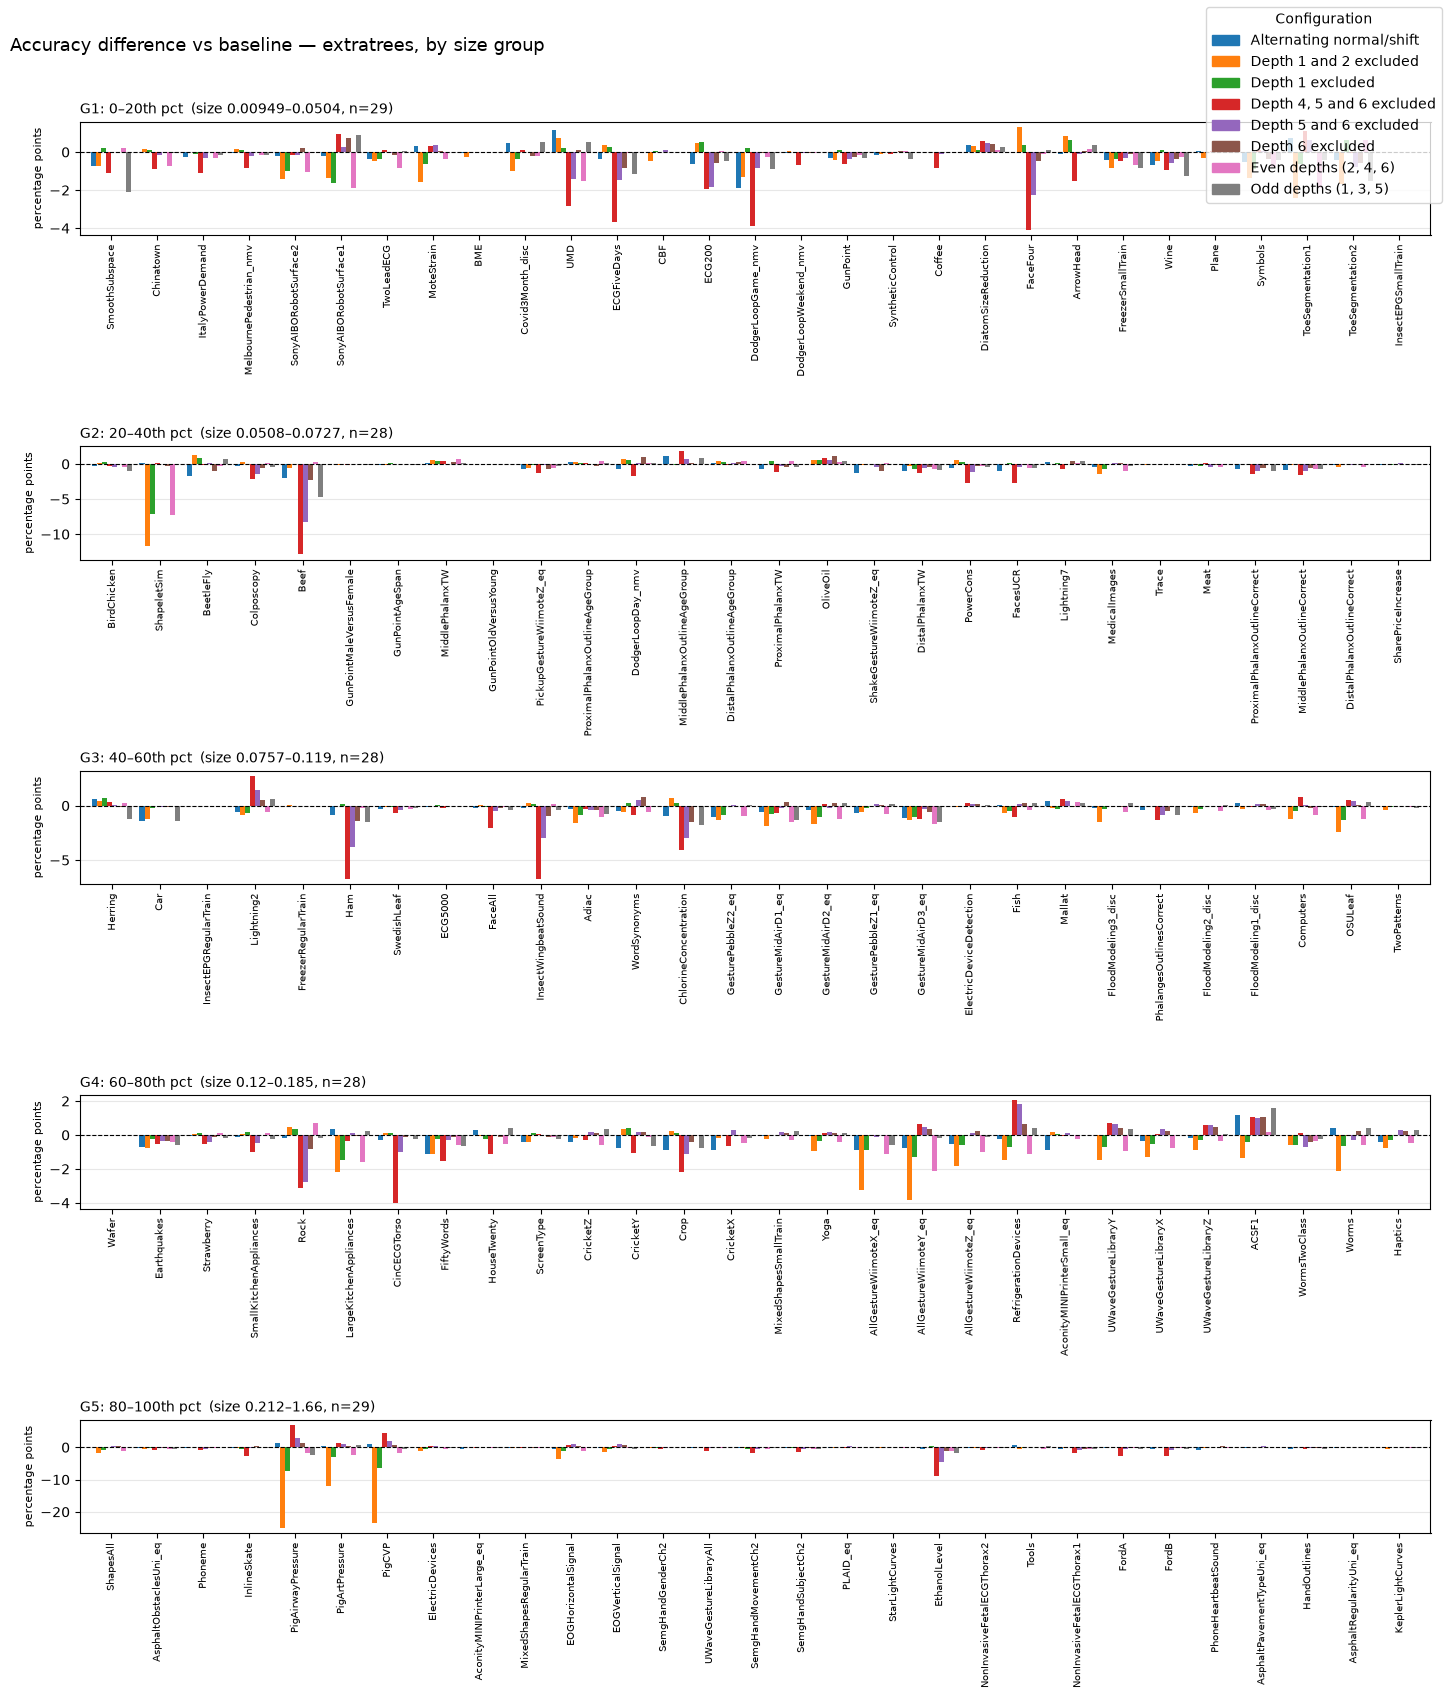

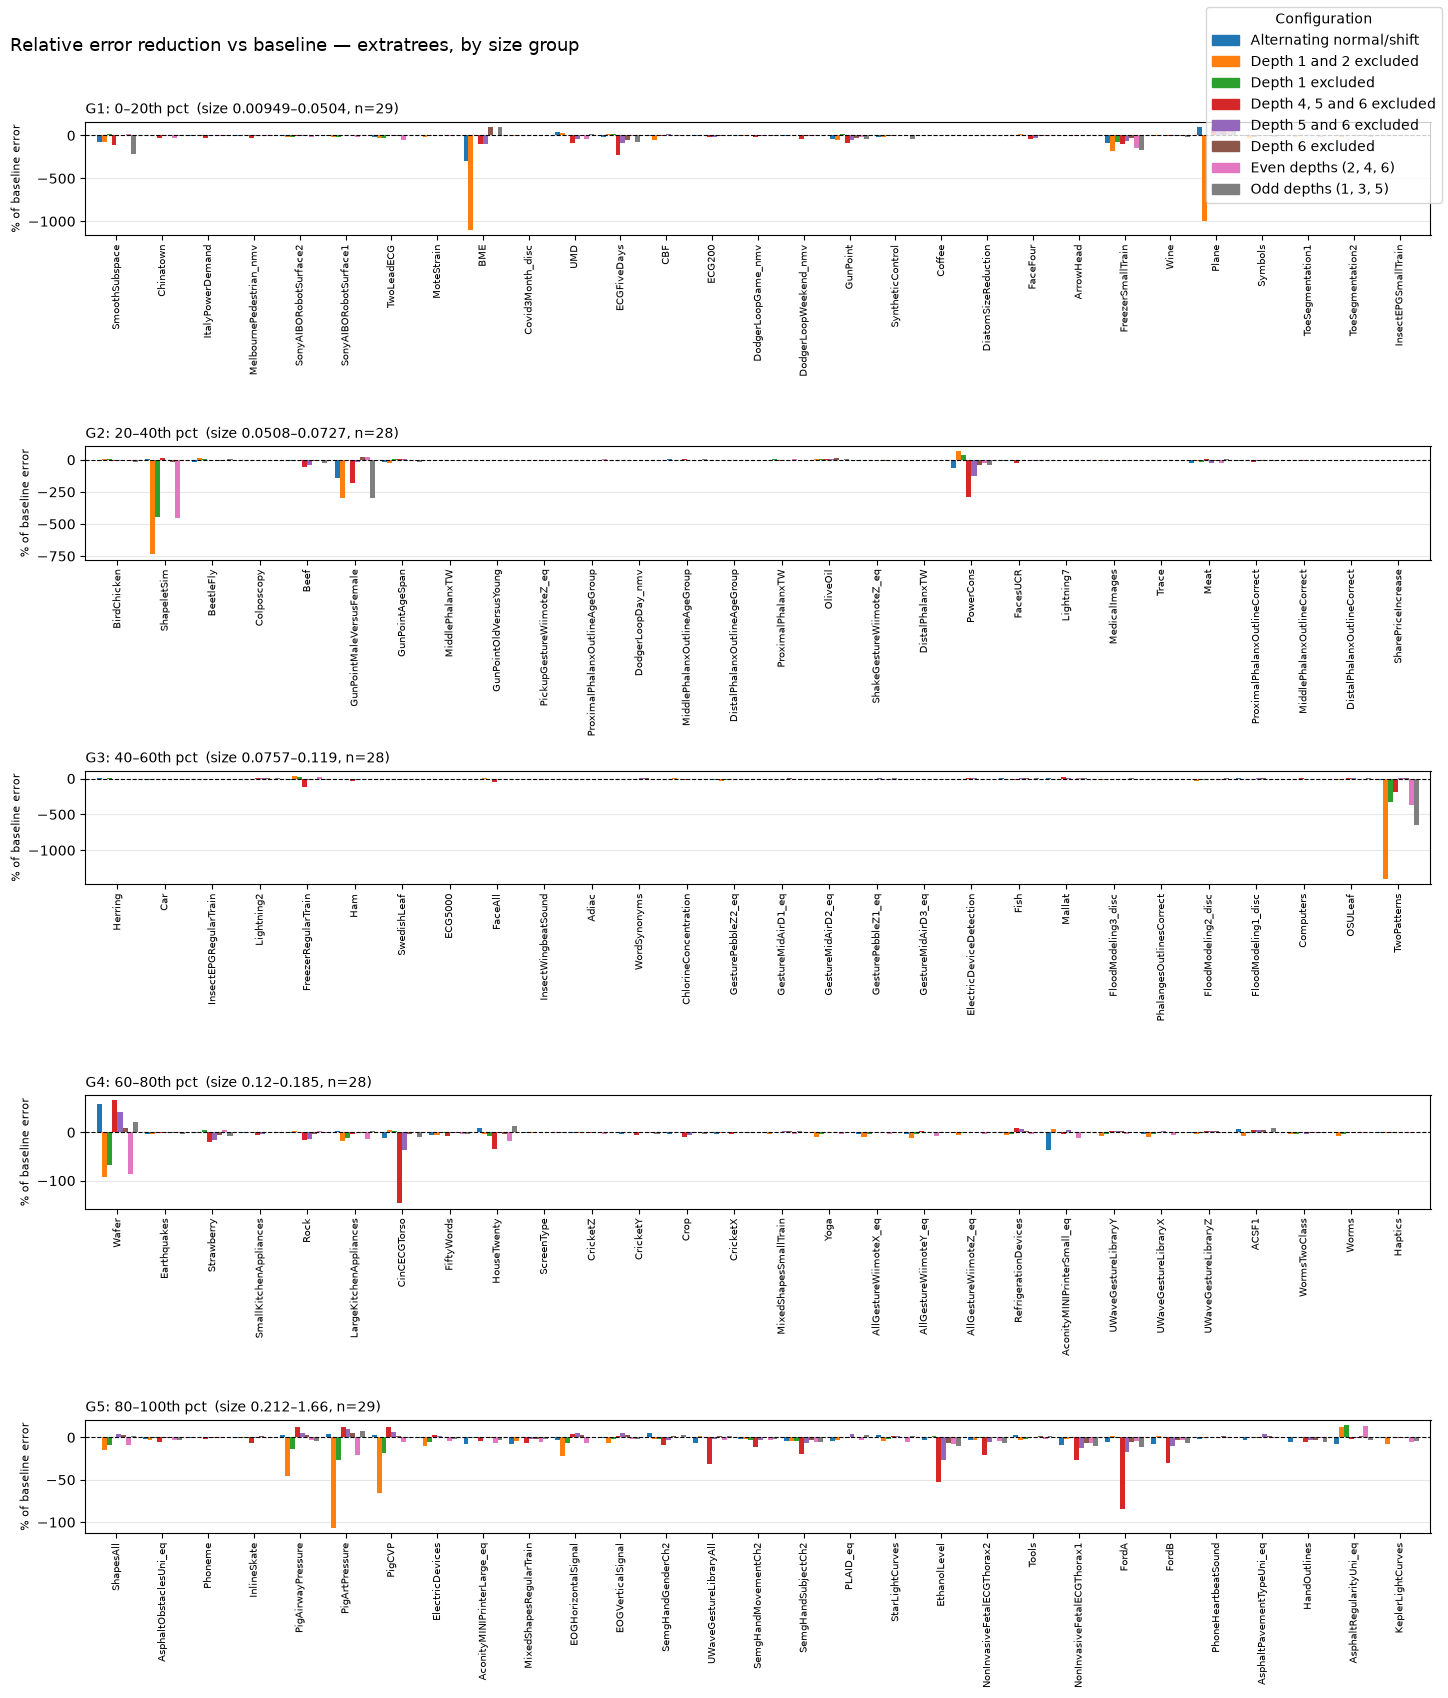

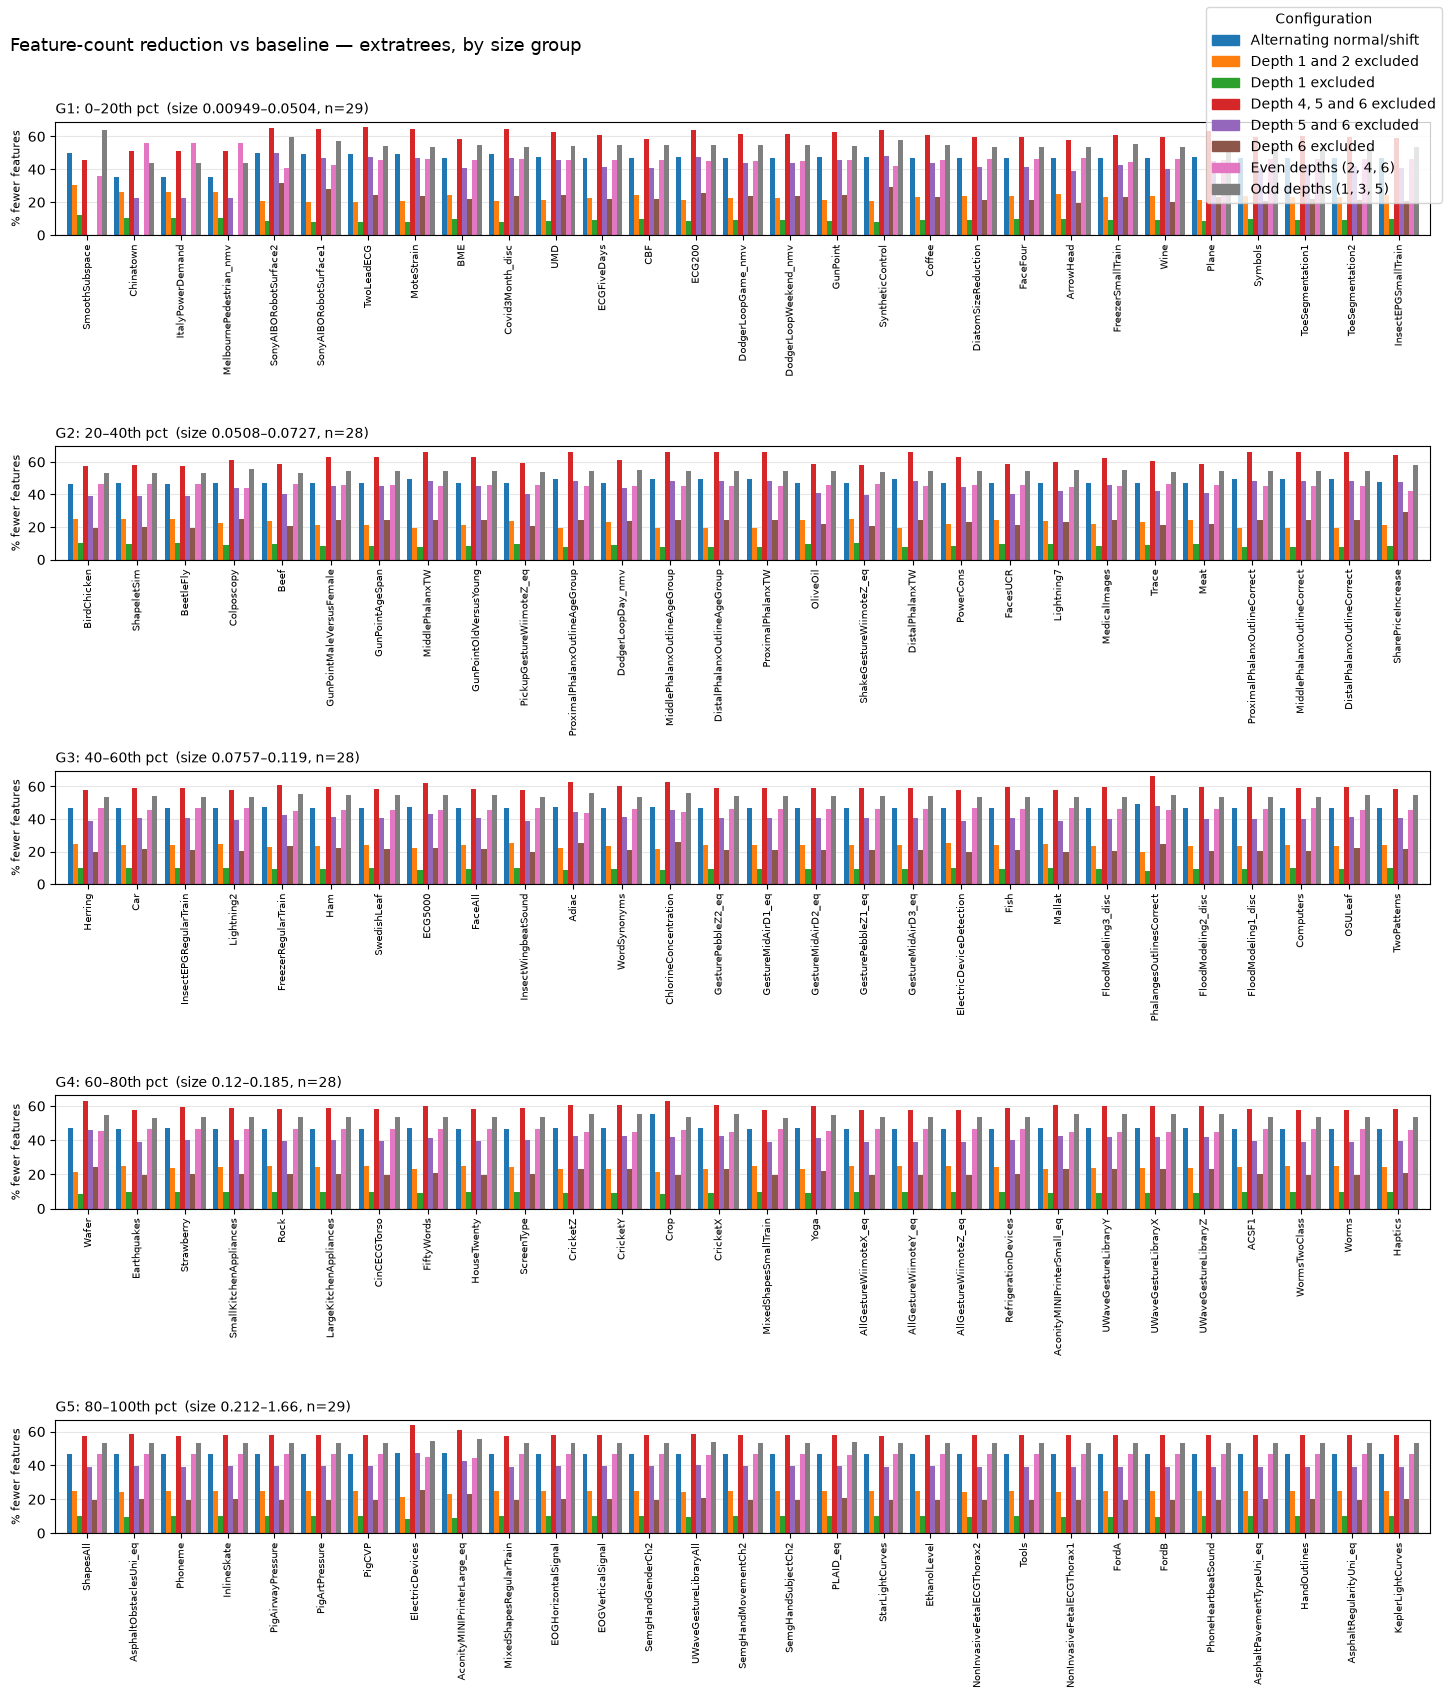

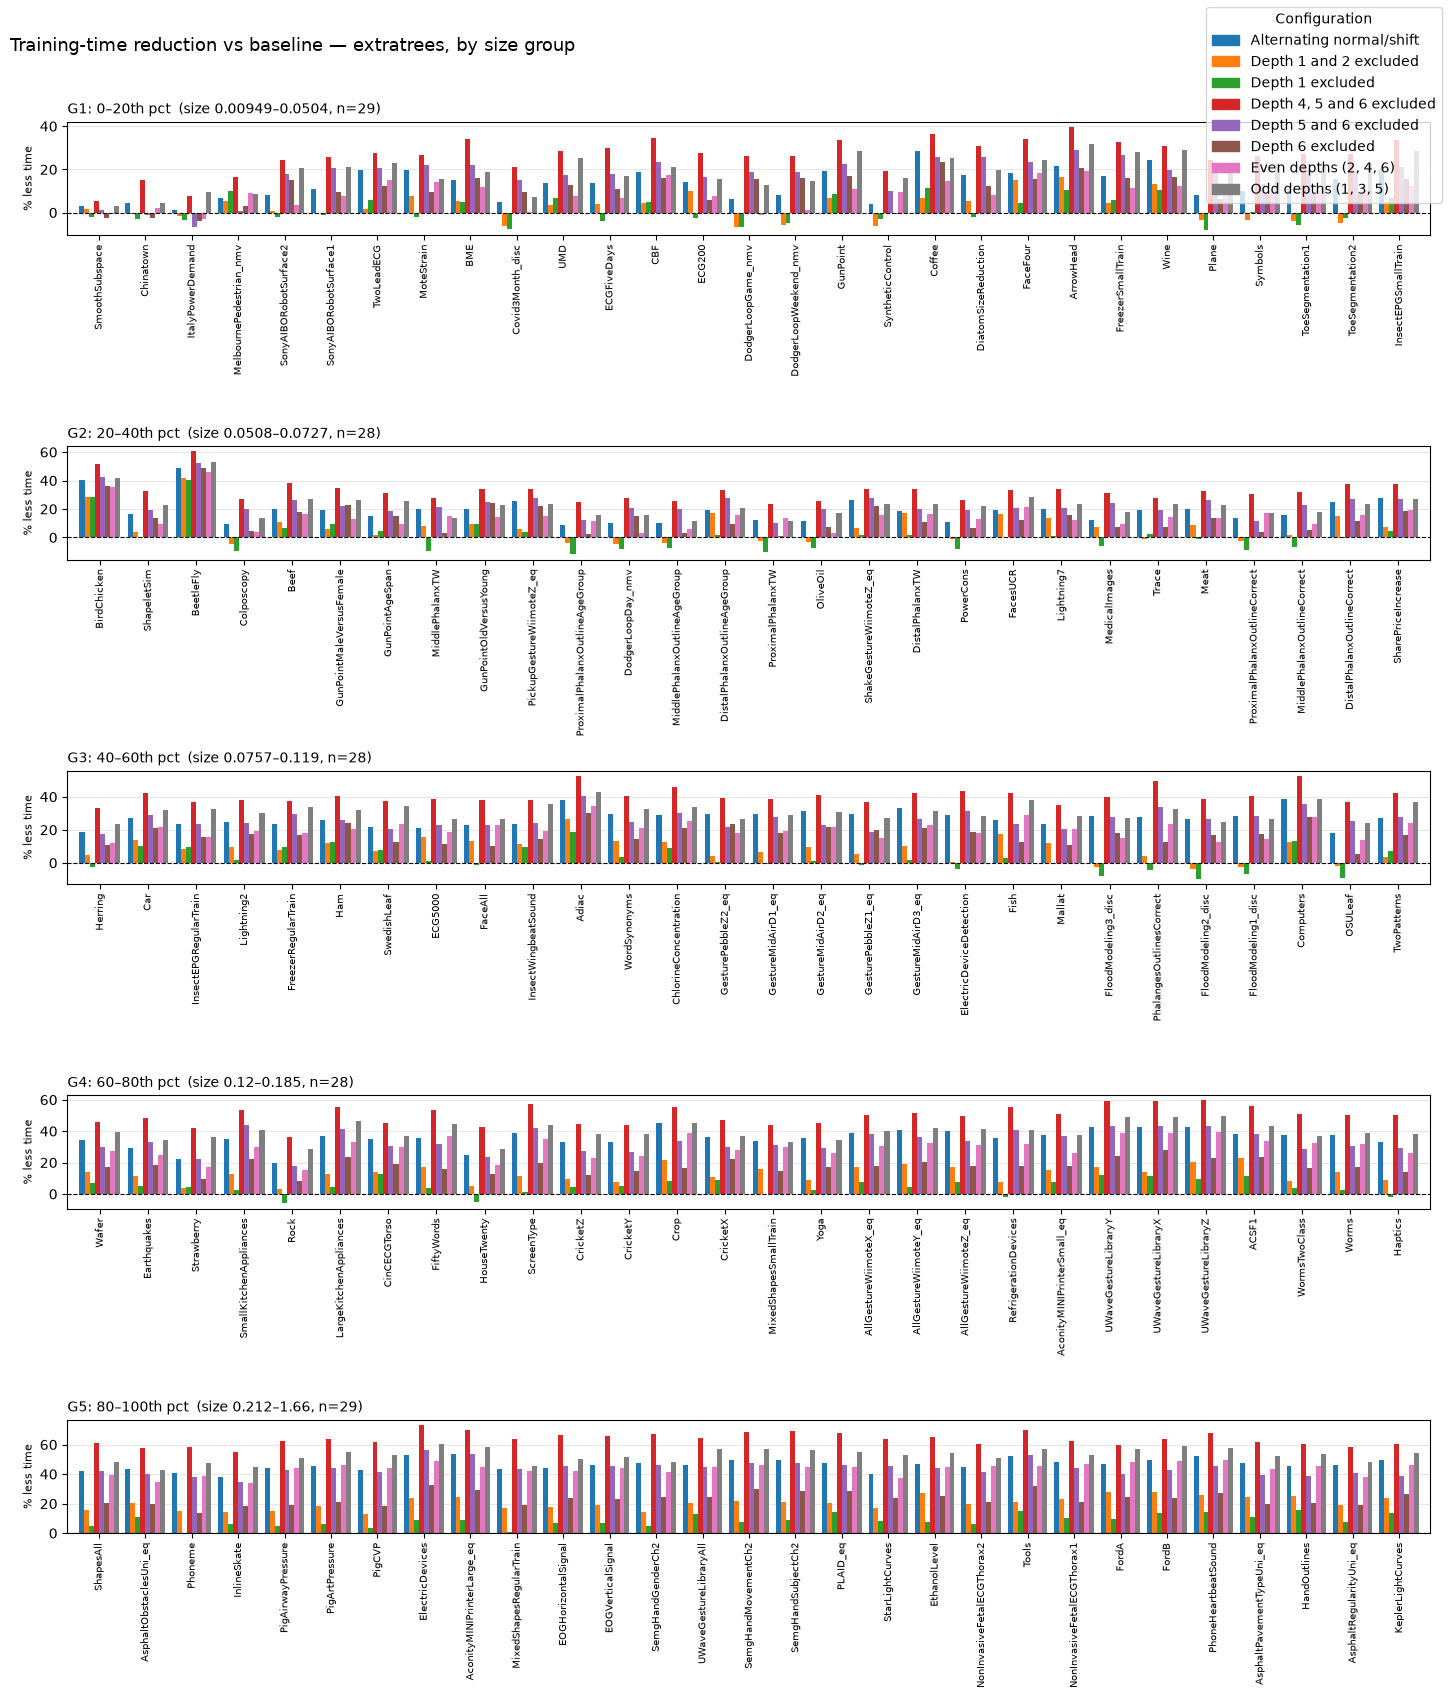

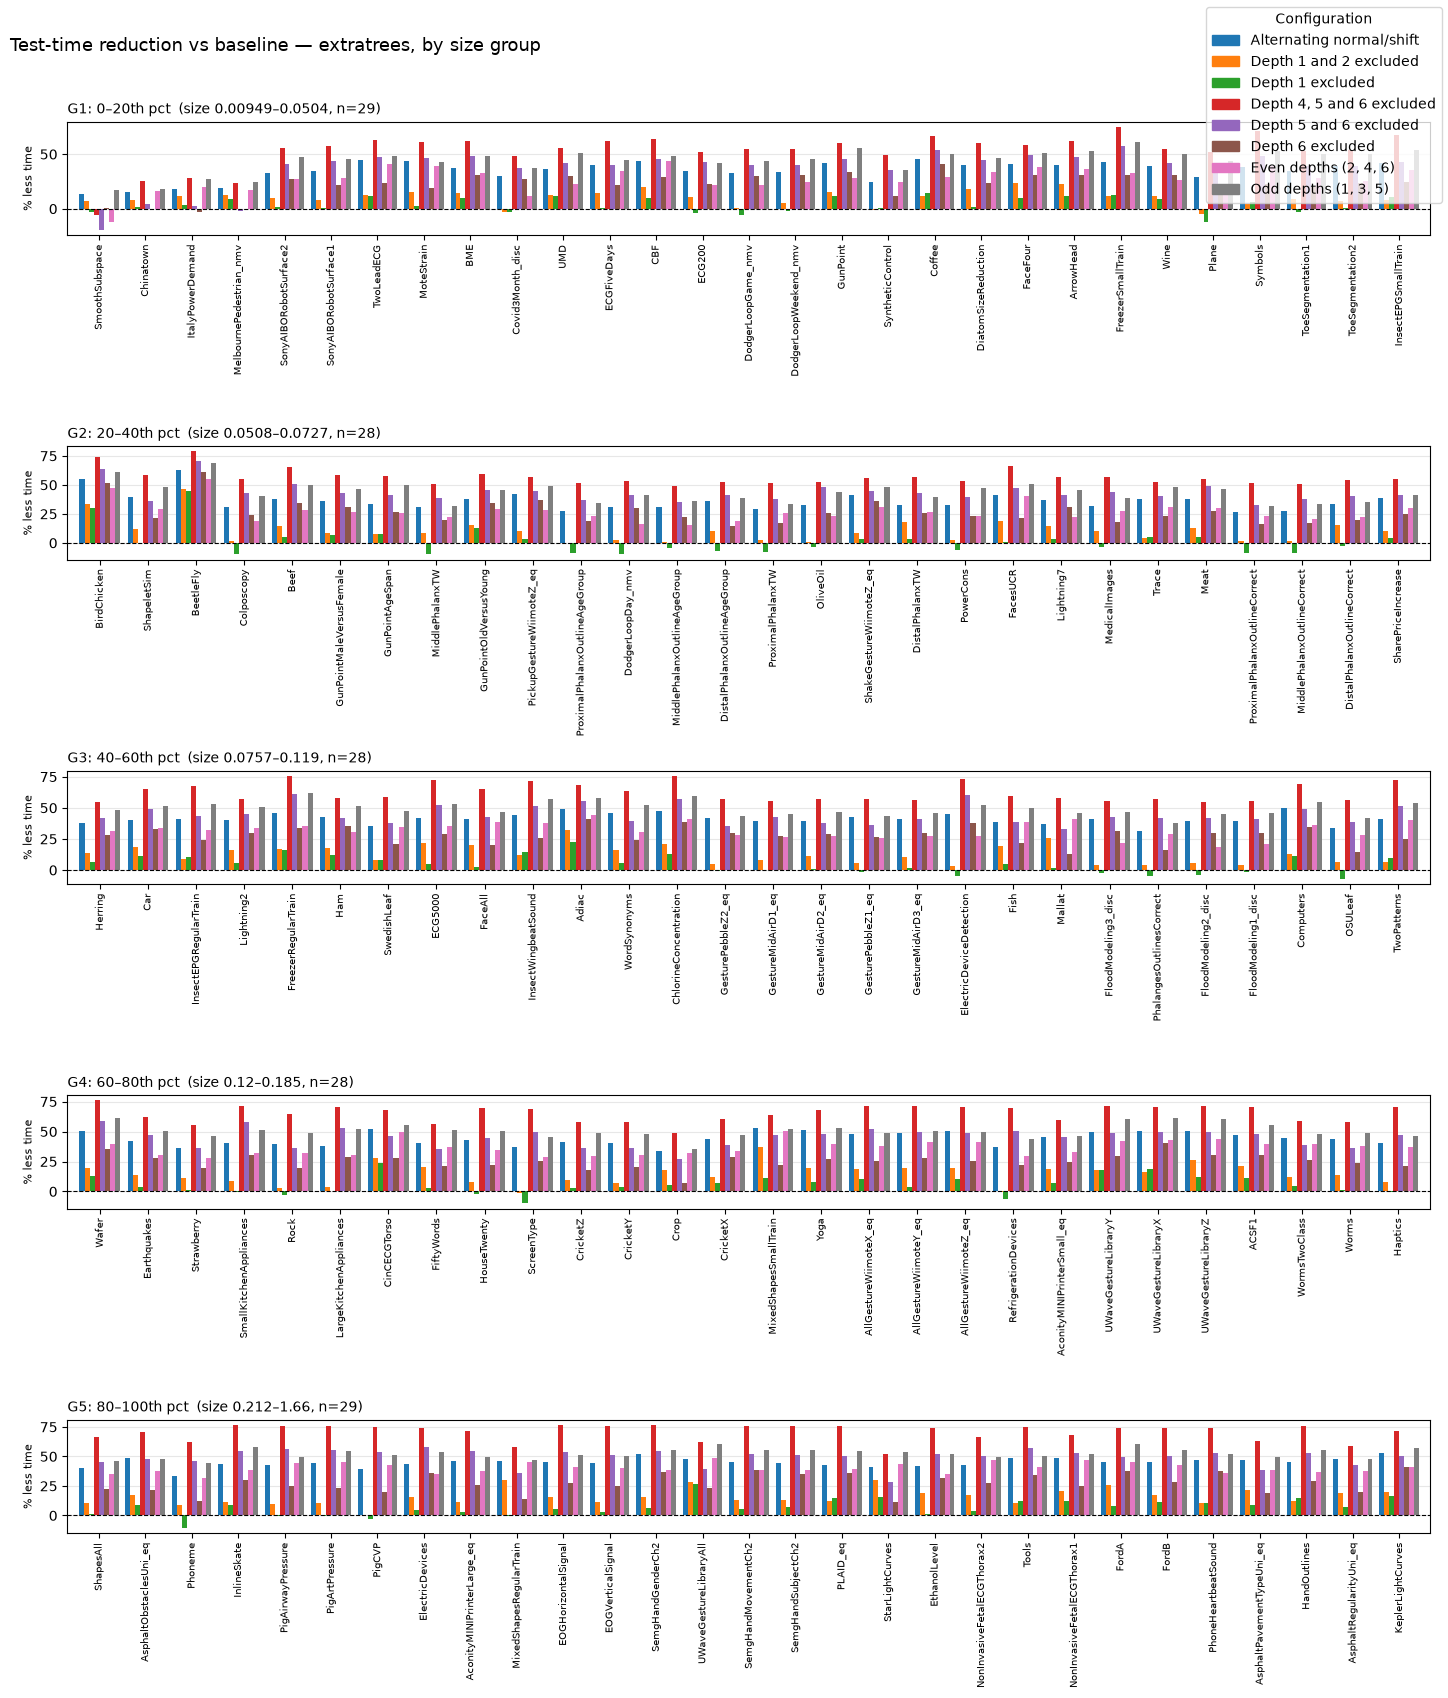

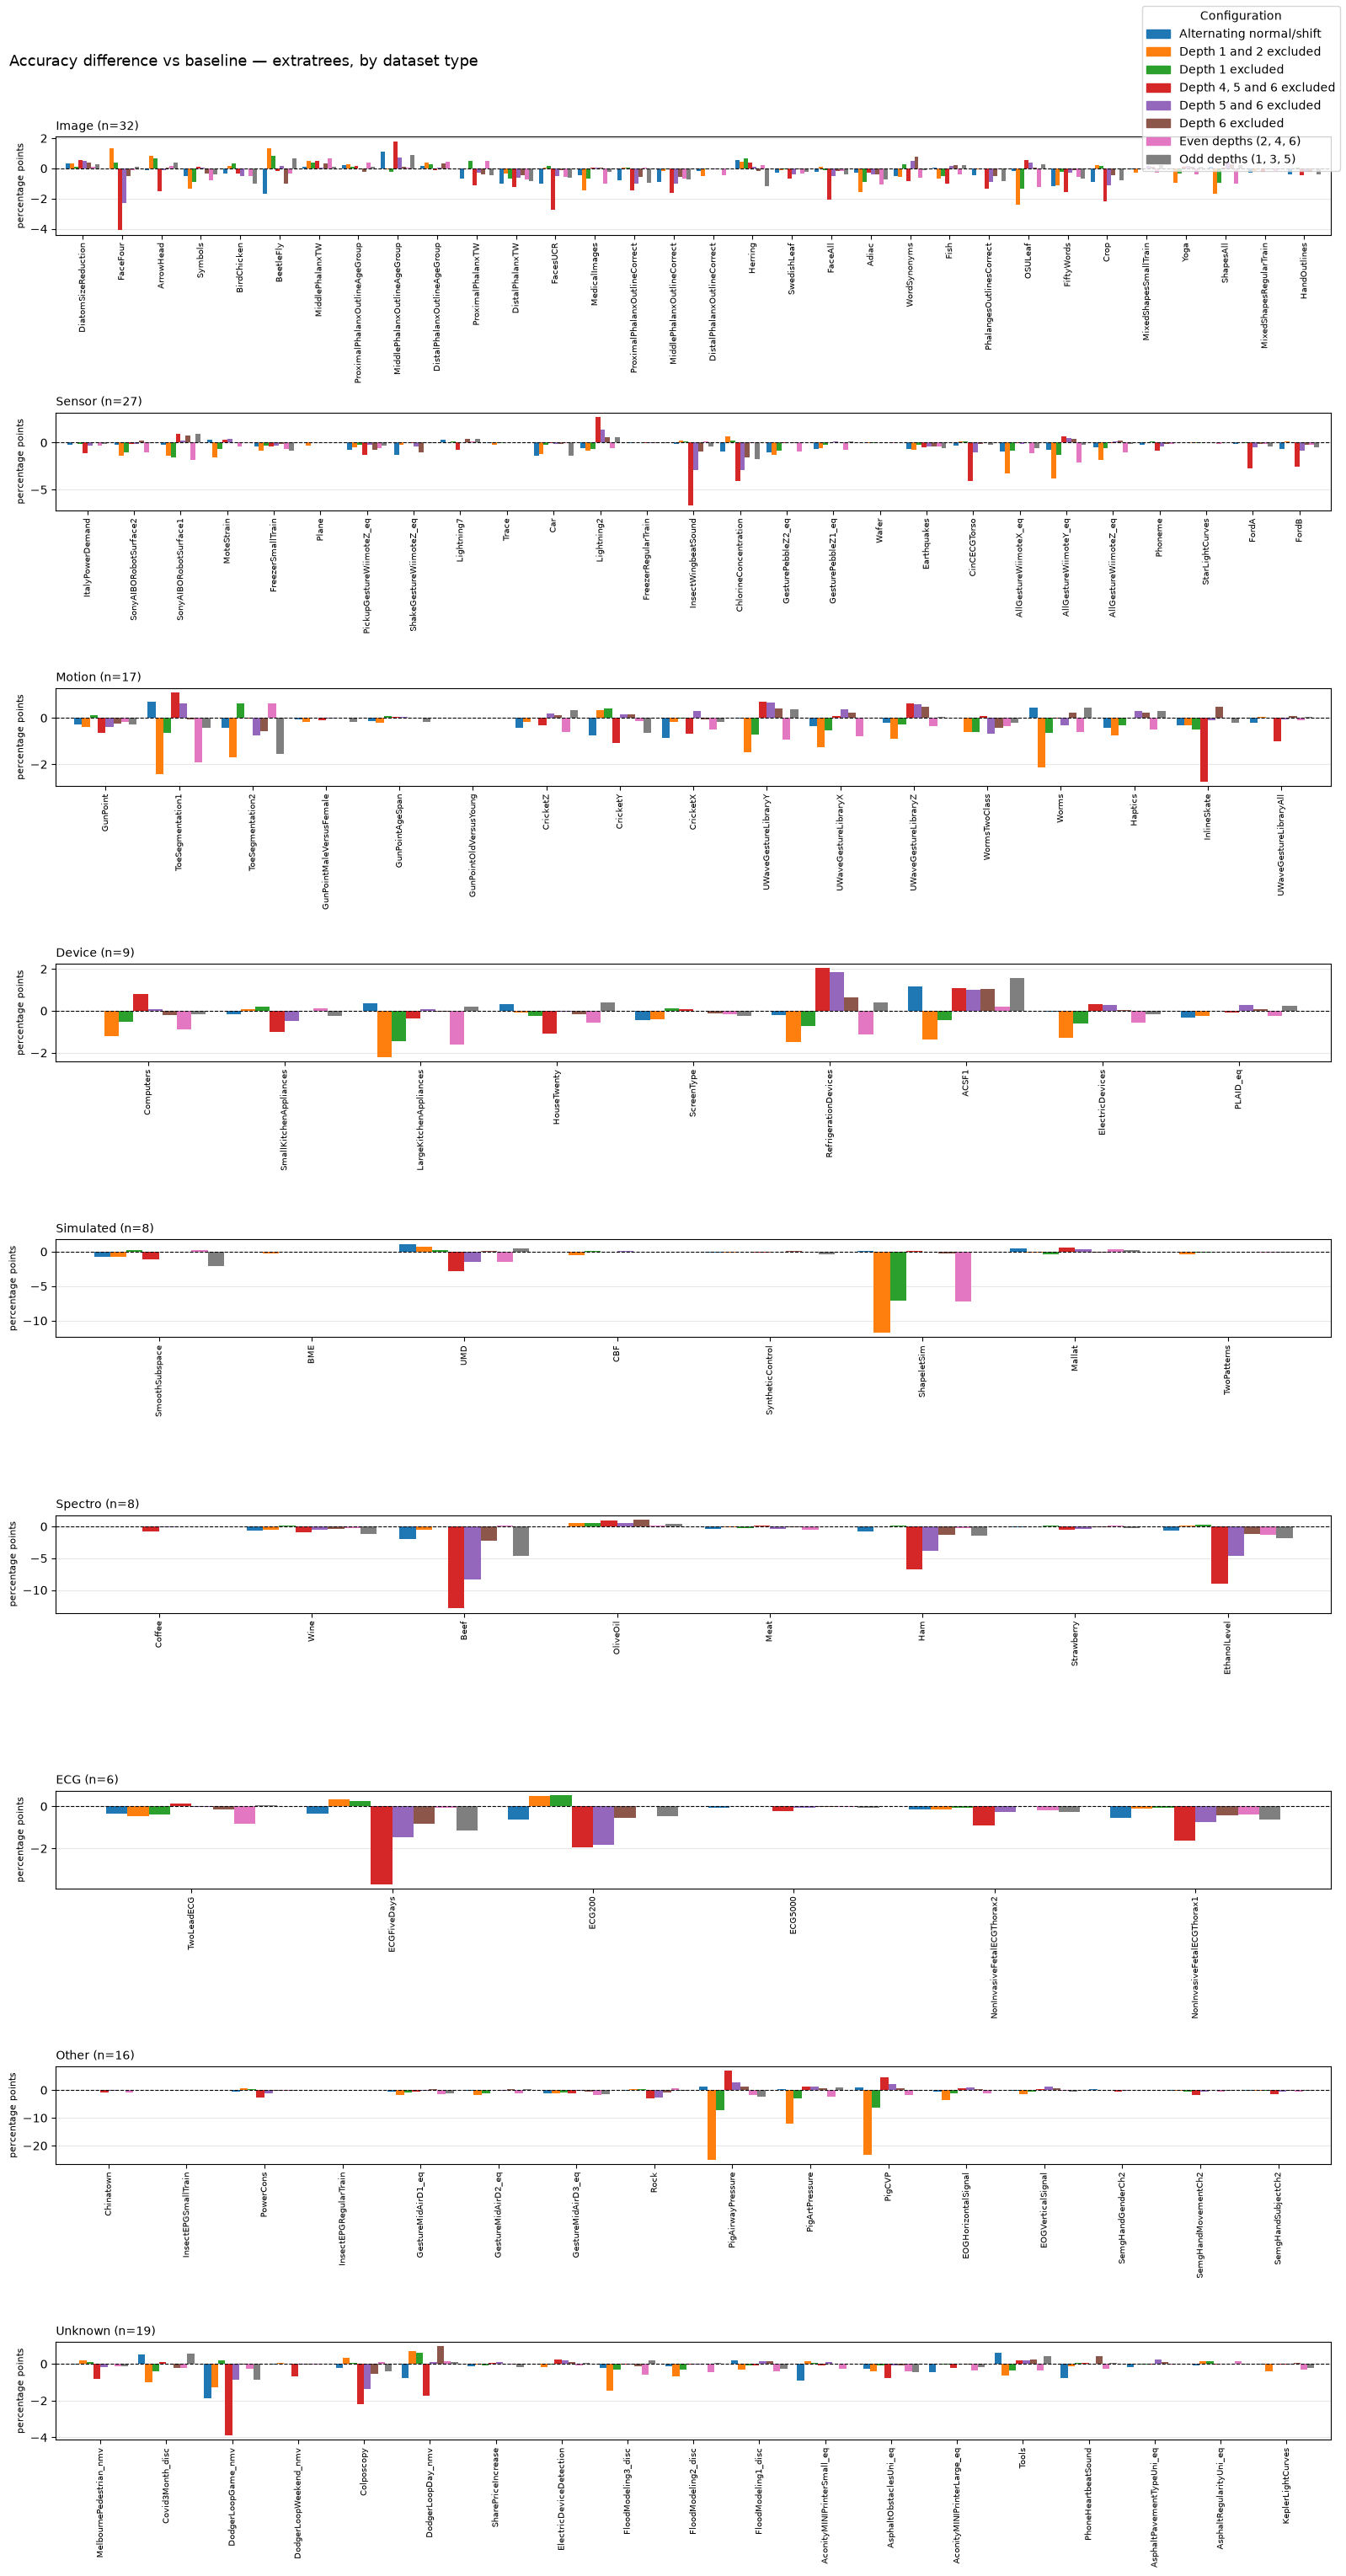

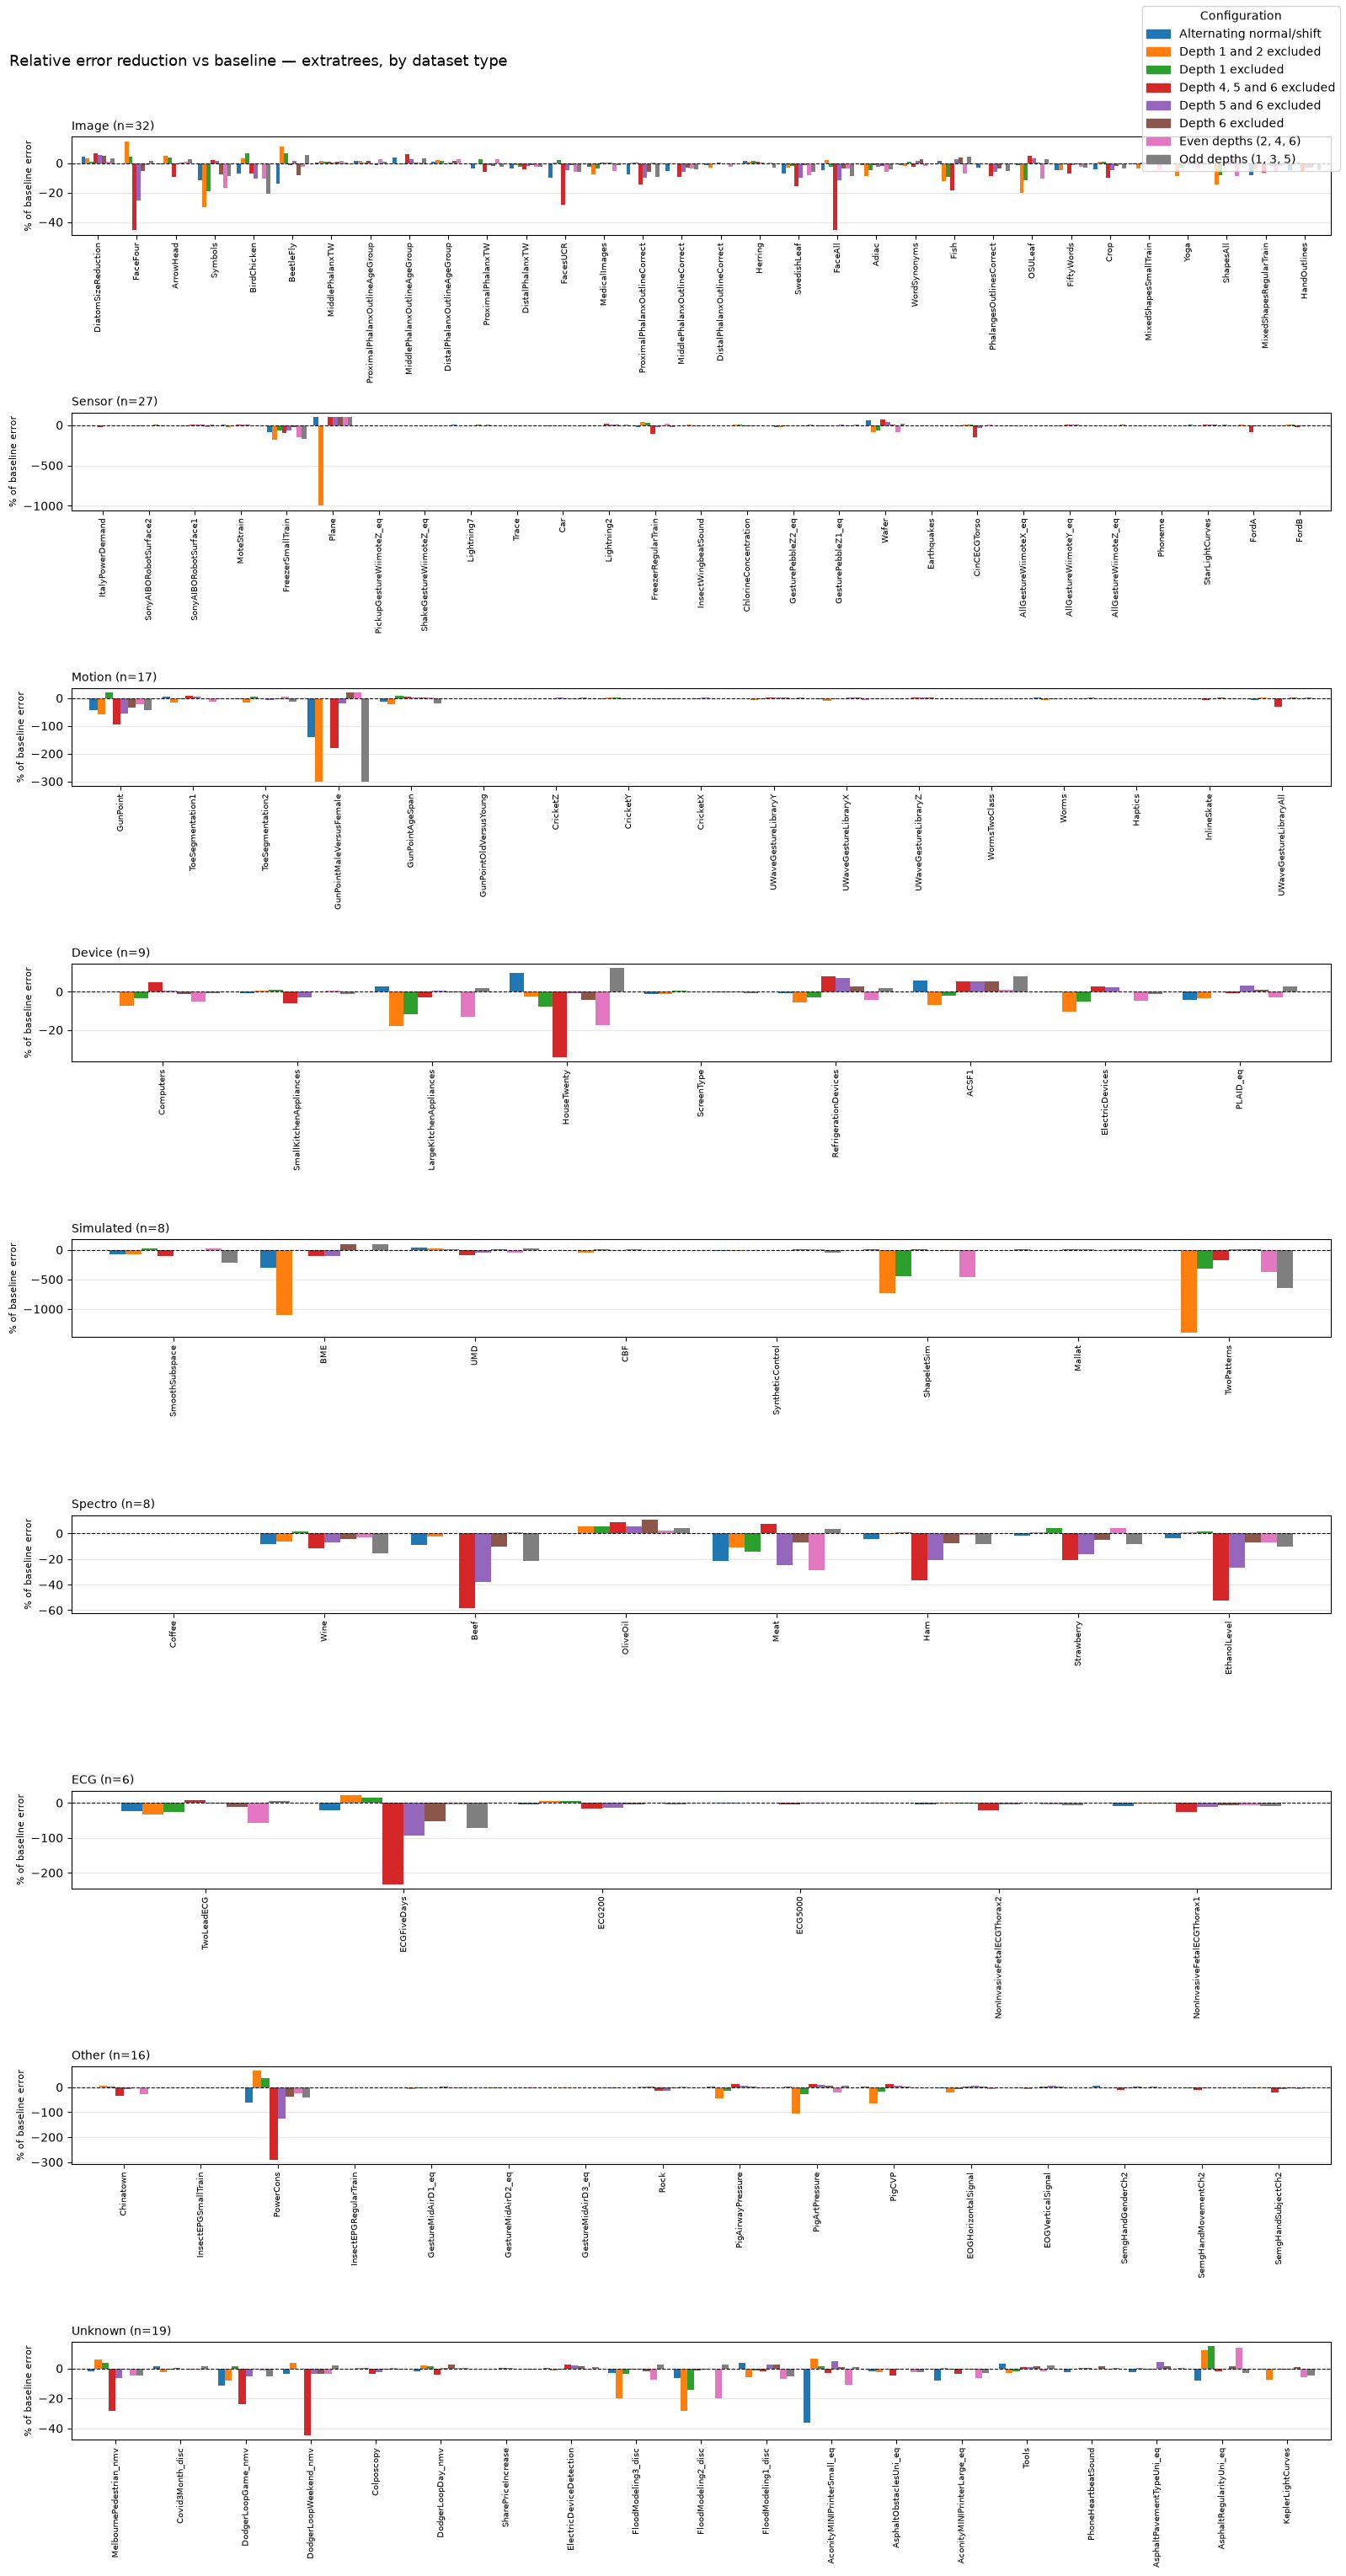

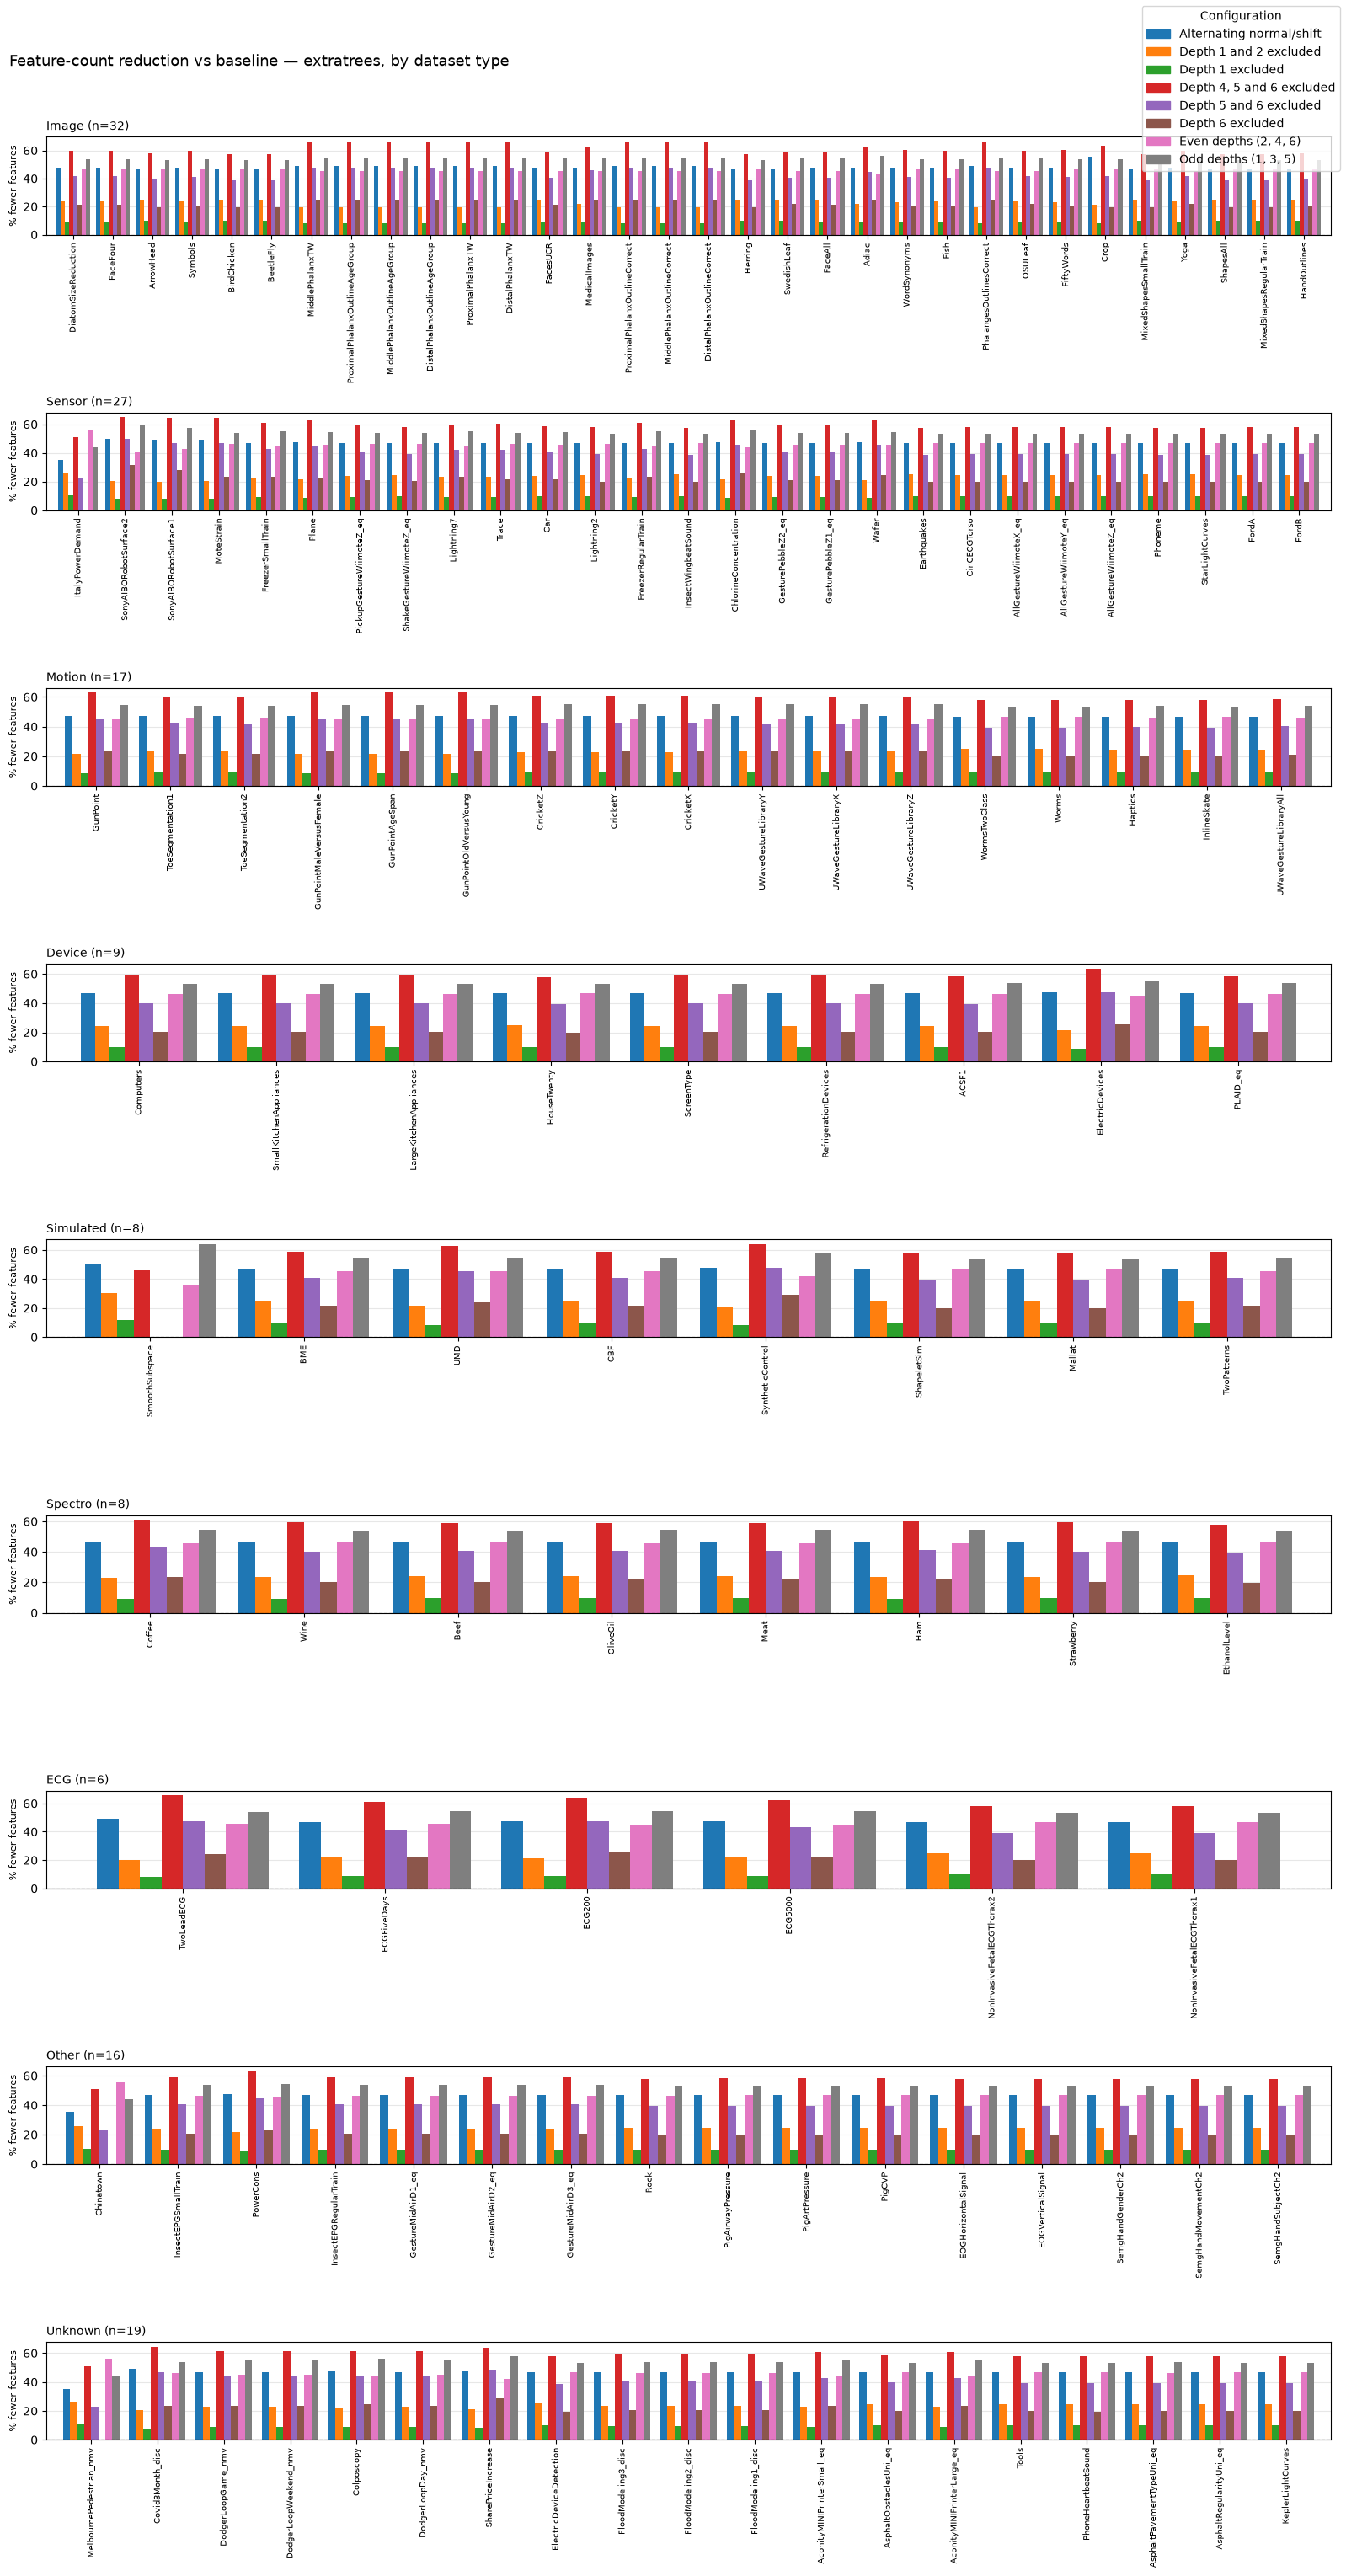

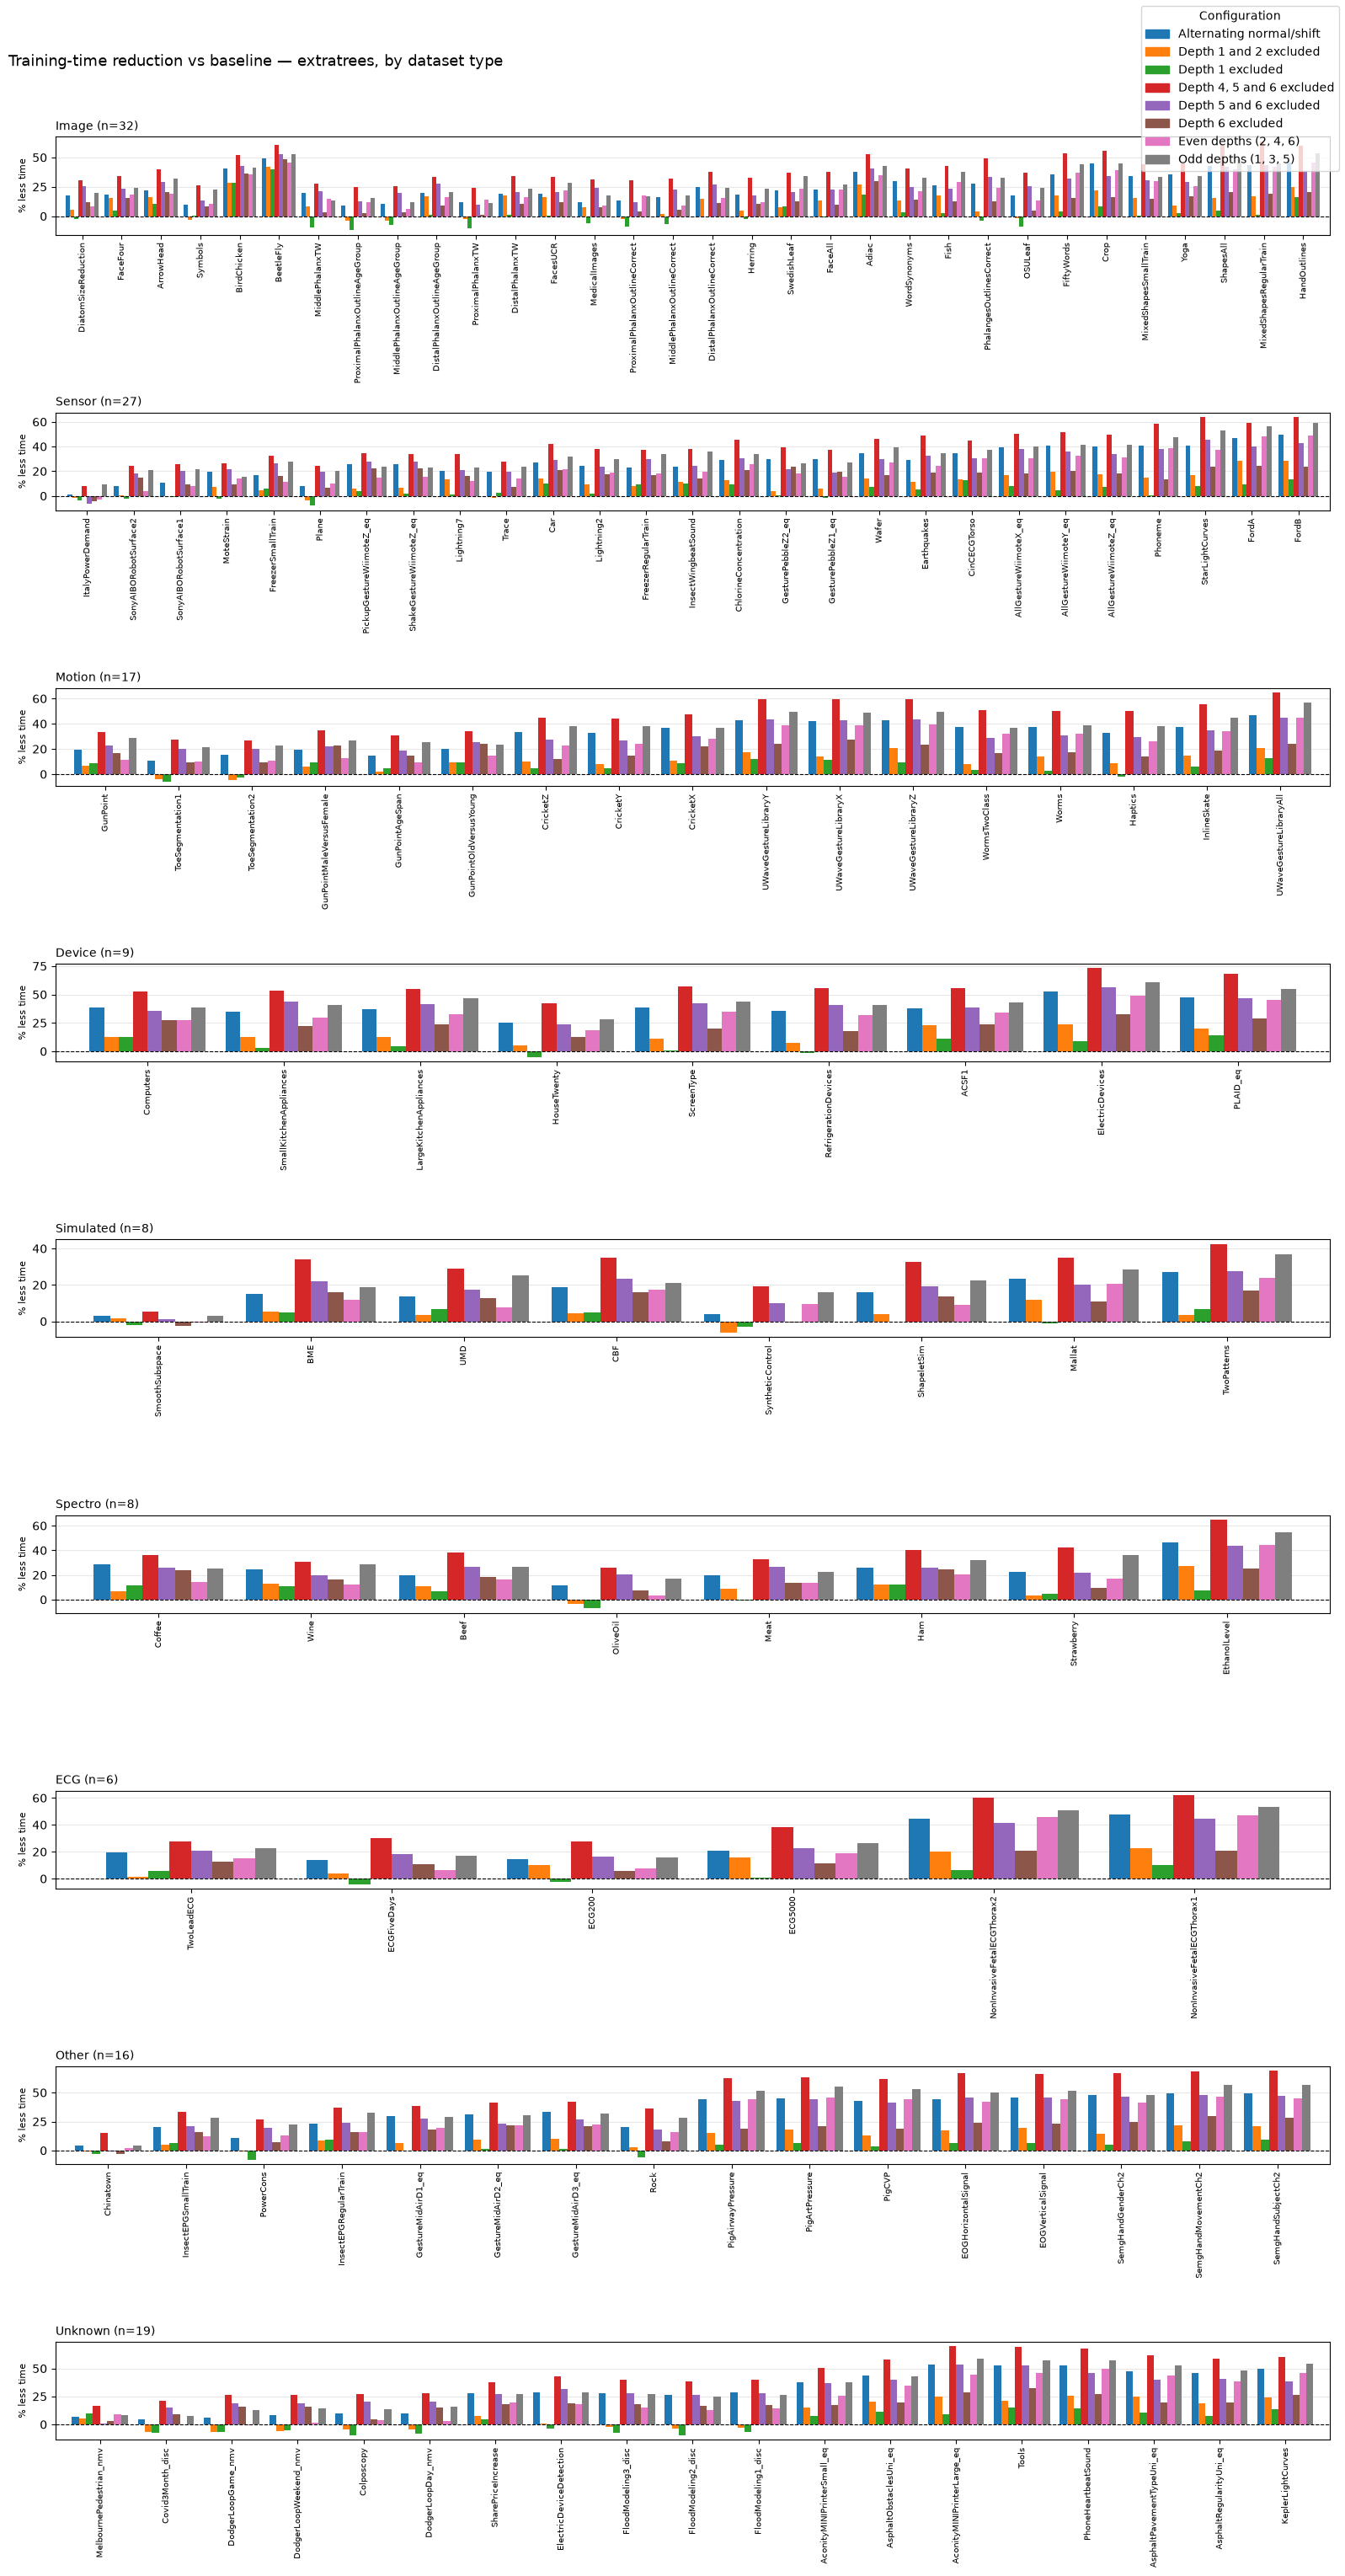

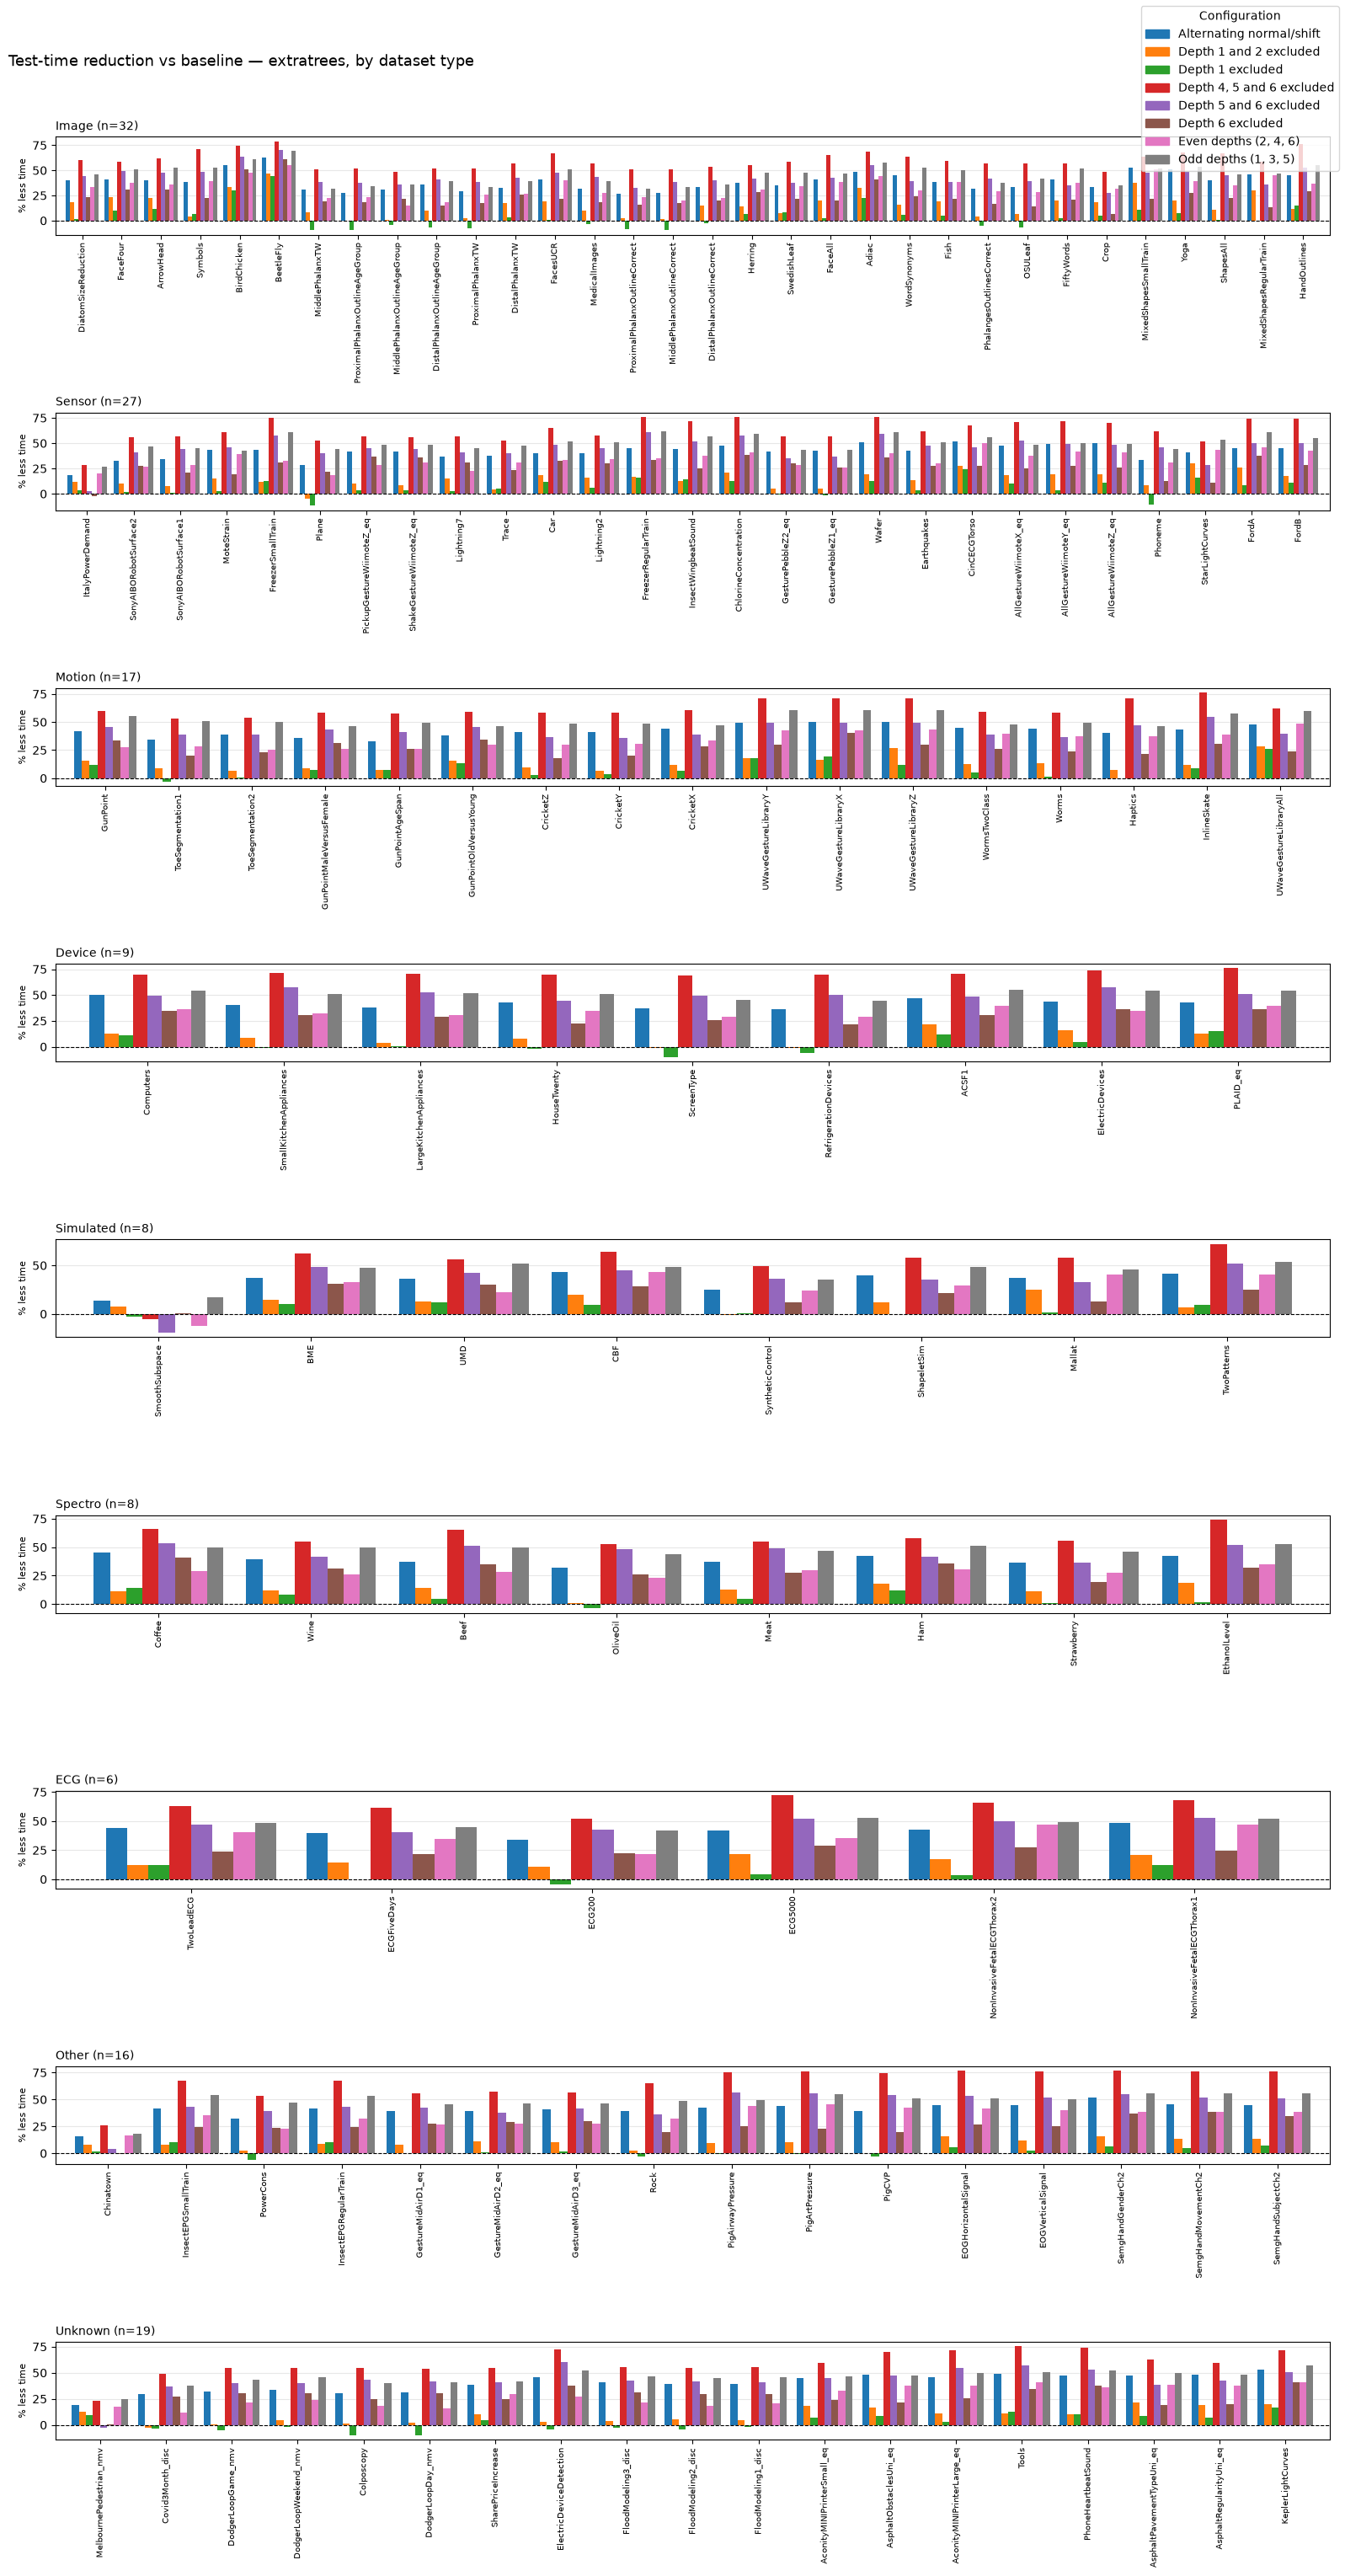

In [12]:
BAR_METRICS = {
    "acc_diff_pp": ("Accuracy difference vs baseline", "percentage points"),
    "error_reduction_pct": ("Relative error reduction vs baseline", "% of baseline error"),
    "feature_reduction_pct": ("Feature-count reduction vs baseline", "% fewer features"),
    "train_time_reduction_pct": ("Training-time reduction vs baseline", "% less time"),
    "test_time_reduction_pct": ("Test-time reduction vs baseline", "% less time"),
}

def plot_grouped_bars(metric, title, ylabel, grouping, col, order):
    for clf in classifiers:
        sub = cmp[cmp["classifier"] == clf]
        present = [name for name in order if (sub[col] == name).any()]
        if not present:
            continue
        widest = max((sub[col] == name).sum() // len(COMPARE_CONFIGS) for name in present)
        fig, axes = plt.subplots(len(present), 1, figsize=(max(14, 0.5 * widest), 3.4 * len(present)), squeeze=False)
        for ax, group_name in zip(axes[:, 0], present):
            g = sub[sub[col] == group_name]
            wide = g.pivot(index="dataset", columns="configuration", values=metric)
            wide = wide.loc[dataset_size.reindex(wide.index).sort_values().index, COMPARE_CONFIGS]
            wide.plot.bar(ax=ax, width=0.85, legend=False, color=[CONFIG_COLORS[c] for c in COMPARE_CONFIGS])
            ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
            ax.set_title(group_name, loc="left", fontsize=10)
            ax.set_xlabel("")
            ax.set_ylabel(ylabel, fontsize=8)
            ax.tick_params(axis="x", labelsize=7, rotation=90)
            ax.grid(axis="y", alpha=0.3)
            ax.set_axisbelow(True)
        fig.legend(handles=[Patch(color=CONFIG_COLORS[c], label=c) for c in COMPARE_CONFIGS],
                   title="Configuration", loc="upper right")
        fig.suptitle(f"{title} — {clf}, by {grouping}", x=0.01, ha="left", fontsize=13)
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        plt.show()

for grouping, (col, order) in GROUPINGS.items():
    for metric, (title, ylabel) in BAR_METRICS.items():
        plot_grouped_bars(metric, title, ylabel, grouping, col, order)

## 8. Statistical significance

### 8a. Critical difference diagrams (across datasets)

Uses the Friedman test followed by Wilcoxon-Holm pairwise tests on the **per-dataset mean accuracies** (Demšar 2006; [hfawaz/cd-diagram](https://github.com/hfawaz/cd-diagram)). Methods joined by a thick bar are **not** significantly different. The first cell draws one diagram per classifier and per experiment group in `EXPERIMENT_GROUPS` (the baseline is always included); the second draws one per dataset-size group and one per dataset type.

Requires `cd_diagram.py`: the repo's `main.py`, renamed and with four small patches (no forced `agg` backend, no `exit()`, an output-file argument, and the example code guarded by `if __name__ == "__main__"`). The Friedman test needs at least 3 methods in a diagram, i.e. the baseline plus at least 2 configurations.

A significant rank difference means the configuration is *consistently* better or worse across datasets, not that the difference is large. Read it together with the accuracy differences in section 6. Groups contain only a few dozen datasets (or fewer), so "no significant difference" in a group mostly means low power, not evidence of equivalence.

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift      6.0
Baseline (QUANT)             14.0
Depth 1 and 2 excluded       21.0
Depth 1 excluded             18.0
Depth 4, 5 and 6 excluded    24.0
Depth 5 and 6 excluded       15.0
Depth 6 excluded             15.0
Even depths (2, 4, 6)        11.0
Odd depths (1, 3, 5)          9.0
dtype: float64
Even depths (2, 4, 6)        5.785211
Depth 1 and 2 excluded       5.757042
Depth 4, 5 and 6 excluded    5.746479
Alternating normal/shift     5.658451
Odd depths (1, 3, 5)         4.996479
Depth 5 and 6 excluded       4.718310
Depth 1 excluded             4.538732
Baseline (QUANT)             3.915493
Depth 6 excluded             3.883803
dtype: float64
('Baseline (QUANT)', 'Even depths (2, 4, 6)', np.float64(5.79356004

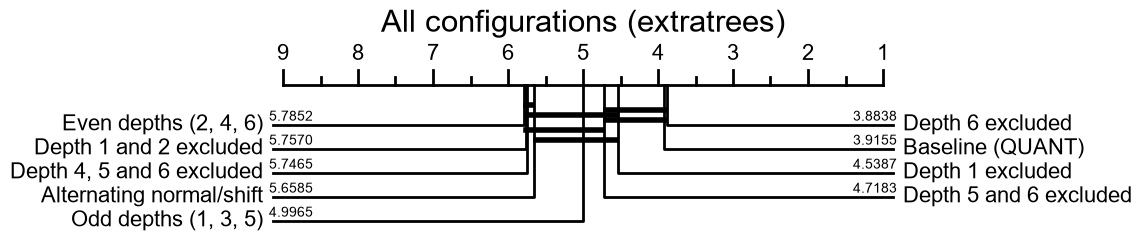

In [13]:
import re
import sys

CD_DIAGRAM_DIR = Path("..")      # folder that contains cd_diagram.py
sys.path.insert(0, str(CD_DIAGRAM_DIR.resolve()))
from cd_diagram import draw_cd_diagram

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
CD_ALPHA = 0.05

EXPERIMENT_GROUPS = {
    "All configurations": COMPARE_CONFIGS
}

for clf in classifiers:
    for group_name, group_configs in EXPERIMENT_GROUPS.items():
        names = [BASELINE] + [c for c in group_configs if c != BASELINE]
        if len(names) < 3:
            print(f"Skipping '{group_name}' ({clf}): the Friedman test needs at least 3 methods, got {len(names)}.")
            continue
        slug = re.sub(r"\W+", "_", group_name)
        df_perf = (
            table[(table["classifier"] == clf) & table["configuration"].isin(names)]
            .rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
            [["classifier_name", "dataset_name", "accuracy"]]
        )
        try:
            draw_cd_diagram(
                df_perf=df_perf, alpha=CD_ALPHA, title=f"{group_name} ({clf})", labels=True,
                filename=FIG_DIR / f"cd_{clf}_{slug}.png",
            )
        except RuntimeError as err:          # Friedman test not significant
            print(f"No diagram for '{group_name}' ({clf}): {err}")

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     1.0
Baseline (QUANT)             1.0
Depth 1 and 2 excluded       7.0
Depth 1 excluded             4.0
Depth 4, 5 and 6 excluded    5.0
Depth 5 and 6 excluded       2.0
Depth 6 excluded             2.0
Even depths (2, 4, 6)        2.0
Odd depths (1, 3, 5)         1.0
dtype: float64
Depth 4, 5 and 6 excluded    6.068966
Even depths (2, 4, 6)        5.637931
Depth 1 and 2 excluded       5.620690
Alternating normal/shift     5.310345
Depth 5 and 6 excluded       5.241379
Odd depths (1, 3, 5)         4.913793
Depth 1 excluded             4.206897
Depth 6 excluded             4.017241
Baseline (QUANT)             3.982759
dtype: float64
('Depth 1 excluded', 'Even depths (2, 4, 6)', np.float64(0.00219724242142156

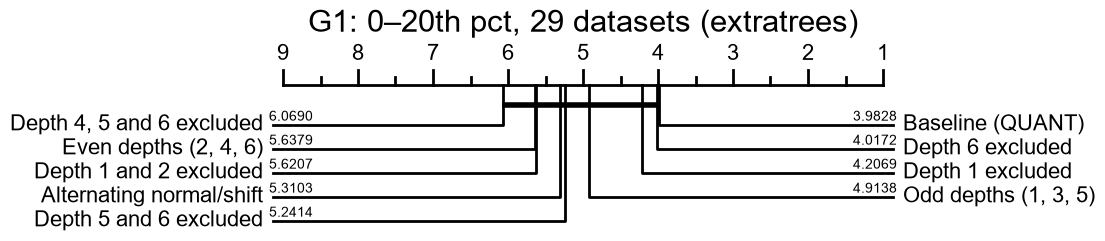

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     0.0
Baseline (QUANT)             3.0
Depth 1 and 2 excluded       4.0
Depth 1 excluded             3.0
Depth 4, 5 and 6 excluded    4.0
Depth 5 and 6 excluded       2.0
Depth 6 excluded             2.0
Even depths (2, 4, 6)        7.0
Odd depths (1, 3, 5)         0.0
dtype: float64
Alternating normal/shift     6.321429
Depth 4, 5 and 6 excluded    5.696429
Odd depths (1, 3, 5)         5.607143
Depth 5 and 6 excluded       5.446429
Depth 1 and 2 excluded       4.535714
Baseline (QUANT)             4.500000
Depth 6 excluded             4.464286
Even depths (2, 4, 6)        4.464286
Depth 1 excluded             3.964286
dtype: float64
('Alternating normal/shift', 'Baseline (QUANT)', np.float64(0.00396702758974

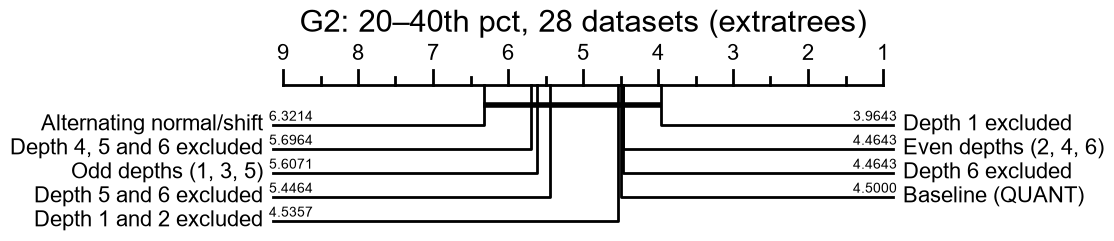

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     1.0
Baseline (QUANT)             5.0
Depth 1 and 2 excluded       4.0
Depth 1 excluded             3.0
Depth 4, 5 and 6 excluded    5.0
Depth 5 and 6 excluded       2.0
Depth 6 excluded             3.0
Even depths (2, 4, 6)        0.0
Odd depths (1, 3, 5)         4.0
dtype: float64
Depth 1 and 2 excluded       6.250000
Even depths (2, 4, 6)        6.178571
Depth 4, 5 and 6 excluded    5.446429
Alternating normal/shift     5.178571
Odd depths (1, 3, 5)         5.142857
Depth 1 excluded             4.964286
Depth 5 and 6 excluded       4.428571
Depth 6 excluded             4.053571
Baseline (QUANT)             3.357143
dtype: float64
('Baseline (QUANT)', 'Even depths (2, 4, 6)', np.float64(0.00016395879031805

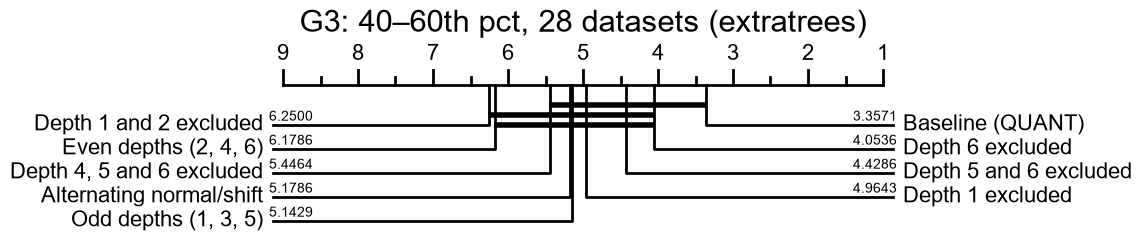

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     1.0
Baseline (QUANT)             2.0
Depth 1 and 2 excluded       3.0
Depth 1 excluded             3.0
Depth 4, 5 and 6 excluded    6.0
Depth 5 and 6 excluded       4.0
Depth 6 excluded             2.0
Even depths (2, 4, 6)        2.0
Odd depths (1, 3, 5)         4.0
dtype: float64
Depth 1 and 2 excluded       6.660714
Even depths (2, 4, 6)        6.392857
Alternating normal/shift     5.839286
Depth 4, 5 and 6 excluded    5.142857
Depth 1 excluded             4.875000
Odd depths (1, 3, 5)         4.321429
Baseline (QUANT)             4.107143
Depth 5 and 6 excluded       3.875000
Depth 6 excluded             3.785714
dtype: float64
('Baseline (QUANT)', 'Even depths (2, 4, 6)', np.float64(7.204711437225342e-

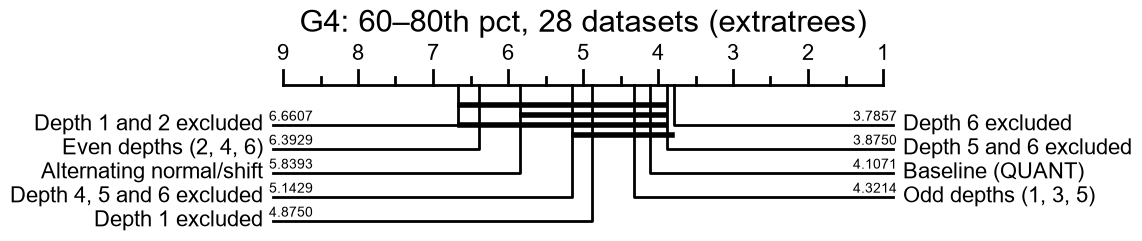

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     3.0
Baseline (QUANT)             3.0
Depth 1 and 2 excluded       3.0
Depth 1 excluded             5.0
Depth 4, 5 and 6 excluded    4.0
Depth 5 and 6 excluded       5.0
Depth 6 excluded             6.0
Even depths (2, 4, 6)        0.0
Odd depths (1, 3, 5)         0.0
dtype: float64
Depth 4, 5 and 6 excluded    6.344828
Even depths (2, 4, 6)        6.241379
Depth 1 and 2 excluded       5.724138
Alternating normal/shift     5.655172
Odd depths (1, 3, 5)         5.000000
Depth 1 excluded             4.689655
Depth 5 and 6 excluded       4.586207
Baseline (QUANT)             3.637931
Depth 6 excluded             3.120690
dtype: float64
('Baseline (QUANT)', 'Even depths (2, 4, 6)', np.float64(2.60770320892334e-0

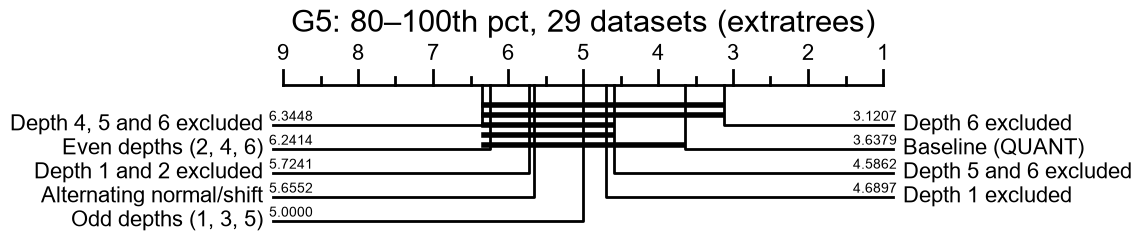

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     0.0
Baseline (QUANT)             6.0
Depth 1 and 2 excluded       6.0
Depth 1 excluded             5.0
Depth 4, 5 and 6 excluded    5.0
Depth 5 and 6 excluded       3.0
Depth 6 excluded             1.0
Even depths (2, 4, 6)        4.0
Odd depths (1, 3, 5)         2.0
dtype: float64
Depth 4, 5 and 6 excluded    6.203125
Alternating normal/shift     5.890625
Even depths (2, 4, 6)        5.531250
Odd depths (1, 3, 5)         5.265625
Depth 5 and 6 excluded       5.046875
Depth 1 and 2 excluded       4.687500
Depth 6 excluded             4.234375
Baseline (QUANT)             4.109375
Depth 1 excluded             4.031250
dtype: float64
('Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', np.float64(0.0017936

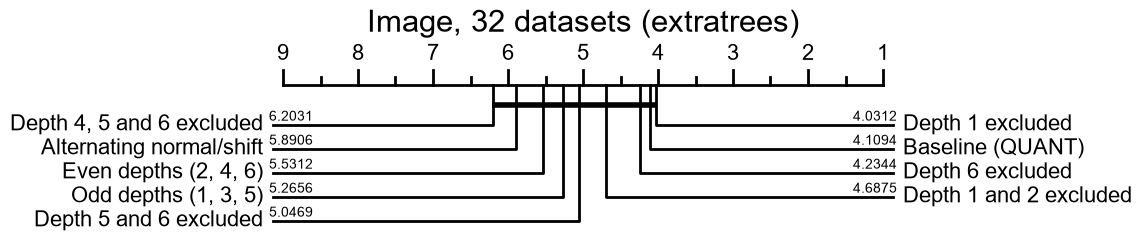

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     1.0
Baseline (QUANT)             4.0
Depth 1 and 2 excluded       7.0
Depth 1 excluded             1.0
Depth 4, 5 and 6 excluded    4.0
Depth 5 and 6 excluded       2.0
Depth 6 excluded             3.0
Even depths (2, 4, 6)        1.0
Odd depths (1, 3, 5)         1.0
dtype: float64
Depth 1 and 2 excluded       6.111111
Alternating normal/shift     5.962963
Even depths (2, 4, 6)        5.685185
Depth 4, 5 and 6 excluded    5.444444
Depth 1 excluded             4.888889
Depth 5 and 6 excluded       4.685185
Odd depths (1, 3, 5)         4.592593
Depth 6 excluded             4.018519
Baseline (QUANT)             3.611111
dtype: float64
('Alternating normal/shift', 'Baseline (QUANT)', np.float64(6.33150339126586

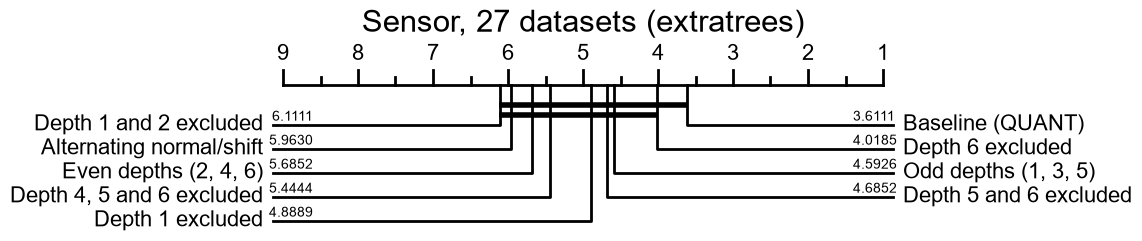

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     0.0
Baseline (QUANT)             0.0
Depth 1 and 2 excluded       0.0
Depth 1 excluded             3.0
Depth 4, 5 and 6 excluded    4.0
Depth 5 and 6 excluded       3.0
Depth 6 excluded             2.0
Even depths (2, 4, 6)        2.0
Odd depths (1, 3, 5)         1.0
dtype: float64
Depth 1 and 2 excluded       7.264706
Alternating normal/shift     5.764706
Even depths (2, 4, 6)        5.764706
Depth 4, 5 and 6 excluded    5.000000
Odd depths (1, 3, 5)         4.852941
Depth 1 excluded             4.823529
Baseline (QUANT)             4.058824
Depth 5 and 6 excluded       3.941176
Depth 6 excluded             3.529412
dtype: float64
('Depth 1 and 2 excluded', 'Depth 6 excluded', np.float64(0.0010859976966440

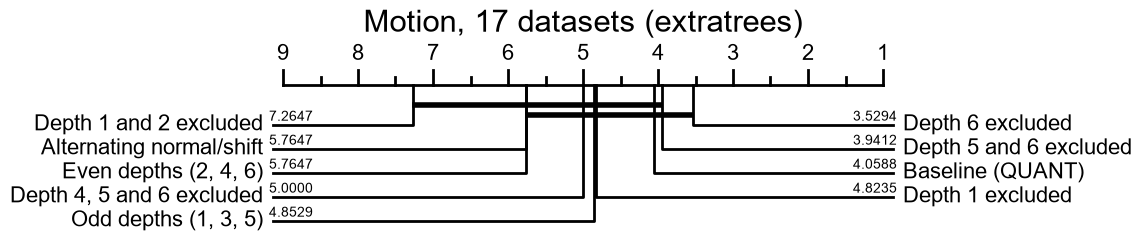

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     1.0
Baseline (QUANT)             0.0
Depth 1 and 2 excluded       0.0
Depth 1 excluded             2.0
Depth 4, 5 and 6 excluded    3.0
Depth 5 and 6 excluded       1.0
Depth 6 excluded             0.0
Even depths (2, 4, 6)        0.0
Odd depths (1, 3, 5)         2.0
dtype: float64
Depth 1 and 2 excluded       7.666667
Even depths (2, 4, 6)        6.666667
Depth 1 excluded             5.555556
Alternating normal/shift     4.888889
Baseline (QUANT)             4.388889
Depth 6 excluded             4.333333
Depth 4, 5 and 6 excluded    4.222222
Odd depths (1, 3, 5)         3.888889
Depth 5 and 6 excluded       3.388889
dtype: float64
('Baseline (QUANT)', 'Depth 1 and 2 excluded', np.float64(0.0078125), False)

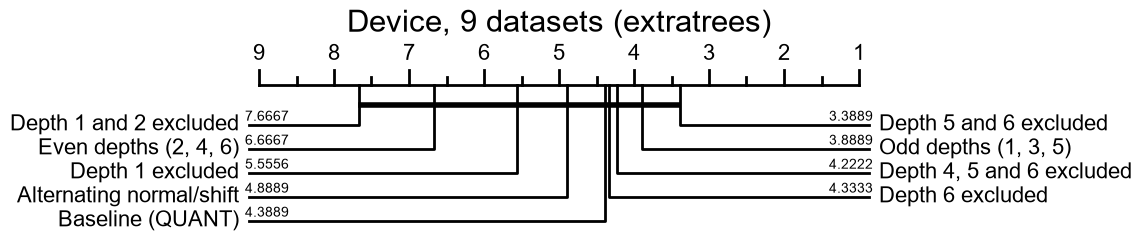

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     1.0
Baseline (QUANT)             0.0
Depth 1 and 2 excluded       0.0
Depth 1 excluded             0.0
Depth 4, 5 and 6 excluded    2.0
Depth 5 and 6 excluded       2.0
Depth 6 excluded             1.0
Even depths (2, 4, 6)        1.0
Odd depths (1, 3, 5)         0.0
dtype: float64
Depth 1 and 2 excluded       7.3750
Odd depths (1, 3, 5)         5.3750
Depth 4, 5 and 6 excluded    5.3125
Even depths (2, 4, 6)        5.2500
Alternating normal/shift     4.8750
Depth 1 excluded             4.8750
Baseline (QUANT)             4.6250
Depth 6 excluded             3.7500
Depth 5 and 6 excluded       3.5625
dtype: float64
('Alternating normal/shift', 'Depth 1 and 2 excluded', np.float64(0.0390625), False)
('Alterna

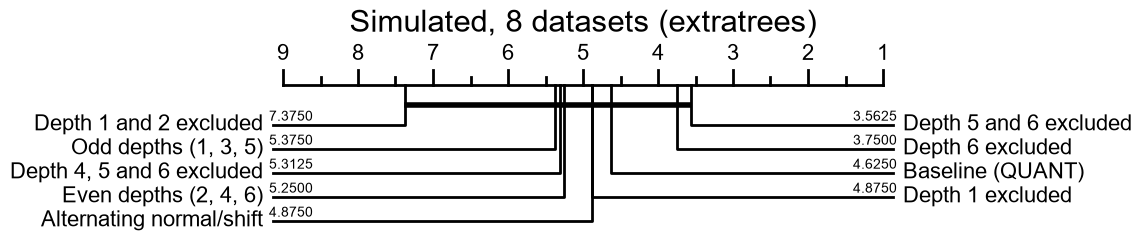

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     0.0
Baseline (QUANT)             0.0
Depth 1 and 2 excluded       0.0
Depth 1 excluded             3.0
Depth 4, 5 and 6 excluded    1.0
Depth 5 and 6 excluded       0.0
Depth 6 excluded             1.0
Even depths (2, 4, 6)        2.0
Odd depths (1, 3, 5)         0.0
dtype: float64
Depth 5 and 6 excluded       7.125
Depth 4, 5 and 6 excluded    7.000
Odd depths (1, 3, 5)         6.125
Alternating normal/shift     5.625
Depth 6 excluded             4.500
Even depths (2, 4, 6)        4.375
Baseline (QUANT)             3.750
Depth 1 and 2 excluded       3.750
Depth 1 excluded             2.750
dtype: float64
('Depth 5 and 6 excluded', 'Depth 6 excluded', np.float64(0.0078125), False)
('Alternating normal/shift

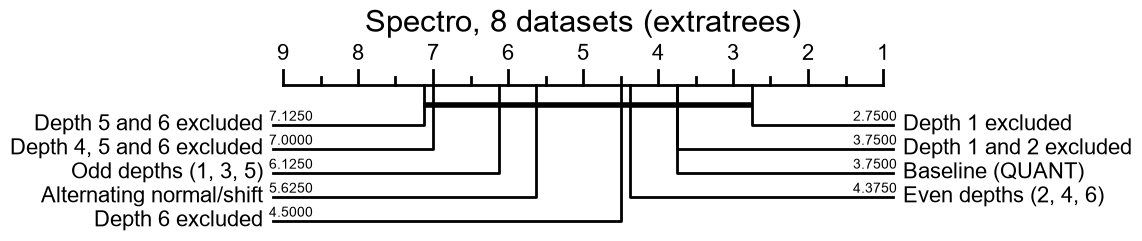

Skipping ECG (extratrees): only 6 datasets (MIN_DATASETS_PER_GROUP = 8).
<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     1.0
Baseline (QUANT)             2.0
Depth 1 and 2 excluded       2.0
Depth 1 excluded             0.0
Depth 4, 5 and 6 excluded    3.0
Depth 5 and 6 excluded       2.0
Depth 6 excluded             3.0
Even depths (2, 4, 6)        1.0
Odd depths (1, 3, 5)         0.0
dtype: float64
Even depths (2, 4, 6)        6.31250
Depth 1 and 2 excluded       6.12500
Depth 1 excluded             5.62500
Depth 4, 5 and 6 excluded    5.37500
Odd depths (1, 3, 5)         5.21875
Alternating normal/shift     4.71875
Depth 5 and 6 excluded       4.56250
Baseline (QUANT)             3.78125
Depth 6 excluded             3.28125
dtype: float64
('Baseline (

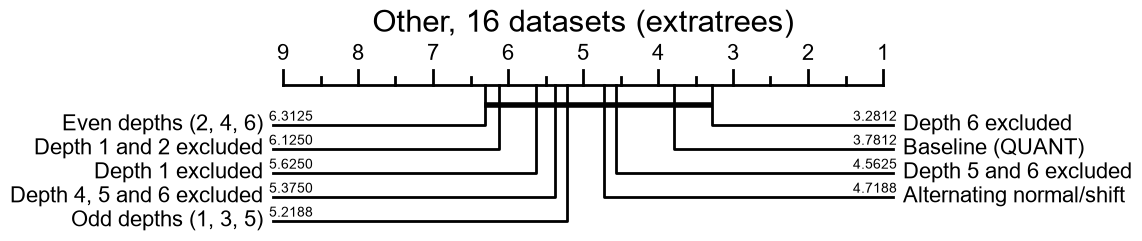

<StringArray>
['Alternating normal/shift', 'Baseline (QUANT)', 'Depth 1 and 2 excluded', 'Depth 1 excluded', 'Depth 4, 5 and 6 excluded', 'Depth 5 and 6 excluded', 'Depth 6 excluded', 'Even depths (2, 4, 6)', 'Odd depths (1, 3, 5)']
Length: 9, dtype: str
Alternating normal/shift     2.0
Baseline (QUANT)             1.0
Depth 1 and 2 excluded       5.0
Depth 1 excluded             2.0
Depth 4, 5 and 6 excluded    1.0
Depth 5 and 6 excluded       2.0
Depth 6 excluded             3.0
Even depths (2, 4, 6)        0.0
Odd depths (1, 3, 5)         3.0
dtype: float64
Even depths (2, 4, 6)        6.526316
Depth 4, 5 and 6 excluded    6.157895
Alternating normal/shift     6.078947
Depth 1 and 2 excluded       5.421053
Odd depths (1, 3, 5)         4.684211
Depth 1 excluded             4.447368
Depth 5 and 6 excluded       4.421053
Baseline (QUANT)             3.947368
Depth 6 excluded             3.315789
dtype: float64
('Baseline (QUANT)', 'Even depths (2, 4, 6)', np.float64(0.00117111206054687

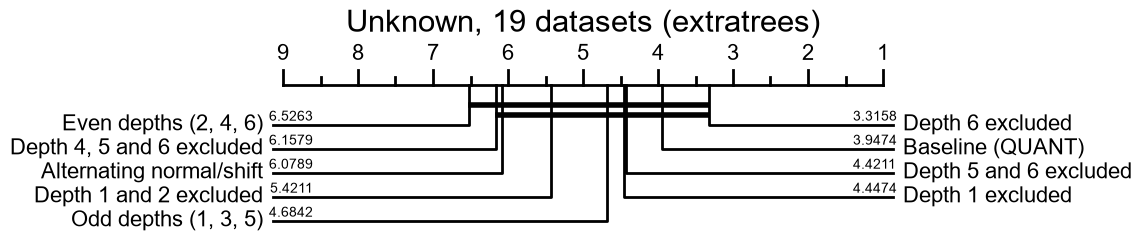

In [14]:
# CD diagram for each dataset-size group and each dataset type: all configurations, ranked within the group.
for grouping, (col, order) in GROUPINGS.items():
    for clf in classifiers:
        for group in order:
            in_group = table[(table["classifier"] == clf) & (table[col] == group)]
            n_ds = in_group["dataset"].nunique()
            short = re.split(r"\s{2}\(|\s\(n=", group)[0]          # "G1: 0–20th pct" or "Image"
            if n_ds < MIN_DATASETS_PER_GROUP:
                print(f"Skipping {short} ({clf}): only {n_ds} datasets (MIN_DATASETS_PER_GROUP = {MIN_DATASETS_PER_GROUP}).")
                continue
            df_perf = (
                in_group.rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
                [["classifier_name", "dataset_name", "accuracy"]]
            )
            slug = re.sub(r"\W+", "_", short).strip("_")
            try:
                draw_cd_diagram(
                    df_perf=df_perf, alpha=CD_ALPHA, title=f"{short}, {n_ds} datasets ({clf})", labels=True,
                    filename=FIG_DIR / f"cd_{clf}_{col}_{slug}.png",
                )
            except RuntimeError as err:                             # Friedman test not significant in this group
                print(f"No diagram for {short} ({clf}): {err}")

### 8b. Datasets significantly different from the baseline (dataset by dataset)

For **each dataset** and each configuration, the baseline and the configuration are compared on the *same resamples* (paired), using the per-resample accuracies, and the datasets with a significant difference are counted. This is a per-dataset test, not a test across datasets.

- `PER_DATASET_TEST = "ttest"` is a paired t-test over the resamples. `"wilcoxon"` is the signed-rank test, but with **5 resamples its smallest possible two-sided p-value is 0.0625, so it can never be significant**; use it only with 6+ resamples (the `run.py` default is 30).
- Resamples share training data, so the variance is underestimated and p-values come out somewhat too small. Treat the counts as indicative, and prefer more resamples.
- Testing many datasets inflates false positives: at α = 0.05 about 5% of datasets are expected to come out "significant" by chance. The **BH-adjusted** columns control the false discovery rate across datasets and are the more trustworthy count.
- Identical differences in every resample give a t-test p-value of 0 (zero variance). For near-ceiling datasets check the size of the difference before counting it.

In [15]:
ALPHA = 0.05
PER_DATASET_TEST = "ttest"       # "ttest" or "wilcoxon"

def bh_adjust(p):
    # Benjamini-Hochberg adjusted p-values (false discovery rate)
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    scaled = p[order] * len(p) / np.arange(1, len(p) + 1)
    adjusted = np.minimum.accumulate(scaled[::-1])[::-1]
    out = np.empty(len(p))
    out[order] = np.minimum(adjusted, 1.0)
    return out

# One row per classifier x dataset x resample, one column per configuration (complete resample sets only).
wide = paired.pivot_table(index=["classifier", "dataset", "resample"], columns="configuration", values="accuracy")

rows = []
for (clf, ds), g in wide.groupby(level=["classifier", "dataset"]):
    for cfg in [c for c in wide.columns if c != BASELINE]:
        diff = (g[cfg] - g[BASELINE]).to_numpy()
        if len(diff) < 2 or np.allclose(diff, 0):
            p = 1.0                                   # identical results: no evidence of a difference
        elif PER_DATASET_TEST == "ttest":
            p = stats.ttest_rel(g[cfg], g[BASELINE]).pvalue
        else:
            p = stats.wilcoxon(diff).pvalue
        rows.append({"classifier": clf, "dataset": ds, "configuration": cfg, "n_resamples": len(diff),
                     "mean_diff_pp": 100 * diff.mean(), "p_value": 1.0 if np.isnan(p) else p})

per_dataset = pd.DataFrame(rows)
if PER_DATASET_TEST == "wilcoxon" and per_dataset["n_resamples"].min() < 6:
    print("WARNING: with fewer than 6 resamples a Wilcoxon test cannot reach p < 0.05; use 'ttest' or more resamples.")

per_dataset["p_adj_bh"] = per_dataset.groupby(["classifier", "configuration"])["p_value"].transform(bh_adjust)
per_dataset["sig"] = per_dataset["p_value"] < ALPHA
per_dataset["sig_bh"] = per_dataset["p_adj_bh"] < ALPHA
for grouping, (col, order) in GROUPINGS.items():
    per_dataset[col] = pd.Categorical(per_dataset["dataset"].map(dataset_groups[col]), categories=order, ordered=True)

def count_significant(frame, keys):
    rows = []
    for key, g in frame.groupby(keys, observed=True):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({
            **dict(zip(keys, key)),
            "datasets": len(g),
            "better (p<α)": int((g["sig"] & (g["mean_diff_pp"] > 0)).sum()),
            "worse (p<α)": int((g["sig"] & (g["mean_diff_pp"] < 0)).sum()),
            "not significant": int((~g["sig"]).sum()),
            "better (BH)": int((g["sig_bh"] & (g["mean_diff_pp"] > 0)).sum()),
            "worse (BH)": int((g["sig_bh"] & (g["mean_diff_pp"] < 0)).sum()),
            "expected by chance": round(ALPHA * len(g), 1),
        })
    return pd.DataFrame(rows).set_index(keys)

print(f"Datasets with a significant difference from '{BASELINE}' ({PER_DATASET_TEST}, alpha = {ALPHA}):")
display(count_significant(per_dataset, ["classifier", "configuration"]))
for grouping, (col, order) in GROUPINGS.items():
    print(f"\nBy {grouping}:")
    display(count_significant(per_dataset, ["classifier", "configuration", col]))

print("\nDatasets that remain significant after BH correction:")
display(
    per_dataset.loc[per_dataset["sig_bh"], ["classifier", "configuration", "dataset", "size_group", "type_group",
                                            "mean_diff_pp", "p_value", "p_adj_bh"]]
    .sort_values(["classifier", "configuration", "p_adj_bh"]).round(4)
)

Datasets with a significant difference from 'Baseline (QUANT)' (ttest, alpha = 0.05):


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration                                                                                                               
extratrees Alternating normal/shift        142             9           54               79            8          47                 7.1
           Depth 1 and 2 excluded          142            11           63               68            8          55                 7.1
           Depth 1 excluded                142            10           37               95            6          29                 7.1
           Depth 4, 5 and 6 excluded       142            19           59               64           18          59                 7.1
           Depth 5 and 6 excluded          142            26           41               75           22          35                 7.1
           Depth 6 excluded                142            17           18              107           11          12                 7.1
           Even depths (2, 4, 6)           142             3           69               70            3          64                 7.1
           Odd depths (1, 3, 5)            142             9           48               85            6          39                 7.1


By size group:


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration             size_group                                                                                                                                    
extratrees Alternating normal/shift  G1: 0–20th pct  (size 0.00949–0.0504, n=29)        29             2            6               21            1           6                 1.5
                                     G2: 20–40th pct  (size 0.0508–0.0727, n=28)        28             1           10               17            1           8                 1.4
                                     G3: 40–60th pct  (size 0.0757–0.119, n=28)         28             1           12               15            1           9                 1.4
                                     G4: 60–80th pct  (size 0.12–0.185, n=28)           28             2           11               15            2          10                 1.4
                                     G5: 80–100th pct  (size 0.212–1.66, n=29)          29             3           15               11            3          14                 1.5
           Depth 1 and 2 excluded    G1: 0–20th pct  (size 0.00949–0.0504, n=29)        29             5           13               11            4          11                 1.5
                                     G2: 20–40th pct  (size 0.0508–0.0727, n=28)        28             1            5               22            1           4                 1.4
                                     G3: 40–60th pct  (size 0.0757–0.119, n=28)         28             2           15               11            2          13                 1.4
                                     G4: 60–80th pct  (size 0.12–0.185, n=28)           28             2           15               11            1          15                 1.4
                                     G5: 80–100th pct  (size 0.212–1.66, n=29)          29             1           15               13            0          12                 1.5
           Depth 1 excluded          G1: 0–20th pct  (size 0.00949–0.0504, n=29)        29             4            6               19            2           5                 1.5
                                     G2: 20–40th pct  (size 0.0508–0.0727, n=28)        28             2            3               23            1           2                 1.4
                                     G3: 40–60th pct  (size 0.0757–0.119, n=28)         28             2            9               17            1           6                 1.4
                                     G4: 60–80th pct  (size 0.12–0.185, n=28)           28             1           10               17            1           9                 1.4
                                     G5: 80–100th pct  (size 0.212–1.66, n=29)          29             1            9               19            1           7                 1.5
           Depth 4, 5 and 6 excluded G1: 0–20th pct  (size 0.00949–0.0504, n=29)        29             2           14               13            2          14                 1.5
                                     G2: 20–40th pct  (size 0.0508–0.0727, n=28)        28             1            9               18            1           9                 1.4
                                     G3: 40–60th pct  (size 0.0757–0.119, n=28)         28             4           12               12            4          12                 1.4
                                     G4: 60–80th pct  (size 0.12–0.185, n=28)           28             6            9               13            5           9                 1.4
                                     G5: 80–100th pct  (size 0.212–1.66, n=29)          29             6           15                8            6          15                 1.5
           Depth 5 and 6 excluded    G1: 0–20th pct  (size 0.00949–0.0504, n=29)        29             2           10     


By dataset type:


datasets  better (p<α)  worse (p<α)  not significant  better (BH)  worse (BH)  expected by chance
classifier configuration            type_group                                                                                                        
extratrees Alternating normal/shift Image (n=32)           32             1           16               15            1          15                 1.6
                                    Sensor (n=27)          27             2           12               13            2          11                 1.4
                                    Motion (n=17)          17             1            7                9            0           6                 0.9
                                    Device (n=9)            9             1            1                7            1           1                 0.5
                                    Simulated (n=8)         8             2            1                5            2           1                 0.4
...                                                       ...           ...          ...              ...          ...         ...                 ...
           Odd depths (1, 3, 5)     Simulated (n=8)         8             0            3                5            0           3                 0.4
                                    Spectro (n=8)           8             0            5                3            0           5                 0.4
                                    ECG (n=6)               6             0            4                2            0           4                 0.3
                                    Other (n=16)           16             1            5               10            0           5                 0.8
                                    Unknown (n=19)         19             1            5               13            1           4                 1.0

[72 rows x 7 columns]


Datasets that remain significant after BH correction:


,classifier,configuration,dataset,size_group,type_group,mean_diff_pp,p_value,p_adj_bh
216,extratrees,Alternating normal/shift,Crop,"G4: 60–80th pct (size 0.12–0.185, n=28)",Image (n=32),-0.9030,0.0000,0.0000
144,extratrees,Alternating normal/shift,ChlorineConcentration,"G3: 40–60th pct (size 0.0757–0.119, n=28)",Sensor (n=27),-0.9080,0.0000,0.0000
16,extratrees,Alternating normal/shift,AconityMINIPrinterSmall_eq,"G4: 60–80th pct (size 0.12–0.185, n=28)",Unknown (n=19),-0.8904,0.0000,0.0000
712,extratrees,Alternating normal/shift,NonInvasiveFetalECGThorax1,"G5: 80–100th pct (size 0.212–1.66, n=29)",ECG (n=6),-0.5276,0.0000,0.0000
368,extratrees,Alternating normal/shift,FacesUCR,"G2: 20–40th pct (size 0.0508–0.0727, n=28)",Image (n=32),-0.9984,0.0000,0.0000
...,...,...,...,...,...,...,...,...
823,extratrees,"Odd depths (1, 3, 5)",PowerCons,"G2: 20–40th pct (size 0.0508–0.0727, n=28)",Other (n=16),-0.3889,0.0113,0.0393
15,extratrees,"Odd depths (1, 3, 5)",AconityMINIPrinterLarge_eq,"G5: 80–100th pct (size 0.212–1.66, n=29)",Unknown (n=19),-0.1745,0.0125,0.0423
591,extratrees,"Odd depths (1, 3, 5)",InsectWingbeatSound,"G3: 40–60th pct (size 0.0757–0.119, n=28)",Sensor (n=27),-0.3956,0.0134,0.0444
295,extratrees,"Odd depths (1, 3, 5)",ECG5000,"G3: 40–60th pct (size 0.0757–0.119, n=28)",ECG (n=6),-0.0593,0.0145,0.0467


## 9. Accuracy vs training time graph

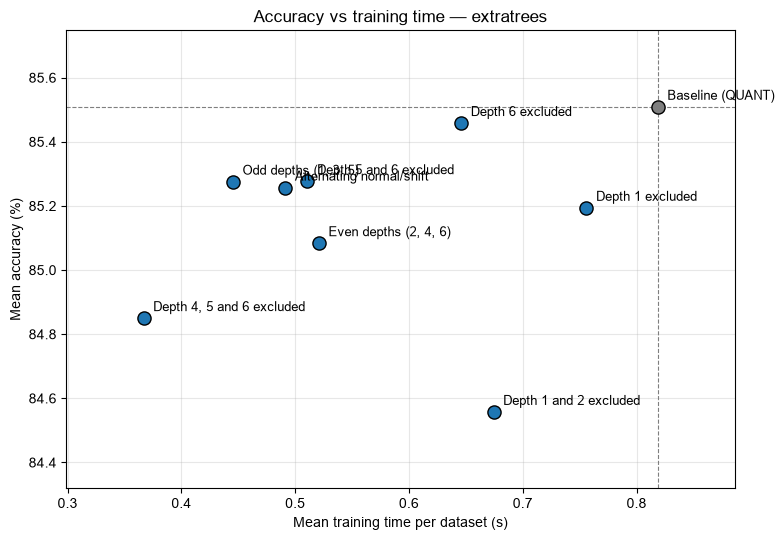

In [16]:
# ===== Accuracy vs training time: one point per experiment (original configurations only) =====
ACC_COL, TIME_COL = "accuracy", "time_train_total"        # columns in `table`
order = list(dict.fromkeys(CONFIG_LABELS.values()))

for clf in classifiers:
    sub = table[table["classifier"] == clf]
    means = (sub.groupby("configuration", observed=True)[[ACC_COL, TIME_COL]].mean()
                .reindex([c for c in order if c in set(sub["configuration"])]))
    acc = 100 * means[ACC_COL]
    time_ = means[TIME_COL]

    fig, ax = plt.subplots(figsize=(8, 5.5))
    for cfg in means.index:
        is_base = cfg == BASELINE
        ax.scatter(time_[cfg], acc[cfg], s=90, color="tab:gray" if is_base else "tab:blue",
                   edgecolor="black", zorder=3)
        ax.annotate(cfg, (time_[cfg], acc[cfg]), xytext=(7, 5), textcoords="offset points", fontsize=9)

    # Dashed guides through the baseline: left of the vertical line = faster, above the horizontal line = more accurate.
    ax.axvline(time_[BASELINE], color="tab:gray", linestyle="--", linewidth=0.8)
    ax.axhline(acc[BASELINE], color="tab:gray", linestyle="--", linewidth=0.8)

    ax.set(xlabel="Mean training time per dataset (s)",
           ylabel="Mean accuracy (%)",
           title=f"Accuracy vs training time — {clf}")
    ax.margins(x=0.15, y=0.25)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"accuracy_vs_time_{clf}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Single Depth Removed Analysis

## 1.Load and validate

Missing or malformed files are reported rather than silently skipped, and the notebook stops if the baseline is not available.

In [17]:
# Reuses RESULTS_DIR, CONFIG_LABELS, BASELINE, REQUIRED, NUMERIC and TIME_AGG from the main analysis.
ABLATION_DEPTHS = range(1, 7)
ABLATION_LABELS = {f"no_depth_{d}": f"No depth {d}" for d in ABLATION_DEPTHS}   # CSV stem -> label
# (no_depth_6 is the same experiment as "Depth 6 excluded" above; it is simply loaded again here.)

baseline_stem = next(stem for stem, label in CONFIG_LABELS.items() if label == BASELINE)
abl_stems = {baseline_stem: BASELINE, **ABLATION_LABELS}

abl_frames = []
for stem, label in abl_stems.items():
    path = RESULTS_DIR / f"{stem}.csv"
    try:
        frame_ = pd.read_csv(path)
    except Exception as exc:
        print(f"Skipping {path.name}: {exc}")
        continue
    missing_cols = sorted(REQUIRED - set(frame_.columns))
    if missing_cols:
        print(f"Skipping {path.name}: missing columns {missing_cols}")
        continue
    frame_["configuration"] = label
    for col in NUMERIC:
        frame_[col] = pd.to_numeric(frame_[col], errors="coerce") if col in frame_ else np.nan
    frame_["resample"] = pd.to_numeric(frame_["resample"], errors="coerce")
    frame_["status"] = frame_["status"].fillna("").astype(str)
    abl_frames.append(frame_)

abl_results = pd.concat(abl_frames, ignore_index=True, sort=False)
if CLASSIFIERS is not None:
    abl_results = abl_results[abl_results["classifier"].isin(CLASSIFIERS)]
abl_results = abl_results.drop_duplicates(["configuration", "dataset", "classifier", "resample"])

abl_ok = abl_results[abl_results["status"].str.lower().eq("ok") & abl_results["accuracy"].notna()].copy()
abl_ok["time_train_total"] = abl_ok["time_transform_train"] + abl_ok["time_fit"]
abl_ok["time_test_total"] = abl_ok["time_transform_test"] + abl_ok["time_predict"]

# Keep only resamples that succeeded in every loaded configuration (paired splits).
abl_configs = sorted(abl_ok["configuration"].unique())
absent = [label for label in abl_stems.values() if label not in abl_configs]
if absent:
    print("WARNING: no usable results for:", absent)
n_cfg = abl_ok.groupby(["dataset", "classifier", "resample"])["configuration"].transform("nunique")
abl_paired = abl_ok[n_cfg == len(abl_configs)].copy()
print(f"{len(abl_configs)} configurations; kept {len(abl_paired):,} of {len(abl_ok):,} successful runs "
      f"({abl_paired['dataset'].nunique()} datasets).")

abl_spec = {
    "accuracy": ("accuracy", "mean"), "balanced_accuracy": ("balanced_accuracy", "mean"),
    "n_features": ("n_features", "mean"), "n_resamples": ("resample", "nunique"),
    "time_train_total": ("time_train_total", TIME_AGG), "time_test_total": ("time_test_total", TIME_AGG),
}
abl_table = abl_paired.groupby(["dataset", "classifier", "configuration"], as_index=False).agg(**abl_spec)
abl_table["error"] = 1 - abl_table["accuracy"]
display(abl_table.groupby("configuration").agg(datasets=("dataset", "nunique"),
                                               resamples_min=("n_resamples", "min"),
                                               resamples_max=("n_resamples", "max")))

7 configurations; kept 29,820 of 29,820 successful runs (142 datasets).


,datasets,resamples_min,resamples_max
configuration,,,
Baseline (QUANT),142,30,30
No depth 1,142,30,30
No depth 2,142,30,30
No depth 3,142,30,30
No depth 4,142,30,30
No depth 5,142,30,30
No depth 6,142,30,30


## 2. Per-dataset comparison with the baseline

For each non-baseline configuration and dataset (all values positive = better than baseline unless noted):

- **Accuracy difference** (percentage points): $\Delta A = A_{\text{new}} - A_{\text{baseline}}$
- **Relative error reduction** (%): $\dfrac{E_{\text{baseline}} - E_{\text{new}}}{E_{\text{baseline}}}$, where $E = 1 - A$. This is **undefined when the baseline error is 0** (a perfect baseline), so those datasets are left out of this one metric (reported below) instead of producing `-inf`/`NaN`.
- **Smoothed error ratio**: $\dfrac{E_{\text{new}} + \varepsilon}{E_{\text{baseline}} + \varepsilon}$ with a small pseudo-error $\varepsilon$ (`ERROR_EPS`) added to both errors, averaged on the log scale (geometric mean). Unlike relative error reduction it is defined for perfect baselines and cannot be dominated by one or two test-case errors on a near-perfect dataset. 1.0 = no change, 1.2 = 20% more error.
- **Feature, training-time and test-time reduction** (%): $\dfrac{X_{\text{baseline}} - X_{\text{new}}}{X_{\text{baseline}}}$. Training time is `time_transform_train + time_fit`; test time is `time_transform_test + time_predict`.

In [18]:
ABL_BASE_COLS = ["accuracy", "error", "n_features", "time_train_total", "time_test_total"]
abl_base = (abl_table[abl_table["configuration"] == BASELINE]
            .set_index(["dataset", "classifier"])[ABL_BASE_COLS].add_prefix("base_"))
abl_cmp = (abl_table[abl_table["configuration"] != BASELINE]
           .join(abl_base, on=["dataset", "classifier"]).dropna(subset=["base_accuracy"]).copy())

abl_cmp["acc_diff_pp"] = 100 * (abl_cmp["accuracy"] - abl_cmp["base_accuracy"])
abl_cmp["error_reduction_pct"] = pct_reduction(abl_cmp["error"], abl_cmp["base_error"])
abl_cmp["log2_error_ratio"] = np.log2((abl_cmp["error"] + ERROR_EPS) / (abl_cmp["base_error"] + ERROR_EPS))
abl_cmp["feature_reduction_pct"] = pct_reduction(abl_cmp["n_features"], abl_cmp["base_n_features"])
abl_cmp["train_time_reduction_pct"] = pct_reduction(abl_cmp["time_train_total"], abl_cmp["base_time_train_total"])
abl_cmp["test_time_reduction_pct"] = pct_reduction(abl_cmp["time_test_total"], abl_cmp["base_time_test_total"])

# Groups (dataset size and dataset type) from the main analysis, and depth order for tables/plots.
for col, order in GROUPINGS.values():
    abl_cmp[col] = pd.Categorical(abl_cmp["dataset"].map(dataset_groups[col]), categories=order, ordered=True)
ABL_PRESENT = [label for label in ABLATION_LABELS.values() if label in set(abl_cmp["configuration"])]
abl_cmp["configuration"] = pd.Categorical(abl_cmp["configuration"], categories=ABL_PRESENT, ordered=True)
ABL_SHORT = {label: label.replace("No depth ", "") for label in ABL_PRESENT}      # "No depth 3" -> "3"

## 3. Depth removal analysis

### 3a. Depth ranking 
Assessing which depths mattered most in classification accuracy, ranked by mean accuracy change when removed

In [19]:
def holm(p):
    # Holm-adjusted p-values (family = the depths tested); NaNs are left as NaN.
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    valid = p.dropna().sort_values()
    m = len(valid)
    out[valid.index] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * valid.to_numpy()))
    return out

abl_summary = summarise(abl_cmp, ["classifier", "configuration"])
abl_summary["Wilcoxon p (Holm)"] = abl_summary.groupby("classifier")["Wilcoxon p"].transform(holm)
# 1 = removing this depth hurts accuracy the most
abl_summary["importance rank"] = abl_summary.groupby("classifier")["acc diff mean (pp)"].rank(method="min").astype(int)

cols = ["classifier", "configuration", "importance rank", "datasets", "acc diff mean (pp)", "95% CI",
        "acc diff median (pp)", "improved", "tied", "declined", "Wilcoxon p", "Wilcoxon p (Holm)",
        "smoothed error ratio (geo. mean)", "feature red. mean (%)", "train time red. mean (%)",
        "test time red. mean (%)"]
display(abl_summary.sort_values(["classifier", "importance rank"])[cols].round(4).reset_index(drop=True))

,classifier,configuration,importance rank,datasets,acc diff mean (pp),95% CI,acc diff median (pp),improved,tied,declined,Wilcoxon p,Wilcoxon p (Holm),smoothed error ratio (geo. mean),feature red. mean (%),train time red. mean (%),test time red. mean (%)
0,extratrees,No depth 1,1,142,-0.3150,"[-0.51, -0.15]",-0.0350,55,10,77,0.0005,0.0020,1.0306,9.3477,3.5593,4.6503
1,extratrees,No depth 2,2,142,-0.1771,"[-0.31, -0.07]",-0.0580,51,6,85,0.0004,0.0020,1.0247,14.0844,11.6104,13.7172
2,extratrees,No depth 3,3,142,-0.0790,"[-0.15, -0.00]",-0.0848,40,5,97,0.0001,0.0006,1.0247,16.7131,14.9592,18.0282
3,extratrees,No depth 4,4,142,-0.0523,"[-0.12, 0.01]",-0.0243,54,5,83,0.0113,0.0338,1.0166,18.7231,16.7782,21.1145
4,extratrees,No depth 6,5,142,-0.0507,"[-0.13, 0.02]",0.0000,67,11,64,0.3439,0.3439,1.0100,21.1747,16.5795,26.0196
5,extratrees,No depth 5,6,142,-0.0498,"[-0.12, 0.02]",0.0000,68,6,68,0.1426,0.2852,1.0129,19.9569,18.5217,25.0919


### 3b. Depth significance

Accuracy change (with 95% CI) and cost saved, by depth removed

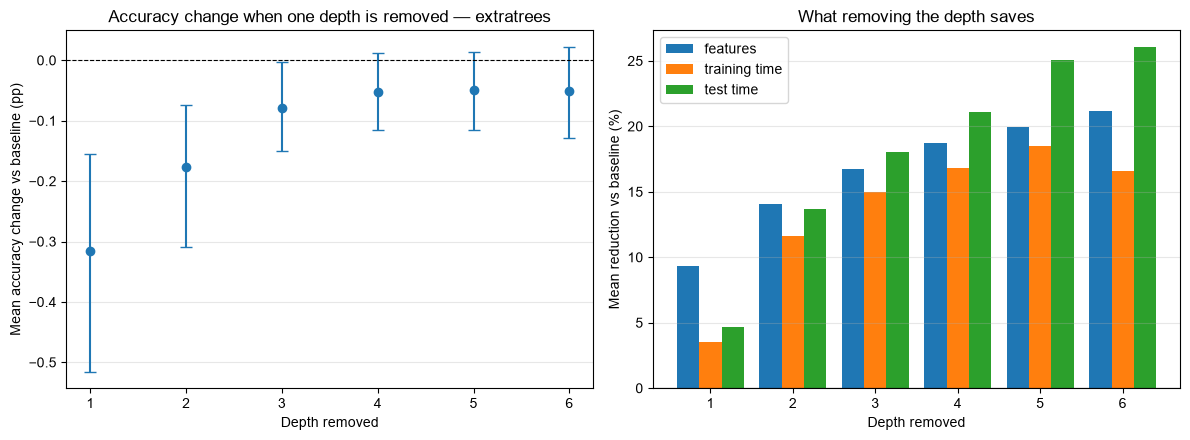

In [20]:
for clf in classifiers:
    sub = abl_cmp[abl_cmp["classifier"] == clf]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    for i, cfg in enumerate(ABL_PRESENT):
        d = sub.loc[sub["configuration"] == cfg, "acc_diff_pp"].to_numpy()
        if len(d) == 0:
            continue
        lo, hi = bootstrap_ci(d)
        ax1.errorbar(i, d.mean(), yerr=[[d.mean() - lo], [hi - d.mean()]], fmt="o", capsize=4, color="tab:blue")
    ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax1.set_xticks(range(len(ABL_PRESENT)), [ABL_SHORT[c] for c in ABL_PRESENT])
    ax1.set(xlabel="Depth removed", ylabel="Mean accuracy change vs baseline (pp)",
            title=f"Accuracy change when one depth is removed — {clf}")
    ax1.grid(axis="y", alpha=0.3)

    cost = sub.groupby("configuration", observed=True)[["feature_reduction_pct", "train_time_reduction_pct",
                                                         "test_time_reduction_pct"]].mean().reindex(ABL_PRESENT)
    x = np.arange(len(ABL_PRESENT))
    for k, (colname, label) in enumerate([("feature_reduction_pct", "features"),
                                          ("train_time_reduction_pct", "training time"),
                                          ("test_time_reduction_pct", "test time")]):
        ax2.bar(x + (k - 1) * 0.27, cost[colname], width=0.27, label=label)
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.set_xticks(x, [ABL_SHORT[c] for c in ABL_PRESENT])
    ax2.set(xlabel="Depth removed", ylabel="Mean reduction vs baseline (%)", title="What removing the depth saves")
    ax2.legend()
    ax2.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

### 3c. Depth importance by dataset

Assessing accuracy change compared to the baseline by dataset type and size

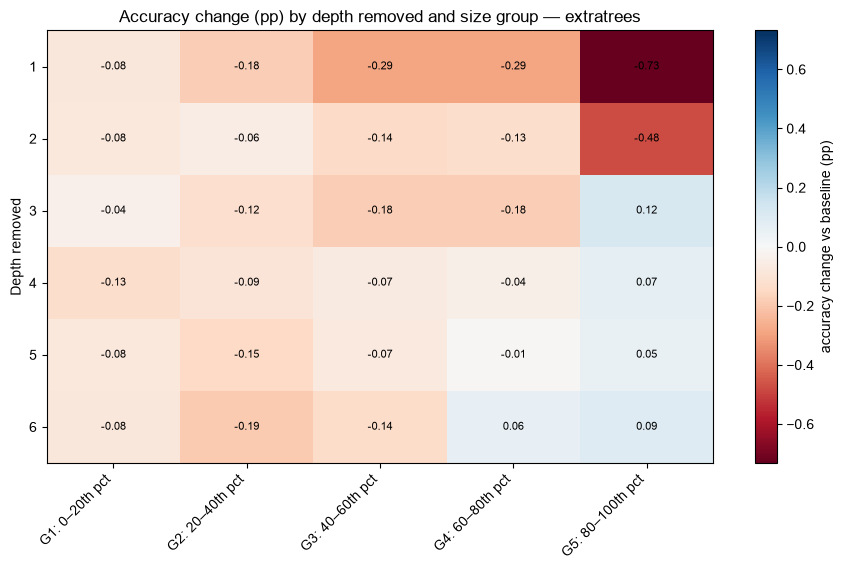

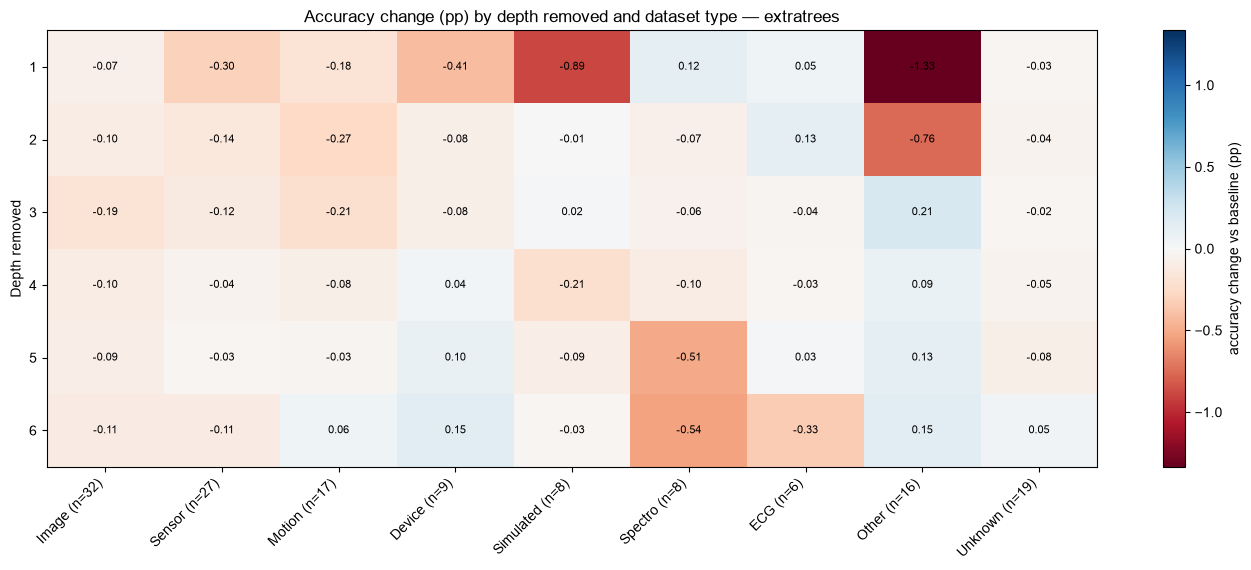

In [21]:
# ===== Does the importance of a depth depend on dataset type or size? =====
# Cell value = mean accuracy change (pp) when that depth is removed. Red = accuracy loss, blue = gain.
def short_group(name):
    return re.split(r"\s{2}\(", name)[0]          # drops the size range, keeps "G1: 0–20th pct" / "Image (n=32)"

for grouping, (col, order) in GROUPINGS.items():
    for clf in classifiers:
        mat = (abl_cmp[abl_cmp["classifier"] == clf]
               .pivot_table(index="configuration", columns=col, values="acc_diff_pp", aggfunc="mean", observed=True))
        mat = mat.reindex(index=ABL_PRESENT, columns=[g for g in order if g in mat.columns])
        lim = np.nanmax(np.abs(mat.to_numpy()))
        fig, ax = plt.subplots(figsize=(1.2 * mat.shape[1] + 3, 0.6 * mat.shape[0] + 2.2))
        im = ax.imshow(mat.to_numpy(), cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
        ax.set_xticks(range(mat.shape[1]), [short_group(g) for g in mat.columns], rotation=45, ha="right")
        ax.set_yticks(range(mat.shape[0]), [ABL_SHORT[c] for c in mat.index])
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                if not np.isnan(mat.iat[i, j]):
                    ax.text(j, i, f"{mat.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
        ax.set(ylabel="Depth removed", title=f"Accuracy change (pp) by depth removed and {grouping} — {clf}")
        fig.colorbar(im, ax=ax, label="accuracy change vs baseline (pp)")
        fig.tight_layout()
        plt.show()

## 4. Critical difference diagrams (across datasets)

Uses the Friedman test followed by Wilcoxon-Holm pairwise tests on the **per-dataset mean accuracies** (Demšar 2006; [hfawaz/cd-diagram](https://github.com/hfawaz/cd-diagram)). Methods joined by a thick bar are **not** significantly different. The first cell draws one diagram per classifier and per experiment group in `EXPERIMENT_GROUPS` (the baseline is always included); the second draws one per dataset-size group and one per dataset type.

Requires `cd_diagram.py`: the repo's `main.py`, renamed and with four small patches (no forced `agg` backend, no `exit()`, an output-file argument, and the example code guarded by `if __name__ == "__main__"`). The Friedman test needs at least 3 methods in a diagram, i.e. the baseline plus at least 2 configurations.

A significant rank difference means the configuration is *consistently* better or worse across datasets, not that the difference is large. Read it together with the accuracy differences in section 6. Groups contain only a few dozen datasets (or fewer), so "no significant difference" in a group mostly means low power, not evidence of equivalence.

<StringArray>
['Baseline (QUANT)', 'No depth 1', 'No depth 2', 'No depth 3', 'No depth 4', 'No depth 5', 'No depth 6']
Length: 7, dtype: str
Baseline (QUANT)    14.0
No depth 1          22.0
No depth 2          21.0
No depth 3          13.0
No depth 4           7.0
No depth 5          20.0
No depth 6          33.0
dtype: float64
No depth 3          4.461268
No depth 1          4.302817
No depth 2          4.239437
No depth 4          4.102113
No depth 5          3.760563
No depth 6          3.623239
Baseline (QUANT)    3.510563
dtype: float64
('Baseline (QUANT)', 'No depth 3', np.float64(6.649861315988879e-05), True)
('Baseline (QUANT)', 'No depth 2', np.float64(0.0004296508413475711), True)
('Baseline (QUANT)', 'No depth 1', np.float64(0.0007771858948586537), True)
('Baseline (QUANT)', 'No depth 4', np.float64(0.01078181424418762), False)
('No depth 1', 'No depth 6', np.float64(0.02449281256097562), False)
('No depth 1', 'No depth 5', np.float64(0.038922423747895), False)
('No depth 2

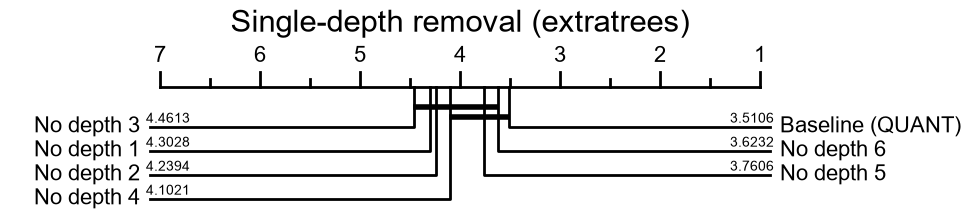

In [22]:
for clf in classifiers:
    names = [BASELINE] + ABL_PRESENT
    df_perf = (abl_table[(abl_table["classifier"] == clf) & abl_table["configuration"].isin(names)]
               .rename(columns={"configuration": "classifier_name", "dataset": "dataset_name"})
               [["classifier_name", "dataset_name", "accuracy"]])
    try:
        draw_cd_diagram(df_perf=df_perf, alpha=CD_ALPHA, title=f"Single-depth removal ({clf})", labels=True,
                        filename=FIG_DIR / f"cd_{clf}_single_depth_removal.png")
    except RuntimeError as err:                      # Friedman test not significant
        print(f"No diagram ({clf}): {err}")

## 5. Depth substitution

Do depths substitute for each other? Removing 5 and 6 together vs the sum of removing each alone. 

<i>Note: This is an exploratory measure of interaction, not a definitive measure of redundancy</i> 

In [25]:
# interaction = (effect of removing both) - (effect of removing 5 alone + effect of removing 6 alone), per dataset.
# > 0: removing both costs LESS than the sum, i.e. the two depths are partly redundant.
PAIR_LABEL = "Depth 5 and 6 excluded"        # label from CONFIG_LABELS in the main analysis
needed = ["No depth 5", "No depth 6"]
if PAIR_LABEL in set(cmp["configuration"]) and all(n in ABL_PRESENT for n in needed):
    for clf in classifiers:
        single = (abl_cmp[(abl_cmp["classifier"] == clf) & abl_cmp["configuration"].isin(needed)]
                  .pivot_table(index="dataset", columns="configuration", values="acc_diff_pp", observed=True))
        both = cmp[(cmp["classifier"] == clf) & (cmp["configuration"] == PAIR_LABEL)].set_index("dataset")["acc_diff_pp"]
        inter = (both - single.sum(axis=1)).dropna()
        lo, hi = bootstrap_ci(inter.to_numpy())
        print(f"{clf}: removing 5 and 6 together = {both.mean():+.3f} pp; "
              f"sum of removing each alone = {single.sum(axis=1).mean():+.3f} pp")
        print(f"       interaction = {inter.mean():+.3f} pp, 95% CI [{lo:.3f}, {hi:.3f}] over {len(inter)} datasets")
else:
    print(f"Skipped: needs '{PAIR_LABEL}' in the main analysis and No depth 5 / No depth 6 loaded above.")

extratrees: removing 5 and 6 together = -0.232 pp; sum of removing each alone = -0.100 pp
       interaction = -0.132 pp, 95% CI [-0.236, -0.038] over 142 datasets


### Main statistics mentioned in findings

In [24]:
summary_table = overall.copy()

# Combine the accuracy difference and confidence interval
summary_table["Mean accuracy difference (95% CI)"] = (
    summary_table["acc diff mean (pp)"].map(lambda x: f"{x:+.3f}")
    + " "
    + summary_table["95% CI"]
)

# Combine improved / tied / declined dataset counts
summary_table["Improved / tied / declined"] = (
    summary_table["improved"].astype(str) + " / "
    + summary_table["tied"].astype(str) + " / "
    + summary_table["declined"].astype(str)
)

# Select and rename the requested statistics
summary_table = summary_table[
    [
        "classifier",
        "configuration",
        "Mean accuracy difference (95% CI)",
        "Improved / tied / declined",
        "Wilcoxon p",
        "feature red. mean (%)",
        "train time red. mean (%)",
        "test time red. mean (%)"
    ]
].rename(columns={
    "classifier": "Model",
    "configuration": "Configuration",
    "Wilcoxon p": "Wilcoxon p-value",
    "feature red. mean (%)": "Features reduced (%)",
    "train time red. mean (%)": "Training time reduced (%)",
    "test time red. mean (%)": "Test time reduced (%)"
})

# Format numerical statistics
summary_table["Wilcoxon p-value"] = summary_table["Wilcoxon p-value"].map(
    lambda x: f"{x:.4g}" if pd.notna(x) else "N/A"
)

for col in [
    "Features reduced (%)",
    "Training time reduced (%)",
    "Test time reduced (%)"
]:
    summary_table[col] = summary_table[col].map(
        lambda x: f"{x:.2f}" if pd.notna(x) else "N/A"
    )

# Display with models/configurations as rows
summary_table = summary_table.set_index(["Model", "Configuration"])

display(summary_table)

Mean accuracy difference (95% CI) Improved / tied / declined Wilcoxon p-value Features reduced (%) Training time reduced (%) Test time reduced (%)
Model      Configuration                                                                                                                                                               
extratrees Alternating normal/shift              -0.252 [-0.34, -0.17]               30 / 5 / 107        3.257e-09                46.99                     28.29                 40.25
           Depth 1 and 2 excluded                -0.952 [-1.55, -0.50]                42 / 4 / 96        2.703e-09                23.43                     10.32                 12.80
           Depth 1 excluded                      -0.315 [-0.51, -0.16]               55 / 10 / 77        0.0004692                 9.35                      3.56                  4.65
           Depth 4, 5 and 6 excluded             -0.659 [-1.01, -0.34]                46 / 5 / 91        3.791e-06                59.85                     42.88                 61.77
           Depth 5 and 6 excluded                -0.232 [-0.43, -0.06]                58 / 6 / 78          0.03017                41.13                     28.89                 44.07
           Depth 6 excluded                       -0.051 [-0.13, 0.02]               67 / 11 / 64           0.3439                21.17                     16.58                 26.02
           Even depths (2, 4, 6)                 -0.425 [-0.57, -0.31]               33 / 6 / 103        4.866e-13                46.02                     23.49                 32.64
           Odd depths (1, 3, 5)                  -0.234 [-0.35, -0.13]                57 / 5 / 80        0.0001449                53.98                     33.10                 48.18

# Analysis

As stated at the start of the notebook, the most promising tests are those that remove depths 6, depths 5 and 6 and that only kept even depths. First, we will briefly clarify why the other experiments were disregarded.

## Removing early depths

Initial tests included removing depth 1 intervals and depth 1 and 2 intervals from feature extraction. The initial hypothesis was that such high level intervals (only 1 and 3 intervals respectively) is too substantial of a generalisation, and doesn't capture any of the original datasets shape.

Early testing proved these experiments to be worse than the original experiments overall. Excluding depth 1 caused an average accuracy reduction of 0.32%, with 77 of the datasets having a reduction in accuracy. The effects of removing depths 1 and 2 resulted in a much greater reduction in performance, with a 0.95% reduction in accuracy and 96 datasets performing worse than the original configuration. The results for both of these configurations were also considered statistically significant according to Wilcoxon signed rank tests and did not largely reduce the computational cost. With a 9.35% and 23.43% reduction in feature count on average, the depth 1 and depth 1 and 2 excluded experiments only had a 3.56% and 10.32% reduction in training time and 4.65% and 12.80% reduction in test time respectively.

These tests seem to indicate the usefulness of longer intervals. Particularly, information provided by interval 1 essentially serves as a summarisation of the entire sample, representing the median along with other upper and lower quantiles, which provide a good description of the overall distribution of the dataset. This early depth information has proven to be important across most datasets.

## Alternating depths, odd depths and even depths

These tests included only taking intervals at even depth values (1, 3, 5), even depth values (2, 4, 6) and alternating between taking normal depth intervals (1, 3, 5) and shift depth intervals (2, 4, 6). The initial hypothesis of taking intervals in this way was that data represented by the removed depths could be represented by the depths above and below to enough of a degree to maintain accuracy while reducing the features needed.

Early experiments with only odd depths proved to be beneficial overall, maintaining a reasonable level of accuracy while resulting in a substantial reduction in training time and feature count. Keeping only odd depths reduced the average accuracy across all datasets by 0.23% compared to the baseline, however 80 of the datasets had a reduction in accuracy overall. This configuration was also found to be significant by Wilcoxon signed rank testing. However, this test also had a significant reduction in computation compared to the baseline, with a 53.98% reduction in feature count which led to a 33.10% and 48.18% reduction in training time respectively. 

This method may have performed well overall since it maintained enough depth information to fairly represent the depths that were removed, while removing lower depths (4 and 6), which carry a substantial number of features compared to others.

Early tests with alternating depths proved the performance of this method to be reasonable, but was out performed by both the baseline performance and other experiment configurations. Alternating depths as described lead to an average accuracy reduction of 0.25%, with 107 datasets performing worse than the baseline. This approach did reduce feature count by 46.99%, training time by 28.29% and test time by 40.25%, however these reductions were not as significant as those from removal of even depths. This method also had slightly larger average accuracy reduction than even depths, making even depths a better alternative overall. 

This method may have suffered due to the removal of relational information between original and shifted intervals at each depth. Shifted intervals have the same length as normal intervals at each depth, so the model may be able to use this relationship to better understand the shape of the dataset.

Experimentation with only even depths (2, 4, 6) was conducted after the success of experimentation with odd depths (1, 3, 5). However, this method resulted in reduced overall performance compared experimentation with odd depths. This method had an average accuracy reduction of 0.43%, while odd depths only reduced by 0.23%. Removal of even depths also had a reduced accuracy in 103 datasets compared to odd depths 80. Removal of even depths also only reduced the number of features by 46.02% while odd depth removal reduced it by 53.98%.

This method likely suffered in terms of accuracy compared to odd depths experimentation due to the importance of the depths that were removed. Initial experimentation has already demonstrated the importance of depth 1 information (with its removal resulting in more substantial performance drop compared to later depth removal), and that depth 6 information is less relevant than other levels (indicated by the original papers QUANT $^{FAST}$ and our own no depth 6 experiment), meaning this implementation removes a highly relevant level while keeping a less relevant one. Odd depths on the other hand keeps depth 1, the more relevant depth, and removes depth 6, a less relevant level, likely resulting in its improved performance.

## Removing later depths

These experiments included removing depth 6, depth 5 and 6 and depth 4, 5 and 6 intervals from feature extraction. The removal of depth 6 only was done in the original quant paper, called QUANT $^{FAST}$ (although this method also reduced the number of quantiles per interval), which was the main motivation behind this depth removal experimentation. The original paper indicated that performance gains reduced as lower depths were added, with substantially more features taken at each depth, which is why limiting the maximum depth to 6 (or 5 in the case of QUANT $^{FAST}$), was done. Specifically, this was the primary motivation for experimenting with the removal of depth 5 and 6, since the removal of later depths was suggested by the paper.

Removal of depth 6 resulted in insignificant changes in accuracy overall while reducing feature and training times. Removal of depth 6 reduced accuracy by 0.05% on average compared to the baseline. Wilcoxon testing found this difference to be insignificant compared to the baseline. However, this configuration also resulted in a 21.17% reduction in features compared to the baseline and reduced training and test time by 16.58% and 26.02% respectively. These results show that the removal of depth 6 can reduce model computation while maintaining an insignificant accuracy difference overall.

Removal of depths 5 and 6 resulted in a slight reduction in accuracy, but substantial gains in terms of training time and feature count reduction.

This method resulted in an average accuracy reduction of 0.23% compared to the baseline. This difference was found to be statistically significant by Wilcoxon signed rank testing, with a p value of 0.0302, and this method performed worse on 78 datasets compared to the baseline. However, Wilcoxon testing after Holm's correction found this difference to be insignificant and it also reduced feature count by 41.13%, training time by 28.89% and test time by 44.07% across all datasets compared to the baseline. Compared to depth 6 excluded, this method resulted in an additional average feature reduction of 19.96% and training time reduction of 12.31%, while only resulting in a 0.18% further average reduction in accuracy across all datasets.   

As previously mentioned, this is likely as a result of lower depths being less relevant compared to higher ones. 

The success of removing depth 5 and 6 presented 2 more questions. The first was to see if the idea proposed in the original paper, that later depths are less relevant, also holds in the case of the depths that were used in the final version. This assessment is done in the next section. The second was how far can we push this removal of earlier depths while still seeing improvements in performance. To assess this, an experiment was done with depths 4, 5 and 6 removed, to see if further end depth removal can still maintain reasonable accuracy levels while reducing computation.

Removal of depths 4, 5 and 6 resulted in a more severe reduction in accuracy compared to successful experiments, while not massively impacting training time compared to those same experiments (although it did have the largest reduction in training time of any model).

This configuration had a 0.66% accuracy reduction compared to the baseline and had a reduction in accuracy on 91 of the datasets tested. This experiment did have the largest reduction in computation, with a 59.85%, 42.88% and 61.77% reduction in feature count, train time and test time respectively, but these improvement came with a considerable reduction in accuracy. Compared to removing depths 5 and 6, the computation gains are likely not worth the further reduction in classification accuracy. 

This experiment indicates that setting a depth of 4 is the minimum depth to maintain performance, while depth 5 and 6 seem to be the limit for improving performance on average across the datasets assessed.

It should also be once again noted that setting the depth value to 6, or in the case of these experiments 5 or 4, does not necessarily mean that intervals will be taken at all of these depths. These depths represented the maximum depths intervals can be taken from, but in any case where $d = log_2 n + 1$ for a dataset with samples of length $n$ is lower than these maximum depths, intervals will only be taken to as maximum of depth $d$.

## Per depth removal

These experiments were done with the main aim of attempting to assess the importance of each depth of intervals taken for classification. More specifically, these experiments aimed to evaluate if the assessment made in the original paper, that depths beyond depth 6 (and 5 in the case of QUANT $^{FAST}$) were less relevant than early layers was also true for these earlier layers themselves. 

Results from these experiments do seem to indicate this hypothesis as true, since larger intervals, taken at earlier depths do have a greater impact on performance than later ones, even in depths below 6. Removing depth 1 had the largest impact on accuracy, a 0.315% reduction, followed by depth 2 with 0.177% and depth 3 at 0.079%. These differences were statistically significant according to Wilcoxon signed rank testing. Removal of depth 5 and 6 both produced minimal reductions in accuracy, 0.0507% and 0.0498% respectively, which were deemed insignificant by Wilcoxon signed rank tests. These results would suggest that, as mentioned in the paper, information extracted from earlier depths has more influence on accuracy than later depths.

This would suggest that generalisations of the dataset distribution, rather than maintaining the dataset shape, is more informative for classification of the datasets in this assessment.

## Final results

This line of experimentation has demonstrated that depth selection when modelling with QUANT can be used to reduce computation while maintaining a reasonable level of accuracy.

Specifically, these experiments propose 3 new configurations, Depth 6 excluded, Depths 5 and 6 excluded and Odd depths, as possible alternative to QUANT. Odd depths reduces the feature count by only using quantiles of intervals taken from the depths of 1, 3 and 5, also reducing both train and inference times. Depths 5 and 6 excluded also removed depths to reduce features, but removed less total features than Odd depths, leading to less of a reduction in train and inference time. However, this method was also proposed since its accuracy difference to the QUANT baseline was insignificant according to Wilcoxon signed rank tests with Holm's correction. Depth 6 excluded again had less of a reduction on features, training and inference time but this configuration was found to have an insignificant accuracy difference compared to the baseline by Wilcoxon signed rank testing, both corrected using Holm's method and not corrected, and also had more dataset with improved accuracy than reduced accuracy compared to the original QUANT. 

The second set of experiments in this section involved an analysis of depth importance on accuracy. The motivation for these experiments came from the original experiments results, which seemed to indicate that despite having more features, later depths seemed to be less relevant than earlier ones. This idea was also proposed in the original paper, but was primarily mentioned as a justification for choosing depth 6 as the max depth, since depths after 6 weren’t found to provide benefits to accuracy. These specific experiments done to assess this involved training QUANT 6 more times, with one depth removed each time and comparing the accuracy with each depth removed. This experimentation found that the removal of earlier depths did result in more significant accuracy losses compared to later depths. These results indicate that earlier depths, even before depth 6, may be more important for classification accuracy, although further more structured testing would likely be needed to confirm this. Removing individual depths does not measure their independant contribution.

When assessing these results it should be noted that not all datasets had the number of depths described in these experiments, since the max depth was limited to $d = log_2 n + 1$, where $d$ is the max depth and $n$ is the length of the dataset.

